# Complexity-of-coupled-behaviour-disease-models-and-their-relative-performance-against-empirical-data

For the project, we aim at evaluate five coupled-behaviour disease models having fitted one to the COVID-19 disease data. The objective is to compare these coupled behaviour-disease models, evaluate the effect of the additional parameters introduced or the different way the models were carried by performing statistical analysis. 

RESEARCH QUESTION

How complex should these models be and what parameters are necessary in formulating these models?

-- This requires sensitivity analysis of the model parameters to assess their effect on the model. 

## BASELINE MODEL 
Transmission dynamics are given by an SIR model, modified to take physical distancing into account,  
$$\begin{align}
\frac{dS}{dt} &= & -\beta (1 + b \cos(t - \phi)) (1 - x \epsilon) SI  \\
\frac{dI}{dt} &= & \beta (1 + b \cos(t - \phi)) (1 - x \epsilon) SI - \gamma I \\
\frac{dR}{dt} &= & \gamma I 
\end{align}$$
where $S$ is the proportion of susceptible individuals ('susceptible'), $I$ is the proportion of individuals who are both infected and infectious ('infectious'), and $R$ is the proportion of individuals who are no longer infectious ('removed'). $\beta$ is the baseline transmission rate in the absence of school/workplace closure, and $\gamma$ is the time rate at which an infectious person recovers.  $x$ represents population effort to restrict spread, and $\epsilon$ is the effectiveness of the interventions.



## Model 1
The population effort $x$, evolves according to an imitation dynamic that represents social learning processes.  Model 1 is
\begin{align}
\frac{dx}{dt} &= & \kappa x (1-x) (I e^{-\lambda t} - c),  
\end{align}
where $\kappa$ is the social learning rate, $\lambda$ is decay in sensitivity over time as the population learns more about the virus and becomes less afraid of it, and $c$ is the cost of maintaining measures.   The quadratic term $x(1-x)$ represents a social learning dynamics where individuals sample others at some rate, and they change opinion based on the utility difference in the brackets.  (A full derivation of this type of differential equation appears in Ref.~\cite{thampi2018socio}). 

## Model 2
Model 2 is 
\begin{align}
\frac{dx}{dt} &= & \kappa x (1-x) (I e^{-\lambda t} - cL),  
\end{align}
where $L$ is a phenomenological representation of accumulated socio-economic losses obeying 
\begin{align}
\frac{dL}{dt} &= &  \alpha \epsilon x - \delta L,  \quad L(0) = 0.
\end{align}
where $\delta$ is a fitted  parameter representing strength of social norm, $\alpha = 1 $ represents a proportional economic impact of mitigation. $L(0)=0$. 

## Model 3
Model 3 is 
\begin{align}
\frac{dx}{dt} &= & \kappa x (1-x) (I e^{-\lambda t} - cL),  
\end{align}
where $L$ is a phenomenological representation of accumulated socio-economic losses obeying 
\begin{align}
\frac{dL}{dt} &= &  \delta x -  L,  \quad L(0) = 0.
\end{align}
$\delta = 1 $ represents a proportional economic impact of mitigation

## Model 4
Model 4 is 
\begin{align}
\frac{dx}{dt} &= & \kappa x (1-x) (I e^{-\lambda t} - c + \delta (2x - 1)),  
\end{align}
where the additional term represents frequency-dependent social processes.  Note that $\delta$ can be negative and represents the strength of existing social norms of NPIs.  $\delta$ is fitted. 

## Model 5
Model 5 is 
\begin{align}
\frac{dS}{dt} &= & -\beta (1 + b \cos(t - \phi))  e^{-\epsilon x} SI  \\
\frac{dI}{dt} &= & \beta (1 + b \cos(t - \phi)) e^{-\epsilon x} SI - \gamma I \\
\frac{dR}{dt} &= & \gamma I  \\
\frac{dx}{dt} &= & \kappa I e^{-\lambda t}(1-x) - c x,  
\end{align}
note that $\epsilon$  represents strength of the use of NPIs and no longer has to be constrained between $0$ and $1$ in this variant.

## Fitting

The daily incidence predicted by the model, defined as difference between cumulative infections $C$ from one day to the next,
\begin{align}
\frac{dC}{dt} &= & \beta(1 + b \cos (t - \phi)) (1 - x \epsilon) SI 
\end{align}
was fitted to daily incidence from the data sources, adjusted by an under-reporting factor $\eta > 1$ to account for the fact that testing only captures a fraction of actual incidence.  We set $\eta$ to have bounds running from 2 to 10. 


In [1]:
'''Import packages to be used'''
import numpy as np
import matplotlib.pyplot as plt
from numpy import (random, square, array, concatenate, diff, arange,mean, absolute, empty, ones, cos, pi, multiply, isnan, invert, nan,
                   exp, nan_to_num)
from scipy.integrate import solve_ivp
import os
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import scipy.stats as stats
import time

In [16]:
current_path = os.getcwd()
Country_path_old = current_path + '/Countries/'
country_particle_path = current_path + '/Particles/'

In [4]:
cutoff = {'austriaAvg.csv': 200, 'denmarkAvg.csv': 230, 'netherlandsAvg.csv': 200, 'portugalAvg.csv': 200,'ukAvg.csv': 250}

Peaks_prediction = {'austriaAvg.csv': 261,'denmarkAvg.csv': 296,'netherlandsAvg.csv': 245,'portugalAvg.csv': 260,'ukAvg.csv': 241}

In [5]:
cutoff_peak = {'austriaAvg.csv': (8.962899999999999e-05, 31, '27-03-20'), 'denmarkAvg.csv': (5.823333333333333e-05, 41, '08-04-20'), 'netherlandsAvg.csv': (1.3933333333333333e-05, 46, '13-04-20'), 
                'portugalAvg.csv': (8.086250000000001e-05, 39, '10-04-20'), 'ukAvg.csv': (7.158333333333333e-05, 84, '24-04-20')} 
pred_peak = {'austriaAvg.csv': (0.0008366273333333, 264, '15-11-20'), 'denmarkAvg.csv': (0.0006289778333333, 296, '19-12-20'), 
             'netherlandsAvg.csv': (0.0001446955, 298, '21-12-20'), 'portugalAvg.csv': (0.0006320503333333, 264, '21-11-20'), 
             'ukAvg.csv': (0.0005744115, 333, '29-12-20')}

In [6]:
def error(sim, data): #Error function for incidence
    weight = 1/len(data)
    err = sum(square(data - sim[:]))*(weight**2)
    return err

def error_x(X): #Error function for population support
    weight = 1/len(stringency_data[:])
    err = sum(square(stringency_data[:] - X[:]))*(weight**2)
    return err

def combined_error(sim, X, alpha): #Error function for both incidence and population with weight "alpha"
    mse_incidence = error(sim)
    mse_behaviour = error(X)
    combined_mse = alpha*mse_incidence + (1-alpha)*mse_behaviour
    return combined_mse

def likelihood(params, data):
    mu, sigma = params
    n = len(data)
    likelihood_value = -0.5 * n * (np.log(2 * np.pi * sigma**2) + np.sum((data - mu)**2) / sigma**2)
    return likelihood_value

def MAPE(data, predicted_values):
    absolute_percentage_errors = np.abs((data - predicted_values) / data)
#     print(absolute_percentage_errors)
    mape = np.mean(absolute_percentage_errors) * 100
    return mape

def negative_log_likelihood(y_pred, y):
    residuals = y - y_pred
    sigma_squared = (np.std(residuals))**2
    log_likelihood = -0.5 * (np.sum(np.log(2 * np.pi * sigma_squared)) + np.sum((residuals ** 2) / sigma_squared))
    
    return -log_likelihood

def area_between_curves(data, model): # Get x and y values from both curves
    x1 = np.arange(len(data))
    x2 = x1
    y1 = np.array(data)
    y2 = np.array(model)
    
    x_values = np.unique(np.concatenate((x1, x2))) # Combine the x-values and sort them
    
    y1_interp = np.interp(x_values, x1, y1) # Interpolating y-values
    y2_interp = np.interp(x_values, x2, y2)

    area = np.trapezoid(np.abs(y1_interp - y2_interp), x_values) # Calculate the area using the trapezoidal rule
    return area

In [7]:
RSS = lambda data, model: mean(square(data - model)) #Residual Sum of Square 

AIC = lambda RSS, N, K : N*np.log(RSS/N) + 2*K #Akaike Information Criterion

AICc = lambda RSS, N, K : AIC(RSS, N, K) + 2*K*(K+1)/(N-K-1) # Adjusted Akaike Information Criterion

CAICc = lambda RSSI, RSSx, nI, nx, K : nI*np.log(RSSI/nI) + nx*np.log(RSSx/nx) + 4*K*(nI + nx)/((nI+nx) -2*K -2) #Akaike Information Criterion for multiple datasets

R_square = lambda RSS, N, data, data_avg, model : 1 - RSS/(sum(np.square(data - data_avg))) #R Squared

R_square_adj = lambda RSS, N, K, data, data_avg, model : 1 - ((RSS/(N-K-1))/(sum(np.square(data - data_avg))/(N-1))) #Adjusted R Squared

Evidence_ratio = lambda change_AICc: np.exp(0)/np.exp(-1*change_AICc/2) #Evidence ratio estimated using AICc

Weight = lambda change_AICc: np.exp(-1*change_AICc/2) / sum(np.exp(-1*change_AICc/2))  #Weight estimated using AICc

def Percentile(sim, low_per, high_per): #percentile using for estimating quintiles for the timeseries output
    low, high = np.percentile(sim, [low_per, high_per], axis = 0)
    return low, high

def AICK (data, model, Cutoff, K):
    Rssx_eta = RSS(data[Cutoff:], model[Cutoff:-1])
    # Aicx_eta = AIC(Rssx_eta, Cutoff, K)
    AiCcx_eta = AICc(Rssx_eta, Cutoff, K)
    return AiCcx_eta

In [22]:
#VARIANT 1 (delta = 0) THIS IS THE BASE COUPLED MODEL (MODEL 1 IN MANUSCRIPT)

def odex(params, t_end, freq = 2 * pi / 365.): # returns simulation data for given params, ICs, and duration
        
    """
    Simulates a coupled behaviour disease dynamic system using specified parameters and initial conditions.

    Args:
        params (list): A list of model parameters. (12 parameters in total)
        t_end (int): The end time for the simulation.
        freq (float, optional): Frequency for seasonal variation. Default is set to 2 * pi / 365.

    Returns:
        tuple: Arrays of computed X and II values. (X: behaviour proportion and II: incidence proportion)
    """
    
    beta, b, gamma, c, epsilon, eta_0, kappa, lamb, phi, I0, x0, Ii0 = params  # unpack the values in params into local variables
    delta = 0
    ic = array([1  - I0, I0, x0, 0, Ii0])
    etaInv = 1/eta_0
    def fun(t,y):
        e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
        e2 = gamma*y[1]
        e3 = kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t)-c + delta*(2*y[2] - 1))
        return [-e1, e1 - e2, e3 , e2, e1]
    # use RK45 method, with tolerances chosen to eliminate errors (wider tolerances are faster to run but may diverge for certain params)
    # the timeseries is state variable number 6 = y[5] which corresponds to Ii, and it's padded with a 0 for t=0 days at the beginning
    sol = solve_ivp(fun, (0.0, t_end+1), ic, method="RK45", t_eval=arange(0, t_end+1, 1), rtol=1e-9, atol=1e-9)
    T = sol.t
    X = sol.y[2]
    C = sol.y[4]
    return  X, etaInv*concatenate([[0],diff(C)])


def Pop_negative_variant1(particlename, m, n, t_end): #Model 1
    country_particle_path = current_path + '/Particles/'
    particles = pd.read_csv(country_particle_path + particlename)
    N = len(particles.index)
    trials = []
    Incorrect_parameters = []
    if n > N:
        return ("Please enter a number less than %s" %N)
    else:
        for i in range(m,n):
            DenmaParp = particles
            # err = DenmaParp['Reported_Error'][i]
            err = DenmaParp['Error_I'][i] #eta = eta_0
            # err = DenmaParp['Error'][i] #eta = eta_0
            particle = np.array([DenmaParp['beta'][i], DenmaParp['b'][i], DenmaParp['gamma'][i], DenmaParp['c'][i],
                                 DenmaParp['epsilon'][i], DenmaParp['eta_0'][i], DenmaParp['kappa'][i],
                                 DenmaParp['lambda'][i], DenmaParp['phi'][i],
                                 DenmaParp['I0'][i], DenmaParp['x0'][i], DenmaParp['C0'][i]])
            X, trial_data = odex(particle, t_end)
            negative_values = [neg_val for neg_val in trial_data if neg_val < 0]
            if len(negative_values) == 0:
                trials.append((err, particle))
            else:
                Incorrect_parameters.append(i)
#         print("Infeasible parameters: ", Incorrect_parameters)
        return trials


#VARIANT 2 (delta not 0) THIS IS COUPLED MODEL 2 IN MANUSCRIPT
def sirx_variant2(params, t_end, freq = 2 * pi / 365.): # returns simulation data for given params, ICs, and duration
 
    """
    Simulates a coupled behaviour disease dynamic system using specified parameters and initial conditions.

    Args:
        params (list): A list of model parameters. (12 parameters in total)
        t_end (int): The end time for the simulation.
        freq (float, optional): Frequency for seasonal variation. Default is set to 2 * pi / 365.

    Returns:
        tuple: Arrays of computed X and II values. (X: behaviour proportion and II: incidence proportion)
    """
    
    alpha, beta, b, gamma, c, delta, epsilon, eta_0, kappa, lamb, phi, I0, x0, Ii0 = params  # unpack the values in params into local variables
    # delta = 0.00005
    # L0 = 0
    alpha = 1
    ic = array([1  - I0, I0, x0, 0, Ii0])
    # ic = array([1  - I0, I0, x0, 0, Ii0, L0])
    etaInv = 1/eta_0
    def fun(t,y):  # returns dy/dt, see scipy.solve_ivp docs for details
        e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
        e2 = gamma*y[1]
        return [-e1, e1 - e2, kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t) - c*y[3]) , alpha*epsilon*y[2] - delta*y[3], e1]
        # use RK45 method, with tolerances chosen to eliminate errors (wider tolerances are faster to run but may diverge for certain params)
    # the timeseries is state variable number 6 = y[5] which corresponds to Ii, and it's padded with a 0 for t=0 days at the beginning
    sol = solve_ivp(fun, (0.0, t_end+1), ic, method="RK45", t_eval=arange(0, t_end+1, 1), rtol=1e-9, atol=1e-9)
    T = sol.t
    X = sol.y[2]
    C = sol.y[4]
    return  X, etaInv*concatenate([[0],diff(C)])

#VARIANT 3 (delta not 0) THIS IS COUPLED MODEL 3 IN MANUSCRIPT
def sirx_variant3(params, t_end, freq = 2 * pi / 365.): # returns simulation data for given params, ICs, and duration
        
    """
    Simulates a coupled behaviour disease dynamic system using specified parameters and initial conditions.

    Args:
        params (list): A list of model parameters. (12 parameters in total)
        t_end (int): The end time for the simulation.
        freq (float, optional): Frequency for seasonal variation. Default is set to 2 * pi / 365.

    Returns:
        tuple: Arrays of computed X and II values. (X: behaviour proportion and II: incidence proportion)
    """
    
    beta, b, gamma, c, delta, epsilon, eta_0, kappa, lamb, phi, I0, x0, Ii0 = params  # unpack the values in params into local variables
    # delta = 0.00005
    L0 = 0
    delta = 1
    ic = array([1  - I0, I0, x0, 0, Ii0])
    # ic = array([1  - I0, I0, x0, 0, Ii0, L0])
    etaInv = 1/eta_0
    def fun(t,y):
        e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
        e2 = gamma*y[1]
        e3 = kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t)-c*y[3])
        e4 = delta*y[2] - y[3]
        return [-e1, e1 - e2, e3 , e4, e1]
    # use RK45 method, with tolerances chosen to eliminate errors (wider tolerances are faster to run but may diverge for certain params)
    # the timeseries is state variable number 6 = y[5] which corresponds to Ii, and it's padded with a 0 for t=0 days at the beginning
    sol = solve_ivp(fun, (0.0, t_end+1), ic, method="RK45", t_eval=arange(0, t_end+1, 1), rtol=1e-9, atol=1e-9)
    T = sol.t
    X = sol.y[2]
    C = sol.y[4]
    return  X, etaInv*concatenate([[0],diff(C)])



#VARIANT 5 (delta not 0) THIS IS COUPLED MODEL 5 IN MANUSCRIPT
def sirx_variant5(params, t_end , freq = 2 * pi / 365.): # returns simulation data for given params, ICs, and duration
        
    """
    Simulates a coupled behaviour disease dynamic system using specified parameters and initial conditions.

    Args:
        params (list): A list of model parameters. (12 parameters in total)
        t_end (int): The end time for the simulation.
        freq (float, optional): Frequency for seasonal variation. Default is set to 2 * pi / 365.

    Returns:
        tuple: Arrays of computed X and II values. (X: behaviour proportion and II: incidence proportion)
    """
    # print("Running Model 5")
    beta, b, gamma, c, epsilon, eta_0, kappa, lamb, sigma, phi, I0, x0, Ii0 = params  # unpack the values in params into local variables
    E0 = 0
    # epsilon = epsilon*100
    ic = array([1  - I0, I0, x0, Ii0])
    etaInv = 1/eta_0
    def fun(t,y):
        e1 = beta*(1+b*cos((t-phi)*freq))*(exp(-y[2]*epsilon))*y[0]*y[1]
        e2 = gamma*y[1]
        e3 = etaInv*kappa*y[1]*exp(-lamb*t)*(1 - y[2])-c*y[2]
        return [-e1, e1 - e2, e3, e1]
    # use RK45 method, with tolerances chosen to eliminate errors (wider tolerances are faster to run but may diverge for certain params)
    # the timeseries is state variable number 6 = y[5] which corresponds to Ii, and it's padded with a 0 for t=0 days at the beginning
    sol = solve_ivp(fun, (0.0, t_end+1), ic, method="RK45", t_eval=arange(0, t_end+1, 1), rtol=1e-9, atol=1e-9)
    T = sol.t
    X = sol.y[2]
    C = sol.y[3]
    return  X, etaInv*concatenate([[0],diff(C)])



def Pop_negative_variants(particlename, m, n, t_end, model):
    country_particle_path = current_path + '/Particles/'
    particles = pd.read_csv(country_particle_path + particlename)
    N = len(particles.index)
    trials = []
    Incorrect_parameters = []
    if n > N:
        return ("Please enter a number less than %s" %N)
    else:
        for i in range(m,n):
            DenmaParp = particles
            # err = DenmaParp['Reported_Error'][i]
            err = DenmaParp['Error_I'][i] #eta = eta_0
            # delta = np.random.rand(1)
            if model == "sirx_variant2":
                particle = np.array([DenmaParp['alpha'][i],DenmaParp['beta'][i], DenmaParp['b'][i], DenmaParp['gamma'][i], DenmaParp['c'][i], DenmaParp['delta'][i],
                                     DenmaParp['epsilon'][i], DenmaParp['eta'][i], DenmaParp['kappa'][i],
                                     DenmaParp['lambda'][i], DenmaParp['phi'][i],
                                     DenmaParp['I0'][i], DenmaParp['x0'][i], DenmaParp['Ii0'][i]])
                X, trial_data = sirx_variant2(particle, t_end)
                # plt.plot(trial_data)
            elif model == "sirx_variant3":
                particle = np.array([DenmaParp['beta'][i], DenmaParp['b'][i], DenmaParp['gamma'][i], DenmaParp['c'][i], DenmaParp['delta'][i],
                                     DenmaParp['epsilon'][i], DenmaParp['eta'][i], DenmaParp['kappa'][i],
                                     DenmaParp['lambda'][i], DenmaParp['phi'][i],
                                     DenmaParp['I0'][i], DenmaParp['x0'][i], DenmaParp['Ii0'][i]])
                X, trial_data = sirx_variant3(particle, t_end)
            elif model == "sirx_variant5":
                particle = np.array([DenmaParp['beta'][i], DenmaParp['b'][i], DenmaParp['gamma'][i], DenmaParp['c'][i],
                                     DenmaParp['epsilon'][i], DenmaParp['eta'][i], DenmaParp['kappa'][i],
                                     DenmaParp['lambda'][i], DenmaParp['sigma'][i], DenmaParp['phi'][i],
                                     DenmaParp['I0'][i], DenmaParp['x0'][i], DenmaParp['Ii0'][i]])
                X, trial_data = sirx_variant5(particle, t_end)
                # print("completed!")
            negative_values = [neg_val for neg_val in trial_data if neg_val < 0]
            if len(negative_values) == 0:
                trials.append((err, particle))
            else:
                Incorrect_parameters.append(i)
#         print("Infeasible parameters: ", Incorrect_parameters)

        return trials

In [9]:
freq = 2*pi/365.0
def ode(params, variant, t_end): # returns simulation data for given params, ICs, and duration
	
	alpha   = params[0]
	beta    = params[1] # unpack the values in params into local variables
	b       = params[2] # local variables are faster to reference than array elements
	gamma   = params[3]
	c       = params[4]
	delta   = params[5]
	epsilon = params[6]
	eta     = params[7]
	kappa   = params[8]
	lamb    = params[9]
	sigma   = params[10]
	phi     = params[11]
	# E0      = params[12]
	I0      = params[12]
	x0      = params[13]
	Ii0     = params[14]
	ic = array([1  - I0, I0, x0, 0, Ii0])
	etaInv = 1/eta
	if variant == 0: #Model 2
		def fun(t,y): # returns dy/dt, see scipy.solve_ivp docs for details
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t) - c*y[3]), alpha*epsilon*y[2] - delta*y[3], e1]
	elif variant == 1: #Model 1
		def fun(t,y):
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t) - c), 0, e1]
	elif variant == 2: #Model 3
		def fun(t,y):
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t) - c*y[3]), delta*y[2] - y[3], e1]
	elif variant == 3: #Model 4
		def fun(t,y):
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, kappa*y[2]*(1-y[2])*(etaInv*y[1]*exp(-lamb*t) - c + delta*(2*y[2] - 1)), 0, e1]
	elif variant == 4: #Model 5
		def fun(t,y):
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-exp(-y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, kappa*etaInv*y[1]*exp(-lamb*t) - c*y[2], 0, e1]
	elif variant == 5: #Not simulated 
		def fun(t,y):
			e1 = beta*(1+b*cos((t-phi)*freq))*(1-(y[2]*epsilon))*y[0]*y[1]
			e2 = gamma*y[1]
			return [-e1, e1 - e2, 0, 0, e1]
	# use RK45 method, with tolerances chosen to eliminate errors (wider tolerances are faster to run but may diverge for certain params)
	# the timeseries is state variable number 6 = y[5] which corresponds to Ii, and it's padded with a 0 for t=0 days at the beginning
	sol = solve_ivp(fun, (0.0, t_end+1), ic, method="RK45", t_eval=arange(0, t_end+1, 1), rtol=1e-9, atol=1e-9)
	return sol.y[2], etaInv*concatenate([[0],diff(sol.y[4])])


In [10]:
params_v0     = array([     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan])
params_v1     = array([       0,     nan,     nan,     nan,     nan,       0,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan])
params_v2     = array([       0,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan])
params_v3     = array([       0,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan])
params_v4     = array([       0,     nan,     nan,     nan,     nan,       0,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan,     nan])
params_v5     = array([       0,     nan,     nan,     nan,       0,       0,     nan,     nan,       0,       0,     nan,     nan,     nan,     nan,     nan])

variants      = [params_v0, params_v1, params_v2, params_v3, params_v4, params_v5]


In [25]:
def error(data, sim):
    err = mean(square(data - sim[:]))
    return err


def plot_simulation_country(filename, n, variant, T, color, modelname, t_end, Cutoff):

    country = filename + "Avg7ma.csv"
    data = pd.read_csv(Country_path_old + country)
    dataosi = pd.read_csv(Country_path_old + filename + "Avgosi7ma.csv")
    country_particle_path = current_path + '/Particles/'
    data = data[data.columns[1]]
    dataosi = dataosi[dataosi.columns[-1]][:t_end+1]

    data_avg = np.mean(data)*(np.ones(len(data)))
    data_avgosi = np.mean(dataosi)*(np.ones(len(data)))

    N = len(data) + 1

    
    AREA_SIRX = []
    Peak_Fit_Time, Peak_Fit_Value = [], []
    Peak_Pred_Time, Peak_Pred_Value = [], []
    # SIR_LOg, SIRX_LOG = [], []
    # SIR_R2, SIRX_R2 = [], []
    P_Peaks, P_Peaks_Day  = [], []
    F_Peaks, F_Peaks_Day  = [], []
    RSS_Fit, AiC_Fit, AiCC_Fit, R_Square_Fit, Neg_Log_Fit = [], [], [], [], []
    RSSX_Fit, AiCX_Fit, AiCCX_Fit, R_Square_X_Fit, Neg_Log_X_Fit = [], [], [], [], []

    RSS_Pred, AiC_Pred, AiCC_Pred, R_Square_Pred, Neg_Log_Pred = [], [], [], [], []
    RSSX_Pred, AiCX_Pred, AiCCX_Pred, R_Square_X_Pred, Neg_Log_X_Pred = [], [], [], [], []

    v = []
    vx = []

    if variant == 0: #Model 2
        # data_0 = pd.read_csv(f"{filename}_{n}_v0_final_revised.csv")
        Particle_Sirx_variant2 = Pop_negative_variants(f"{filename}_{n}_v2_final_revised.csv", 0, 1000, Cutoff, "sirx_variant2")
        K = 12 # len(data_0.columns[:-1])
        # data0 = data_0.iloc[:, :-1].values
        for val in range(T):
            # particle0 = data0[val]
            x0,I0 = sirx_variant2(Particle_Sirx_variant2[val][1], t_end = t_end)
            # I0 = np.concatenate([I0, np.ones((t_end+1-len(I0),))])

            F_peak = I0[:Cutoff-120].max() #Fitting peak
            F_peak_time = [i for i in range(Cutoff-120) if I0[i] == F_peak ][0]
            F_Peaks.append(F_peak), F_Peaks_Day.append(F_peak_time)
            
            P_peak = I0[Cutoff:].max() #Prediction peak
            P_peak_time = [i for i in range(Cutoff,N) if I0[i] == P_peak ][0]
            P_Peaks.append(P_peak), P_Peaks_Day.append(P_peak_time)

            # plt.plot(I0, color = 'blue', alpha = 0.05)
            v.append(I0), vx.append(x0)
    if variant == 1: #Model 1
        Particle_Sirx_eta = Pop_negative_variant1(filename + "_final_par.csv", 0, 200, t_end)
        K = 11
        for val in range(T):
            x1,I1 = odex(Particle_Sirx_eta[val][1], t_end)
            F_peak = I1[:Cutoff-120].max() #Fitting peak
            F_peak_time = [i for i in range(Cutoff-120) if I1[i] == F_peak ][0]
            F_Peaks.append(F_peak), F_Peaks_Day.append(F_peak_time)

            P_peak = I1[Cutoff:].max() #Prediction peak
            P_peak_time = [i for i in range(Cutoff,N) if I1[i] == P_peak ][0]
            P_Peaks.append(P_peak), P_Peaks_Day.append(P_peak_time)

            v.append(I1), vx.append(x1)
    if variant == 2: #Model 3
        Particle_Sirx_variant3 = Pop_negative_variants( filename + f"_{n}_v3_final_revised.csv" , 0, 1000 , Cutoff, "sirx_variant3") 

        K = 11
        for val in range(T):
            x2,I2 = sirx_variant3(Particle_Sirx_variant3[val][1], t_end = t_end)
            # I2 = np.concatenate([I2, np.ones((t_end+1-len(I2),))])

            F_peak = I2[:Cutoff-120].max() #Fitting peak
            F_peak_time = [i for i in range(Cutoff-120) if I2[i] == F_peak ][0]
            F_Peaks.append(F_peak), F_Peaks_Day.append(F_peak_time)

            P_peak = I2[Cutoff:].max() #Prediction peak
            P_peak_time = [i for i in range(Cutoff,N) if I2[i] == P_peak ][0]
            P_Peaks.append(P_peak), P_Peaks_Day.append(P_peak_time)

            # plt.plot(I2, color = 'orange', alpha = 0.05)
            v.append(I2), vx.append(x2)
    if variant == 3: #Model 4
        data_3 = pd.read_csv(country_particle_path + f"{filename}_{n}_v3_final.csv")
        K = 12
        data3 = data_3.iloc[:, :-1].values
        for val in range(T):
            particle3 = data3[val]
            particle3 = np.insert(particle3, 0,  0)
            x3,I3 = ode(particle3, variant = 3, t_end = t_end)
            # I3 = np.concatenate([I3, np.ones((t_end+1-len(I3),))])

            F_peak = I3[:Cutoff-120].max() #Fitting peak
            F_peak_time = [i for i in range(Cutoff-120) if I3[i] == F_peak ][0]
            F_Peaks.append(F_peak), F_Peaks_Day.append(F_peak_time)

            P_peak = I3[Cutoff:].max() #Prediction peak
            P_peak_time = [i for i in range(Cutoff,N) if I3[i] == P_peak ][0]
            P_Peaks.append(P_peak), P_Peaks_Day.append(P_peak_time)

            # plt.plot(I3, color = 'green', alpha = 0.05)
            v.append(I3), vx.append(x3)
    if variant == 4: #Model 5
        Particle_Sirx_variant5 = Pop_negative_variants(filename + f"_{n}_v5_final_revised.csv" , 0, 1000, Cutoff, "sirx_variant5")
        K = 11
        # data4 = data_4.iloc[:, :-1].values
        for val in range(T):
            x4,I4 = sirx_variant5(Particle_Sirx_variant5[val][1], t_end = t_end)
            # I4 = np.concatenate([I4, np.ones((t_end+1-len(I4),))])

            F_peak = I4[:Cutoff-120].max() #Fitting peak
            F_peak_time = [i for i in range(Cutoff-120) if I4[i] == F_peak ][0]
            F_Peaks.append(F_peak), F_Peaks_Day.append(F_peak_time)

            P_peak = I4[Cutoff:].max() #Prediction peak
            P_peak_time = [i for i in range(Cutoff,N) if I4[i] == P_peak ][0]
            P_Peaks.append(P_peak), P_Peaks_Day.append(P_peak_time)

            # plt.plot(I4, color = 'purple', alpha = 0.05)
            v.append(I4), vx.append(x4)

    data = data[:t_end+1]
    t = np.arange(0, t_end+1)
    I = np.mean(np.array(v), axis = 0) #average incidence from 100 particles
    X = np.mean(np.array(vx), axis = 0) #average behaviour from 100 particles
    sim_low_eta, sim_high_eta = Percentile(v, 2.5, 97.5) #time series confidence interval
    sim_low_etax, sim_high_etax = Percentile(vx, 2.5, 97.5) #time series confidence interval
    data_max_fit = I[:Cutoff-120].max() #maximum value for fitting
    data_max_fit_time = [i for i in arange(Cutoff-120) if I[i] == data_max_fit ][0] #time of fitting peak

    f_peak_low, f_peak_high = Percentile(F_Peaks, 2.5, 97.5)
    f_peak_lowt, f_peak_hight = Percentile(F_Peaks_Day, 2.5, 97.5)

    Peak_Fit_Value.append((data_max_fit, f_peak_low, f_peak_high)) #store fitting value results
    Peak_Fit_Time.append((data_max_fit_time, f_peak_lowt, f_peak_hight)) #store fitting time results

    data_max_pred = I[Cutoff:].max() #maximum value for prediction 
    peak_max_pred = [i for i in arange(Cutoff, t_end+1) if I[i] == data_max_pred ][0] #time of prediction peak

    P_peak_low, P_peak_high = Percentile(P_Peaks, 2.5, 97.5)
    p_peak_lowt, p_peak_hight = Percentile(P_Peaks_Day, 2.5, 97.5)

    Peak_Pred_Value.append((data_max_pred, P_peak_low, P_peak_high)) #store prediction value results
    Peak_Pred_Time.append((peak_max_pred, p_peak_lowt, p_peak_hight)) #store prediction time results
    # print(variant,len(Peak_Fit_Value), len(Peak_Pred_Value))

    Rss_fit = RSS(data[:Cutoff], I[:Cutoff])
    Aic_fit = AIC(Rss_fit, Cutoff, K)
    Aicc_fit = AICc(Rss_fit, Cutoff, K)
    r_square_adj_fit = R_square_adj(Rss_fit, Cutoff, K, data[:Cutoff], data_avg[:Cutoff], I[:Cutoff])
    sirx_neg_log = negative_log_likelihood(I[:Cutoff], data[:Cutoff])

    RSS_Fit.append(Rss_fit), AiC_Fit.append(Aic_fit), AiCC_Fit.append(Aicc_fit), R_Square_Fit.append(r_square_adj_fit), Neg_Log_Fit.append(sirx_neg_log)

    # print(variant, len(RSS_Fit), len(AiC_Fit), len(AiCC_Fit), len(R_Square_Fit), len(Neg_Log_Fit))

    Rssx_fit = RSS(dataosi[:Cutoff], X[:Cutoff])
    Aicx_fit = AIC(Rssx_fit, Cutoff, K)
    Aiccx_fit = AICc(Rssx_fit, Cutoff, K)
    r_square_adjx = R_square_adj(Rssx_fit, Cutoff, K, dataosi[:Cutoff], data_avgosi[:Cutoff], X[:Cutoff])
    sirx_neg_log_X = negative_log_likelihood(X[:Cutoff], dataosi[:Cutoff])

    RSSX_Fit.append(Rssx_fit), AiCX_Fit.append(Aicx_fit), AiCCX_Fit.append(Aiccx_fit), R_Square_X_Fit.append(r_square_adjx), Neg_Log_X_Fit.append(sirx_neg_log_X)

    Rss_pred = RSS(data[Cutoff:], I[Cutoff:-1])
    Aic_pred = AIC(Rss_pred, Cutoff, K)
    Aicc_pred = AICc(Rss_pred, Cutoff, K)
    r_square_adj_pred = R_square_adj(Rss_pred, Cutoff, K, data[Cutoff:], data_avg[Cutoff:], I[Cutoff:])
    sirx_neg_log_pred = negative_log_likelihood(I[Cutoff:-1], data[Cutoff:])

    RSS_Pred.append(Rss_pred), AiC_Pred.append(Aic_pred), AiCC_Pred.append(Aicc_pred), R_Square_Pred.append(r_square_adj_pred), Neg_Log_Pred.append(sirx_neg_log_pred)

    Rssx_pred = RSS(dataosi[Cutoff:], X[Cutoff:-1])
    Aicx_pred = AIC(Rssx_pred, Cutoff, K)
    Aiccx_pred = AICc(Rssx_pred, Cutoff, K)
    r_square_adjx_pred = R_square_adj(Rssx_pred, Cutoff, K, dataosi[Cutoff:], data_avgosi[Cutoff:], X[Cutoff:])
    sirx_neg_log_X_pred = negative_log_likelihood(X[Cutoff:-1], dataosi[Cutoff:])

    RSSX_Pred.append(Rssx_pred), AiCX_Pred.append(Aicx_pred), AiCCX_Pred.append(Aiccx_pred), R_Square_X_Pred.append(r_square_adjx_pred), Neg_Log_X_Pred.append(sirx_neg_log_X_pred)

    Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
    AREA_SIRX.append(Area_SIRX)

    Output = {
        "variant": variant,
        "Peak_Fit_Value": Peak_Fit_Value,
        "Peak_Fit_Time": Peak_Fit_Time,
        "Peak_Pred_Value": Peak_Pred_Value,
        "Peak_Pred_Time": Peak_Pred_Time,
        "RSS_Fit": RSS_Fit,
        "AiC_Fit": AiC_Fit,
        "AiCC_Fit": AiCC_Fit,
        "R_Square_Fit": R_Square_Fit,
        "Neg_Log_Fit": Neg_Log_Fit,
        "RSSX_Fit": RSSX_Fit,
        "AiCX_Fit": AiCX_Fit,
        "AiCCX_Fit": AiCCX_Fit,
        "R_Square_X_Fit": R_Square_X_Fit,
        "Neg_Log_X_Fit": Neg_Log_X_Fit,
        "RSS_Pred": RSS_Pred,
        "AiC_Pred": AiC_Pred,
        "AiCC_Pred": AiCC_Pred,
        "R_Square_Pred": R_Square_Pred,
        "Neg_Log_Pred": Neg_Log_Pred,
        "RSSX_Pred": RSSX_Pred,
        "AiCX_Pred": AiCX_Pred,
        "AiCCX_Pred": AiCCX_Pred,
        "R_Square_X_Pred": R_Square_X_Pred,
        "Neg_Log_X_Pred": Neg_Log_X_Pred,
        "AREA_SIRX": AREA_SIRX
    }

    # print(variant, len(AREA_SIRX))


    plt.plot(np.cbrt(I[1:]), color = color, linewidth = 3.5, label = modelname) # label =   't =  ' + str(t) + ', ' + str(error(data, I))
    # plt.plot(np.cbrt(X[1:]), color = color, linewidth = 3.5, label = modelname) # label =   't =  ' + str(t) + ', ' + str(error(data, I))

    plt.fill_between(t[1:], np.cbrt(sim_low_eta[1:]), np.cbrt(sim_high_eta[1:]), alpha=0.2, color=color, label="95% CI SIRX")
    # plt.fill_between(t[1:], np.cbrt(sim_low_etax[1:]), np.cbrt(sim_high_etax[1:]), alpha=0.2, color=color, label=f"95% CI {modelname}")

    # plt.plot(data[:], label = 'data', color = 'black', linewidth = 2)

    
    # plt.xscale('log')
    # plt.yscale('log')
    # plt.legend()
    return Output
    # plt.show()

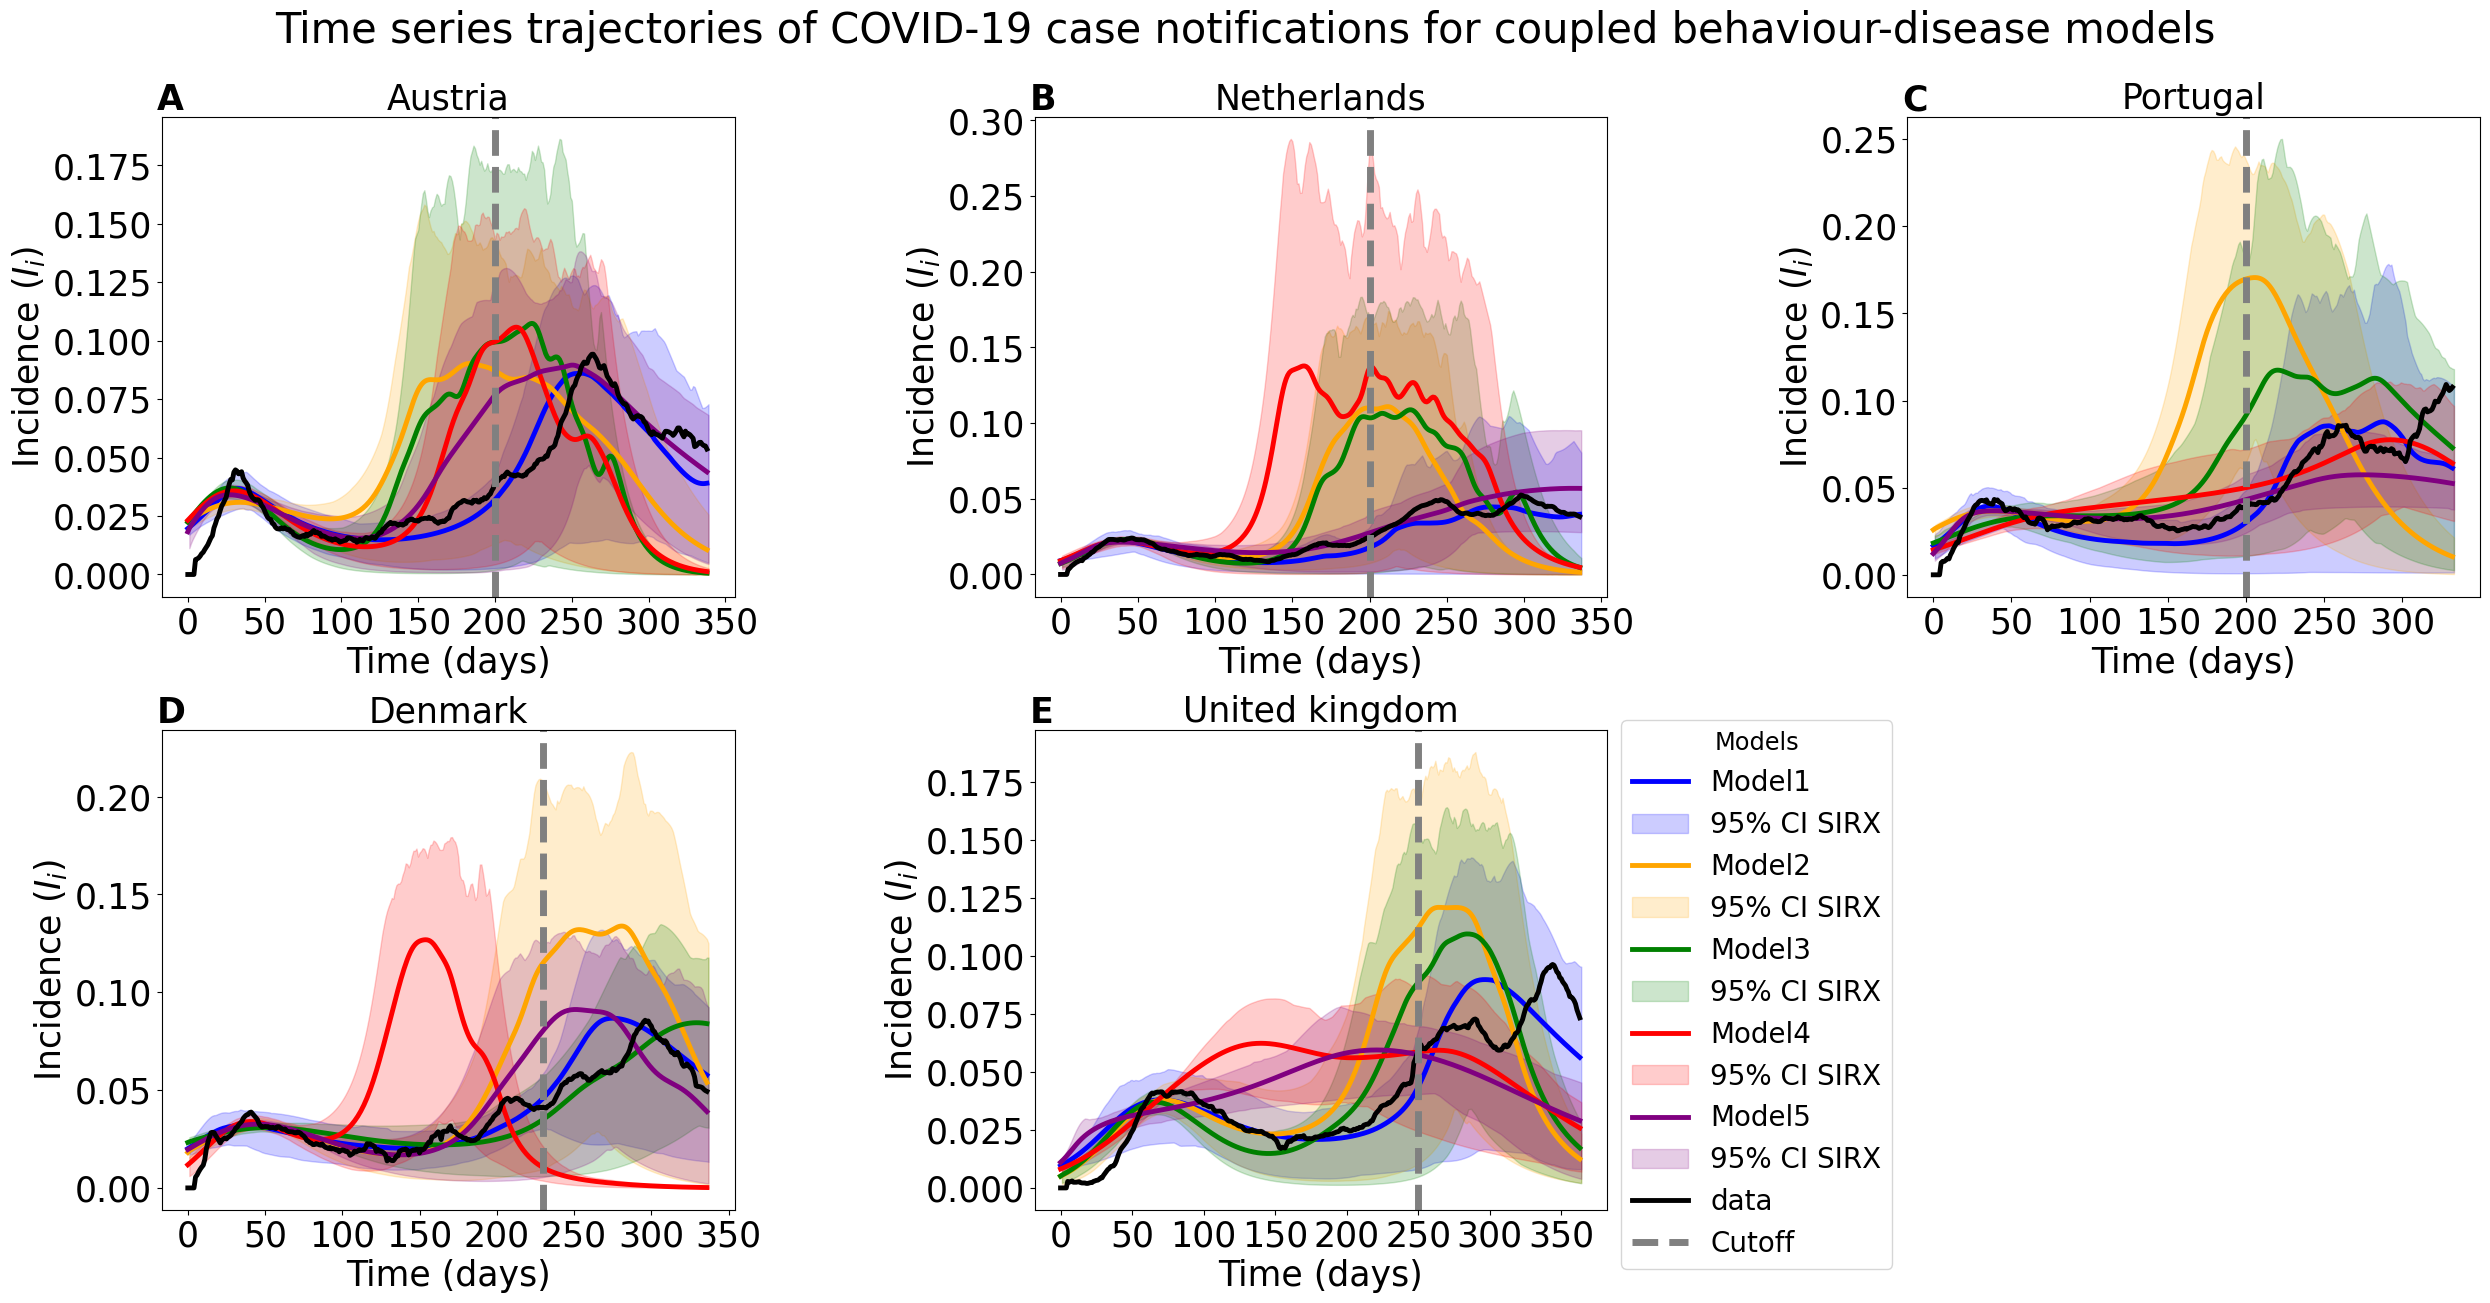

In [26]:
Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'uk']

Variant = [1, 0, 2, 3, 4] #Models [1, 2, 3, 4, 5]


austria_Vn = [0, 2, 2, 21, 7]
denmark_Vn = [0, 4, 3, 21, 4]
netherlands_Vn = [0, 6, 2, 21, 7]
portugal_Vn = [0, 4, 5, 26, 7]
uk_Vn = [0, 4, 4, 26, 3]

N = [austria_Vn, netherlands_Vn, portugal_Vn, denmark_Vn, uk_Vn]
Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
T = 100
# K = 12
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
ModelName = ["Model1", "Model2", "Model3", "Model4", "Model5", "SIR"]
# names = [names_austria, names_netherlands, names_portugal, names_denmark]
AA = [[], [], [], [], []]
k = 1
plt.figure(figsize=(25,13))
for filename in Filenames[:]:

    country = filename + "Avg7ma.csv"
    name = filename + "Avg.csv"
    data = pd.read_csv(Country_path_old + country)
    data = data[data.columns[1]]
    t_end = len(data)
    dataosi = pd.read_csv(Country_path_old + filename + "Avgosi7ma.csv")
    dataosi = dataosi[dataosi.columns[-1]][:t_end+1]
  
    # names_country = names[k-1]
    Cutoff = cutoff[name]
    NN = N[k-1]
    sir = []
    sirx = []
    
    t = np.arange(0, t_end+1)
    plt.subplot(2,3,k)
    for i in range(len(Variant)):
        variant = Variant[i]
        n = NN[i]
        c = colors[i]
        nn = ModelName[i]

        H = plot_simulation_country(filename, n, variant, T, c, nn, t_end, Cutoff)
        AA[k-1].append(H)

    plt.plot(np.arange(len(data[:])), np.cbrt(data[:]), label = 'data', color = 'black', linewidth = 3.5)
    # plt.plot(np.arange(len(dataosi[:])), np.cbrt(dataosi[:]), label = 'data', color = 'black', linewidth = 3.5)

    plt.axvline(x = Cutoff, color = 'grey', linestyle="--", linewidth = 5, label = 'Cutoff')
    # plt.plot(data[4:201+4], label = 'data', color = 'black', marker = "o",  linewidth = 2)
    # plt.yscale('log')
    plt.xlabel("Time (days)", fontsize = 25)
    plt.xticks(fontsize = 25)
    plt.yticks(fontsize = 25)
    # plt.ylabel("Mitigators $(X)$", fontsize = 25)
    plt.ylabel("Incidence $(I_i)$", fontsize = 25)
    plt.text(-0.01, 1.0, Labels[k-1], transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")
    if filename == "uk":
        filename = "United Kingdom"
    plt.title(f"{filename.capitalize()}", fontsize = 25)
    k += 1
plt.legend(bbox_to_anchor=(1.0, 1.05), loc='upper left', fontsize = 20, title="Models", title_fontsize='xx-large', ncols = 1)
# plt.suptitle("Time series trajectories of Oxford Stringency index for coupled behaviour-disease models", fontsize = 30, y = 1.0)
plt.suptitle("Time series trajectories of COVID-19 case notifications for coupled behaviour-disease models", fontsize = 30, y = 1.0)
plt.tight_layout()
# plt.savefig("Incidence_Revised.png", dpi = 300)
plt.show()

In [27]:
#Austria : 0, Denmark : 1, Netherlands : 2, Portugal : 3

def extract_peaks(AA, Country_index, Key_index):
    Stats_name = AA[0][0].keys()
    Stats_name = list(Stats_name)

    Peak_Fit = []
   

    for i in range(len(AA[0])):

        Peak_Fit.append(AA[Country_index][i][Stats_name[Key_index]])

    peaks0 = np.array([Peak_Fit[i][0][0] for i in range(len(Peak_Fit))])
    peaks1 = np.array([Peak_Fit[i][0][1] for i in range(len(Peak_Fit))])
    peaks2 = np.array([Peak_Fit[i][0][2] for i in range(len(Peak_Fit))])

    errors = np.vstack([np.abs(peaks0 - peaks1), peaks2 - peaks0])

    return peaks0, errors

In [28]:
Peaks_0_Austria, Error_bar_Austria = extract_peaks(AA, 0, Key_index = 1)
Peaks_0_Denmark, Error_bar_Denmark = extract_peaks(AA, 1, Key_index = 1)
Peaks_0_Netherlands, Error_bar_Netherlands = extract_peaks(AA, 2, Key_index = 1)
Peaks_0_Portugal, Error_bar_Portugal = extract_peaks(AA, 3, Key_index = 1)
Peaks_0_UK, Error_bar_UK = extract_peaks(AA, 4, Key_index = 1)


Peaks_1_Austria, Error_bart_Austria = extract_peaks(AA, 0, Key_index = 2)
Peaks_1_Denmark, Error_bart_Denmark = extract_peaks(AA, 1, Key_index = 2)
Peaks_1_Netherlands, Error_bart_Netherlands = extract_peaks(AA, 2, Key_index = 2)
Peaks_1_Portugal, Error_bart_Portugal = extract_peaks(AA, 3, Key_index = 2)
Peaks_1_UK, Error_bart_UK = extract_peaks(AA, 4, Key_index = 2)


In [29]:
Peaks_data = [cutoff_peak[name + "Avg.csv"][1] for name in Filenames[:5]]
Peaks_date = [cutoff_peak[name + "Avg.csv"][2] for name in Filenames[:5]]
Peaks_value = [cutoff_peak[name + "Avg.csv"][0] for name in Filenames[:5]]

[34 41 37 37 71] 31 Austria
[35 45 40 47 73] 46 Denmark
[28 44 79 53 67] 39 Netherlands
[ 31  40  79 109 129] 41 Portugal
[ 28  40  40  46 129] 84 United Kingdom


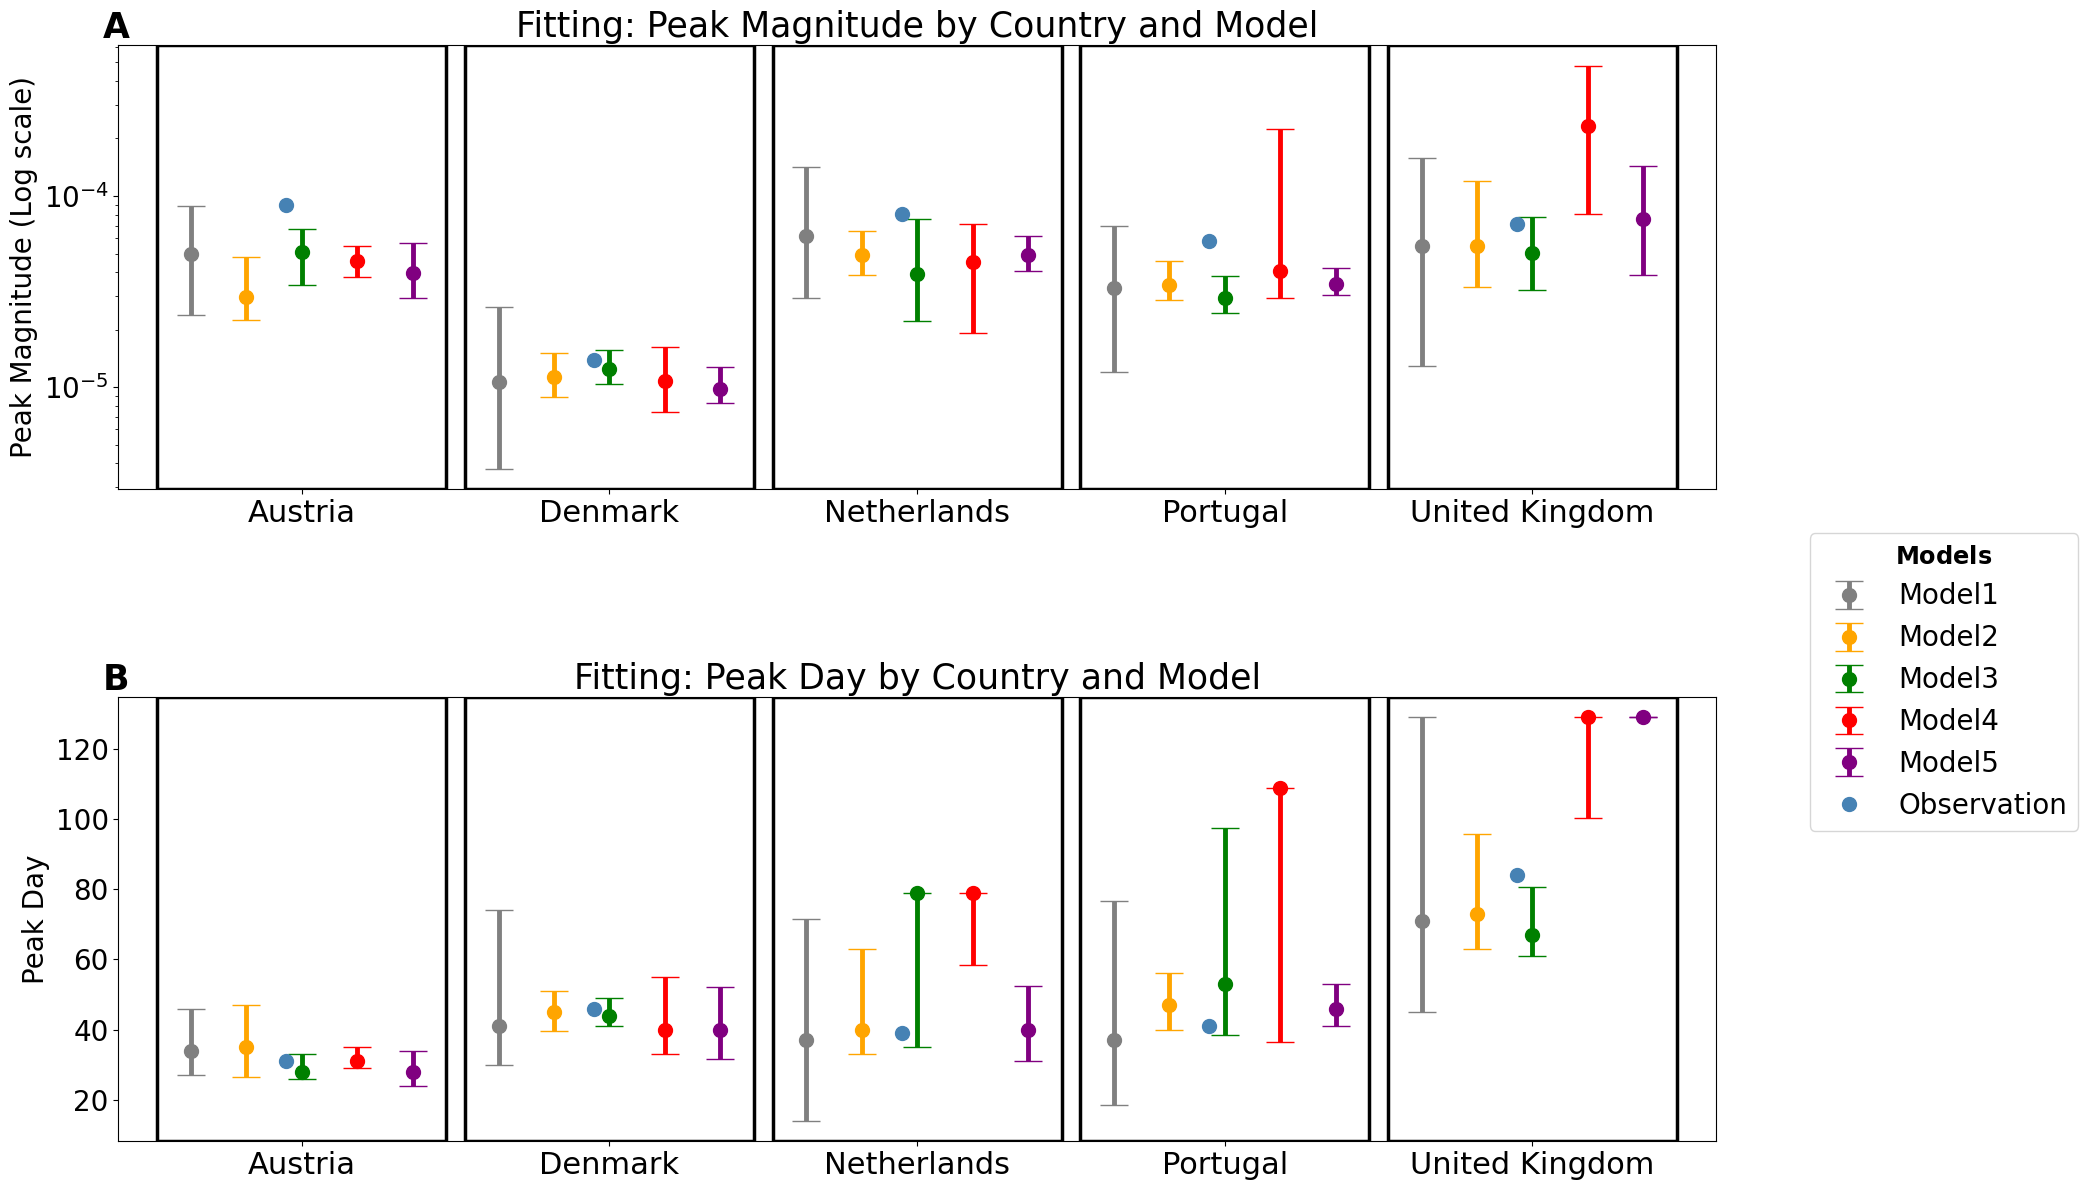

In [30]:
from matplotlib.patches import Rectangle

plt.figure(figsize=(21, 12))

countries = ["Austria", "Denmark", "Netherlands", "Portugal", "United Kingdom"]

# shape = (4 models,)
A = Peaks_0_Austria
D = Peaks_0_Denmark
N = Peaks_0_Netherlands
P = Peaks_0_Portugal
U = Peaks_0_UK

data = np.array([A, D, N, P, U])   # shape = (5 countries, 4 models)
# print(data.shape)

A1 = Peaks_1_Austria
D1 = Peaks_1_Denmark
N1 = Peaks_1_Netherlands
P1 = Peaks_1_Portugal
U1 = Peaks_1_UK

data1 = np.array([A1, D1, N1, P1, U1])   # shape = (5 countries, 4 models)

x = np.arange(5)   # 5 countries
width = 0.18                    # spacing between models
offset = 0.05

offsets = [-2*width, -1*width, 0*width, 1*width, 2*width]
models = ["Model1", "Model2", "Model3", "Model4", "Model5"]
colors = ["gray", "orange", "green", "red", "purple"]

errors = [Error_bar_Austria, Error_bar_Denmark, Error_bar_Netherlands, Error_bar_Portugal, Error_bar_UK]
errorst = [Error_bart_Austria, Error_bart_Denmark, Error_bart_Netherlands, Error_bart_Portugal, Error_bart_UK]
# print(errors)
# Loop over models

plt.subplot(2,1,1)
for j in range(5):
    y = data[:, j]
    # print(y, Peaks_value[j])
    yerr = np.vstack([errors[i][:, j] for i in range(5)]).T

    plt.errorbar(x + offsets[j], y, yerr=yerr, fmt='o', capsize=10, color=colors[j], label=models[j], linewidth =3.5, markersize = 10)
plt.errorbar(x - offset, np.array(Peaks_value), fmt='o', color='steelblue', label='Observation', linewidth =3.5, markersize = 10)
plt.xticks(x, countries, fontsize=22)
plt.yscale("log")
plt.yticks(fontsize=20)
plt.ylabel("Peak Magnitude (Log scale)", fontsize=20)
plt.title("Fitting: Peak Magnitude by Country and Model", fontsize=25)
plt.text(-0.01, 1.0, "$\\mathbf{A}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")

# plt.legend(title="Model")
# plt.tight_layout()

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='black',linewidth=2.5 )
    ax.add_patch(rect)


# plt.figure(figsize=(15, 5))
plt.subplot(2,1,2)
for j in range(5):
    y = data1[:, j]
    print(y, Peaks_data[j], countries[j])
    yerr = np.vstack([errorst[i][:, j] for i in range(5)]).T

    plt.errorbar(x + offsets[j], y, yerr=yerr, fmt='o', capsize=10, color=colors[j], label=models[j], linewidth =3.5, markersize = 10)
plt.errorbar(x - offset, np.array(Peaks_data), fmt='o', color='steelblue', label='Observation', linewidth =3.5, markersize = 10)
plt.xticks(x, countries, fontsize=22)
plt.yticks(fontsize=20)
plt.ylabel("Peak Day", fontsize=20)
plt.title("Fitting: Peak Day by Country and Model", fontsize=25)
plt.legend(bbox_to_anchor=(1.05, 1.4), loc='upper left', title="$\\mathbf{Models}$", fontsize=20, title_fontsize='xx-large')
plt.text(-0.01, 1.0, "$\\mathbf{B}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")

# print(countries, y, Peaks_data)

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='black',linewidth=2.5 )
    ax.add_patch(rect)

plt.tight_layout()
# plt.savefig("Fitting_Peak_Revised.png", dpi = 300)
plt.show()

In [31]:
Peaks_data = [pred_peak[name + "Avg.csv"][1] for name in Filenames[:5]]
Peaks_date = [pred_peak[name + "Avg.csv"][2] for name in Filenames[:5]]
Peaks_value = [pred_peak[name + "Avg.csv"][0] for name in Filenames[:5]]

In [32]:
Peaks_0_Austria, Error_bar_Austria = extract_peaks(AA, 0, Key_index = 3)
Peaks_0_Denmark, Error_bar_Denmark = extract_peaks(AA, 1, Key_index = 3)
Peaks_0_Netherlands, Error_bar_Netherlands = extract_peaks(AA, 2, Key_index = 3)
Peaks_0_Portugal, Error_bar_Portugal = extract_peaks(AA, 3, Key_index = 3)
Peaks_0_UK, Error_bar_UK = extract_peaks(AA, 4, Key_index = 3)

Peaks_1_Austria, Error_bart_Austria = extract_peaks(AA, 0, Key_index = 4)
Peaks_1_Denmark, Error_bart_Denmark = extract_peaks(AA, 1, Key_index = 4)
Peaks_1_Netherlands, Error_bart_Netherlands = extract_peaks(AA, 2, Key_index = 4)
Peaks_1_Portugal, Error_bart_Portugal = extract_peaks(AA, 3, Key_index = 4)
Peaks_1_UK, Error_bart_UK = extract_peaks(AA, 4, Key_index = 4)

[257 279 289 276 298] 264 Austria
[200 213 207 282 266] 298 Denmark
[225 227 221 330 286] 264 Netherlands
[215 202 293 230 265] 296 Portugal
[251 333 275 252 250] 333 United Kingdom


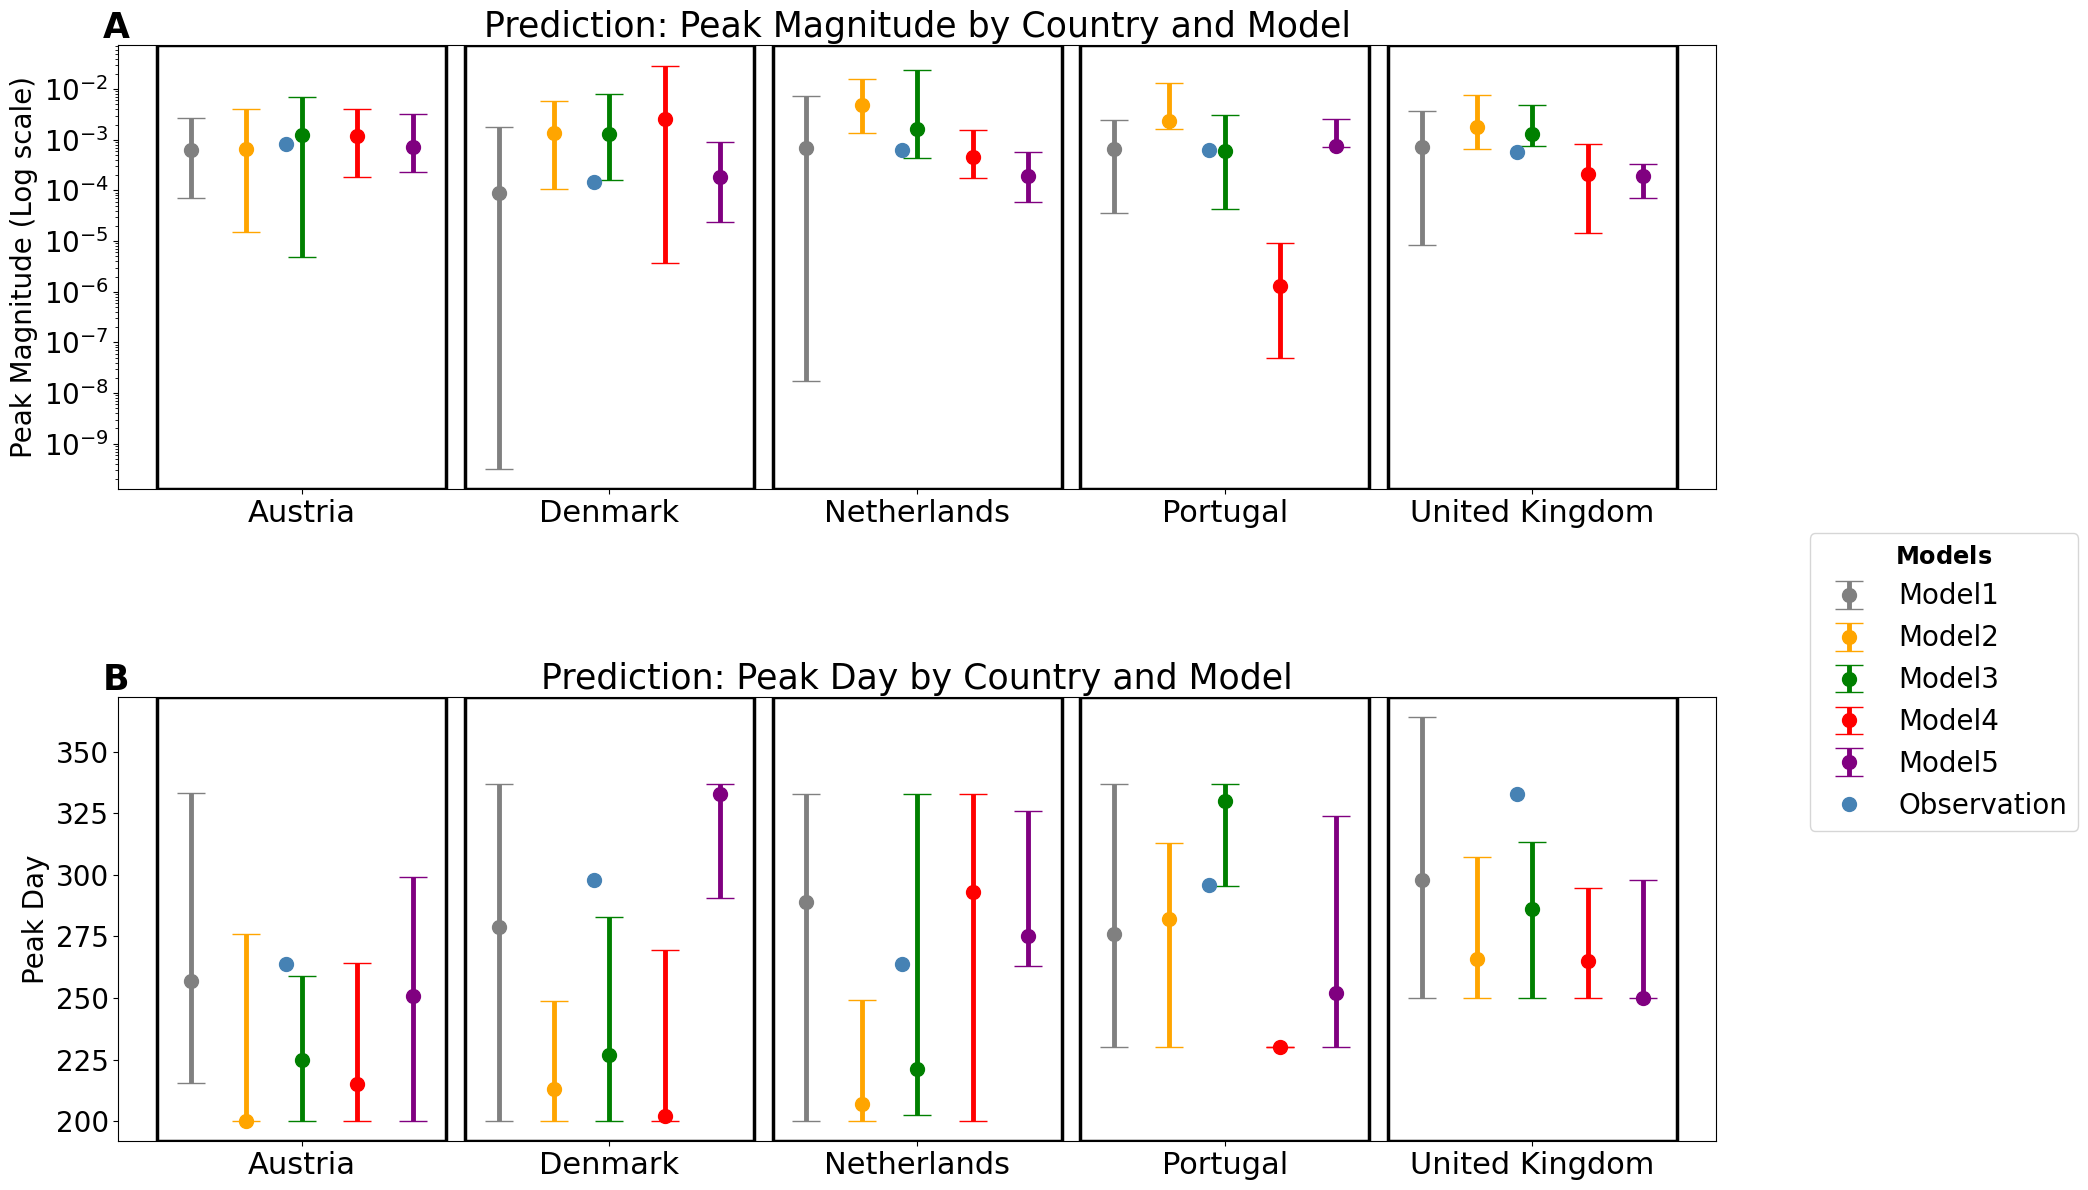

In [33]:
plt.figure(figsize=(21, 12))

# countries = ["Austria", "Denmark", "Netherlands", "Portugal"]

# shape = (4 models,)
A = Peaks_0_Austria
D = Peaks_0_Denmark
N = Peaks_0_Netherlands
P = Peaks_0_Portugal
U = Peaks_0_UK

data = np.array([A, D, N, P, U])   # shape = (4 countries, 4 models)
# print(data.shape)

A1 = Peaks_1_Austria
D1 = Peaks_1_Denmark
N1 = Peaks_1_Netherlands
P1 = Peaks_1_Portugal
U1 = Peaks_1_UK

data1 = np.array([A1, D1, N1, P1, U1])   # shape = (4 countries, 4 models)

x = np.arange(5)   # 5 countries
width = 0.18                    # spacing between models

offsets = [-2*width, -1*width, 0*width, 1*width, 2*width]
models = ["Model1", "Model2", "Model3", "Model4", "Model5"]
colors = ["gray", "orange", "green", "red", "purple"]

errors = [Error_bar_Austria, Error_bar_Denmark, Error_bar_Netherlands, Error_bar_Portugal, Error_bar_UK]
errorst = [Error_bart_Austria, Error_bart_Denmark, Error_bart_Netherlands, Error_bart_Portugal, Error_bart_UK]
# print(errors)
# Loop over models

plt.subplot(2,1,1)
for j in range(5):
    y = data[:, j]
    # print(y, Peaks_value[j])
    yerr = np.vstack([errors[i][:, j] for i in range(5)]).T

    plt.errorbar(x + offsets[j], y, yerr=yerr, fmt='o', capsize=10, color=colors[j], label=models[j], linewidth =3.5, markersize = 10)
plt.errorbar(x - offset, np.array(Peaks_value), fmt='o', color='steelblue', label='Observation', linewidth =3.5, markersize = 10)
plt.xticks(x, countries, fontsize=22)
plt.yscale("log")
plt.yticks(fontsize=20)
plt.ylabel("Peak Magnitude (Log scale)", fontsize=20)
plt.title("Prediction: Peak Magnitude by Country and Model", fontsize=25)
plt.text(-0.01, 1.0, "$\\mathbf{A}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")

# plt.legend(title="Model")
# plt.tight_layout()

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='black',linewidth=2.5 )
    ax.add_patch(rect)


# plt.figure(figsize=(15, 5))
plt.subplot(2,1,2)
for j in range(5):
    y = data1[:, j]
    print(y, Peaks_data[j], countries[j])
    yerr = np.vstack([errorst[i][:, j] for i in range(5)]).T

    plt.errorbar(x + offsets[j], y, yerr=yerr, fmt='o', capsize=10, color=colors[j], label=models[j], linewidth =3.5, markersize = 10)
plt.errorbar(x - offset, np.array(Peaks_data), fmt='o', color='steelblue', label='Observation', linewidth =3.5, markersize = 10)
plt.xticks(x, countries, fontsize=22)
plt.yticks(fontsize=20)
plt.ylabel("Peak Day", fontsize=20)
plt.title("Prediction: Peak Day by Country and Model", fontsize=25)
plt.legend(bbox_to_anchor=(1.05, 1.4), loc='upper left', title="$\\mathbf{Models}$", fontsize=20, title_fontsize='xx-large')
plt.text(-0.01, 1.0, "$\\mathbf{B}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")


ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='black',linewidth=2.5 )
    ax.add_patch(rect)

plt.tight_layout()
# plt.savefig("Prediction_Peak_revised.png", dpi = 300)
plt.show()

In [34]:
#Austria : 0, Denmark : 1, Netherlands : 2, Portugal : 3, UK : 4
Key_name = ["AiCC_Fit", "AiCCX_Fit", "AiCC_Pred", "AiCCX_Pred", "AREA_SIRX"]
def extract_aics(AA,Country_index, Key_name):
    AiCC = []
    for i in range(len(AA[Country_index])):
        AiCC.append(AA[Country_index][i][Key_name][0])
    return AiCC

In [35]:
Austria_AiC_Fit = extract_aics(AA, 0, "AiCC_Fit")
Austria_AiCX_Fit = extract_aics(AA, 0, "AiCCX_Fit")

Denmark_AiC_Fit = extract_aics(AA, 1, "AiCC_Fit")
Denmark_AiCX_Fit = extract_aics(AA, 1, "AiCCX_Fit")

Netherlands_AiC_Fit = extract_aics(AA, 2, "AiCC_Fit")
Netherlands_AiCX_Fit = extract_aics(AA, 2, "AiCCX_Fit")

Portugal_AiC_Fit = extract_aics(AA, 3, "AiCC_Fit")
Portugal_AiCX_Fit = extract_aics(AA, 3, "AiCCX_Fit")

UK_AiC_Fit = extract_aics(AA, 4, "AiCC_Fit")
UK_AiCX_Fit = extract_aics(AA, 4, "AiCCX_Fit")

Denmark_AiC_Pred = extract_aics(AA, 1, "AiCC_Pred")
Denmark_AiCX_Pred = extract_aics(AA, 1, "AiCCX_Pred")

Netherlands_AiC_Pred = extract_aics(AA, 2, "AiCC_Pred")
Netherlands_AiCX_Pred = extract_aics(AA, 2, "AiCCX_Pred")

Portugal_AiC_Pred = extract_aics(AA, 3, "AiCC_Pred")
Portugal_AiCX_Pred = extract_aics(AA, 3, "AiCCX_Pred")

Austria_AiC_Pred = extract_aics(AA, 0, "AiCC_Pred")
Austria_AiCX_Pred = extract_aics(AA, 0, "AiCCX_Pred")

UK_AiC_Pred = extract_aics(AA, 4, "AiCC_Pred")
UK_AiCX_Pred = extract_aics(AA, 4, "AiCCX_Pred")

Austria_AREA_SIRX = extract_aics(AA, 0, "AREA_SIRX")
Denmark_AREA_SIRX = extract_aics(AA, 1, "AREA_SIRX")
Netherlands_AREA_SIRX = extract_aics(AA, 2, "AREA_SIRX")
Portugal_AREA_SIRX = extract_aics(AA, 3, "AREA_SIRX")
UK_AREA_SIRX = extract_aics(AA, 4, "AREA_SIRX")


(5, 5)


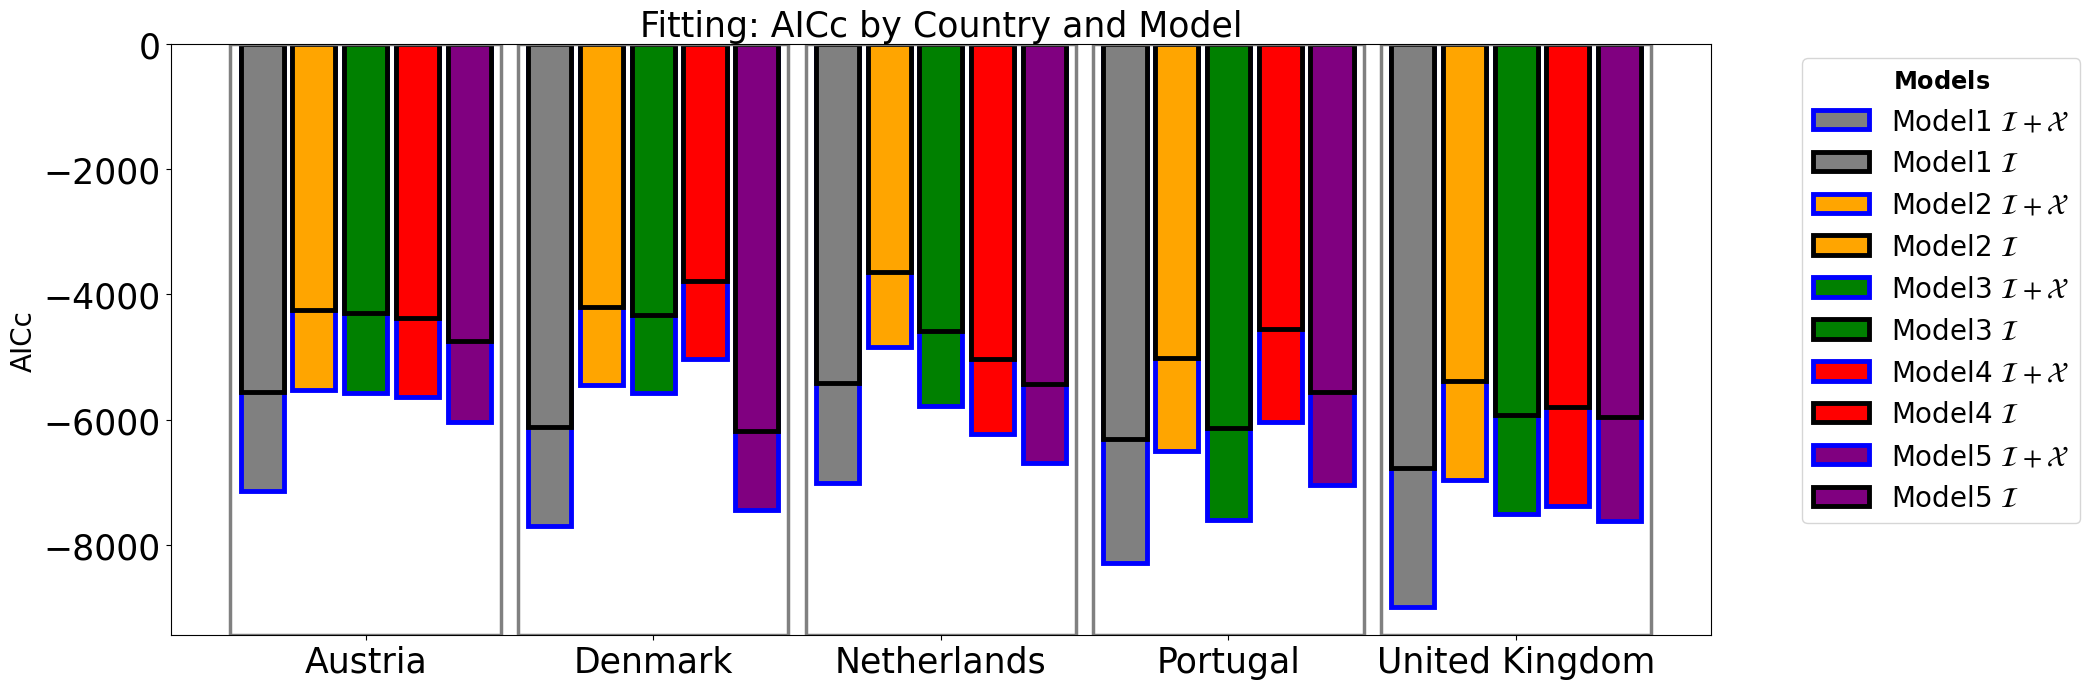

In [36]:
# from matplotlib.patches import Rectangle
# countries = ["Austria", "Denmark", "Netherlands", "Portugal", "UK"]

# shape = (4 models,)
A = Austria_AiC_Fit
D = Denmark_AiC_Fit
N = Netherlands_AiC_Fit
P = Portugal_AiC_Fit
U = UK_AiC_Fit

data = np.array([A, D, N, P, U])   # shape = (4 countries, 4 models)
print(data.shape)

A1 = np.array(Austria_AiC_Fit) + np.array(Austria_AiCX_Fit)
D1 = np.array(Denmark_AiC_Fit) + np.array(Denmark_AiCX_Fit)
N1 = np.array(Netherlands_AiC_Fit) + np.array(Netherlands_AiCX_Fit)
P1 = np.array(Portugal_AiC_Fit) + np.array(Portugal_AiCX_Fit)
U1 = np.array(UK_AiC_Fit) + np.array(UK_AiCX_Fit)

data1 = np.array([A1, D1, N1, P1, U1])   # shape = (4 countries, 4 models)

x = np.arange(5)   # 5 countries
width = 0.18                    # spacing between models
offset = 0.05

offsets = [-2*width, -1*width, 0*width, 1*width, 2*width]
models = ["Model1", "Model2", "Model3", "Model4", "Model5"]
colors = ["gray", "orange", "green", "red", "purple"]

# errors = [Error_bar_Austria, Error_bar_Denmark, Error_bar_Netherlands, Error_bar_Portugal]
# errorst = [Error_bart_Austria, Error_bart_Denmark, Error_bart_Netherlands, Error_bart_Portugal] 
# print(errors)
# Loop over models

# plt.subplot(2,1,1)
plt.figure(figsize=(21, 7))
for j in range(5):
    y = data[:, j]
    y1 = data1[:, j]

    # print(data[j, : ])
    # print(y)
    # yerr = np.vstack([errors[i][:, j] for i in range(4)]).T
    plt.bar(np.arange(5)+offsets[j], y1, 0.15, color=colors[j], align='center', edgecolor='blue', linewidth=3.5, label = models[j] + " $\\mathcal{I + X}$")
    plt.bar(np.arange(5)+offsets[j], y, 0.15, color=colors[j], align='center', edgecolor='black', linewidth=3.5, label = models[j] + " $\\mathcal{I}$")


plt.xticks(x, countries, fontsize=25)
# plt.yscale("log")
plt.yticks(fontsize=25)
plt.ylabel("AICc", fontsize=20)
plt.title("Fitting: AICc by Country and Model", fontsize=25)
# plt.text(-0.01, 1.0, "$\\mathbf{A}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', title="$\\mathbf{Models}$", fontsize=20, title_fontsize='xx-large')
plt.tight_layout()

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='grey',linewidth=2.5 )
    ax.add_patch(rect)
plt.tight_layout()
# plt.savefig("Fitting_AIC_revised.png", dpi = 300)
plt.show()


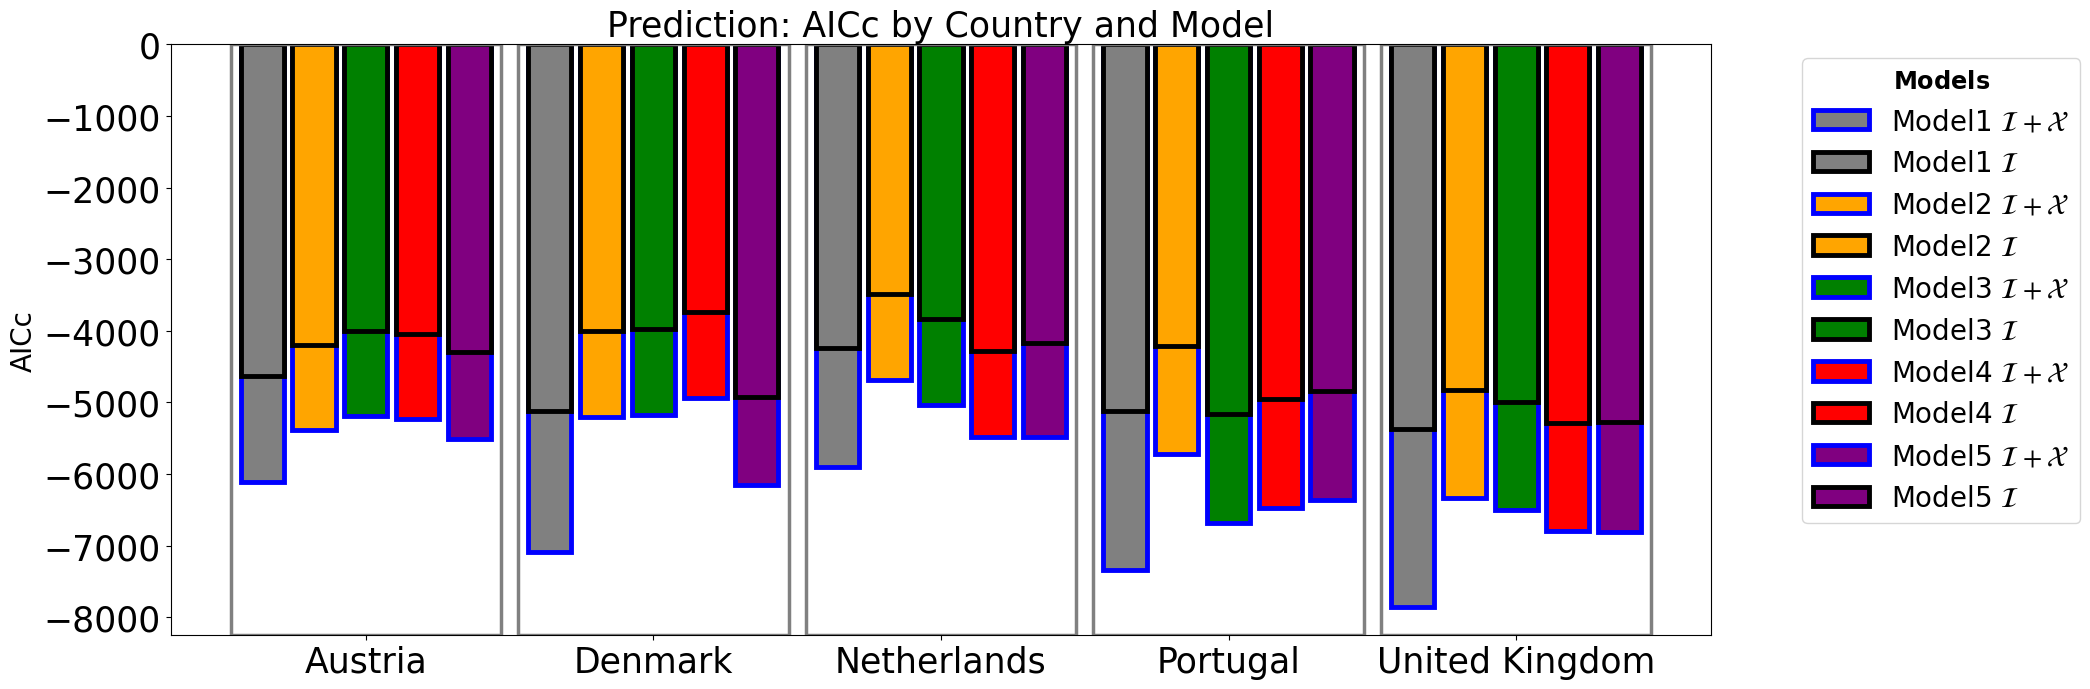

In [37]:
# countries = ["Austria", "Denmark", "Netherlands", "Portugal"]

# shape = (4 models,)
A = Austria_AiC_Pred
D = Denmark_AiC_Pred
N = Netherlands_AiC_Pred
P = Portugal_AiC_Pred
U = UK_AiC_Pred

data = np.array([A, D, N, P, U])   # shape = (4 countries, 4 models)
# print(data.shape)

A1 = np.array(Austria_AiC_Pred) + np.array(Austria_AiCX_Pred)
D1 = np.array(Denmark_AiC_Pred) + np.array(Denmark_AiCX_Pred)
N1 = np.array(Netherlands_AiC_Pred) + np.array(Netherlands_AiCX_Pred)
P1 = np.array(Portugal_AiC_Pred) + np.array(Portugal_AiCX_Pred)
U1 = np.array(UK_AiC_Pred) + np.array(UK_AiCX_Pred)

data1 = np.array([A1, D1, N1, P1, U1])   # shape = (4 countries, 4 models)

x = np.arange(5)   # 5 countries
width = 0.18                    # spacing between models
offset = 0.05

offsets = [-2*width, -1*width, 0*width, 1*width, 2*width]
models = ["Model1", "Model2", "Model3", "Model4", "Model5"]
colors = ["gray", "orange", "green", "red", "purple"]

# errors = [Error_bar_Austria, Error_bar_Denmark, Error_bar_Netherlands, Error_bar_Portugal]
# errorst = [Error_bart_Austria, Error_bart_Denmark, Error_bart_Netherlands, Error_bart_Portugal] 
# print(errors)
# Loop over models

# plt.subplot(2,1,1)
plt.figure(figsize=(21, 7))
for j in range(5):
    y = data[:, j]
    y1 = data1[:, j]

    # print(data[j, : ])
    # print(y1)
    # yerr = np.vstack([errors[i][:, j] for i in range(4)]).T
    plt.bar(np.arange(5)+offsets[j], y1, 0.15, color=colors[j], align='center', edgecolor='blue', linewidth=3.5, label = models[j] + " $\\mathcal{I + X}$")
    plt.bar(np.arange(5)+offsets[j], y, 0.15, color=colors[j], align='center', edgecolor='black', linewidth=3.5, label = models[j] + " $\\mathcal{I}$")


plt.xticks(x, countries, fontsize=25)
# plt.yscale("log")
plt.yticks(fontsize=25)
plt.ylabel("AICc", fontsize=20)
plt.title("Prediction: AICc by Country and Model", fontsize=25)
# plt.text(-0.01, 1.0, "$\\mathbf{A}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', title="$\\mathbf{Models}$", fontsize=20, title_fontsize='xx-large')
plt.tight_layout()

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='grey',linewidth=2.5 )
    ax.add_patch(rect)
plt.tight_layout()
# plt.savefig("Prediction_AIC_revised.png", dpi = 300)
plt.show()


(5, 5)


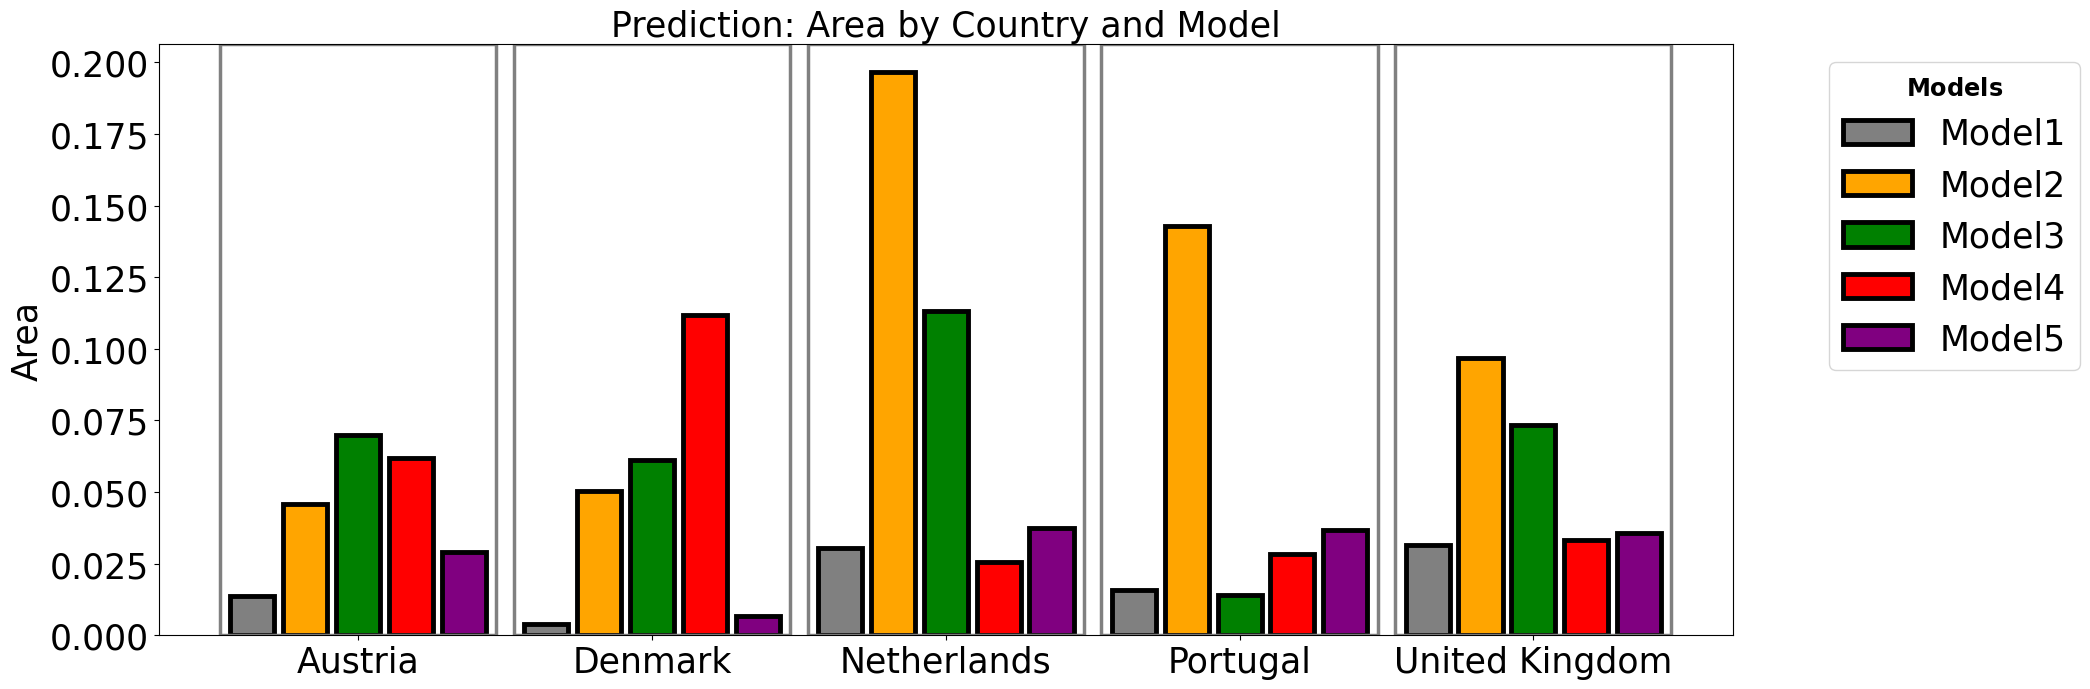

In [38]:
# countries = ["Austria", "Denmark", "Netherlands", "Portugal"]

# shape = (4 models,)
A = Austria_AREA_SIRX
D = Denmark_AREA_SIRX
N = Netherlands_AREA_SIRX
P = Portugal_AREA_SIRX
U = UK_AREA_SIRX

data = np.array([A, D, N, P, U])   # shape = (4 countries, 4 models)
print(data.shape)

# A1 = np.array(Austria_AiC_Pred) + np.array(Austria_AiCX_Pred)
# D1 = np.array(Denmark_AiC_Pred) + np.array(Denmark_AiCX_Pred)
# N1 = np.array(Netherlands_AiC_Pred) + np.array(Netherlands_AiCX_Pred)
# P1 = np.array(Portugal_AiC_Pred) + np.array(Portugal_AiCX_Pred)

# data1 = np.array([A1, D1, N1, P1])   # shape = (4 countries, 4 models)

x = np.arange(5)   # 5 countries
width = 0.18                    # spacing between models
offset = 0.05

offsets = [-2*width, -1*width, 0*width, 1*width, 2*width]
models = ["Model1", "Model2", "Model3", "Model4", "Model5"]
colors = ["gray", "orange", "green", "red", "purple"]

# errors = [Error_bar_Austria, Error_bar_Denmark, Error_bar_Netherlands, Error_bar_Portugal]
# errorst = [Error_bart_Austria, Error_bart_Denmark, Error_bart_Netherlands, Error_bart_Portugal] 
# print(errors)
# Loop over models

# plt.subplot(2,1,1)
plt.figure(figsize=(21, 7))
for j in range(5):
    y = data[:, j]
    # y1 = data1[:, j]

    # print(data[j, : ])
    # print(y)
    # yerr = np.vstack([errors[i][:, j] for i in range(4)]).T
    # plt.bar(np.arange(4)+offsets[j], y1, 0.15, color=colors[j], align='center', edgecolor='blue', linewidth=3.5, label = models[j] + " $\\mathcal{I + X}$")
    plt.bar(np.arange(5)+offsets[j], y, 0.15, color=colors[j], align='center', edgecolor='black', linewidth=3.5, label = models[j])


plt.xticks(x, countries, fontsize=25)
# plt.yscale("log")
plt.yticks(fontsize=25)
plt.ylabel("Area", fontsize=25)
plt.title("Prediction: Area by Country and Model", fontsize=25)
# plt.text(-0.01, 1.0, "$\\mathbf{A}$", transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left', title="$\\mathbf{Models}$", fontsize=25, title_fontsize='xx-large')
plt.tight_layout()

ax = plt.gca()
ymin, ymax = ax.get_ylim()

group_width = 5 * width

for xi in x:
    rect = Rectangle( (xi - group_width/2 - 0.02, ymin), group_width + 0.04,  ymax - ymin,
        fill=False, edgecolor='grey',linewidth=2.5 )
    ax.add_patch(rect)
plt.tight_layout()
# plt.savefig("Prediction_Area_revised.png", dpi = 300)
plt.show()


In [42]:
def particle_extraction(filename, n, variant):

    if variant == 0: #Model 2
        data = pd.read_csv(country_particle_path + f"{filename}_{n}_v2_final_revised.csv")
        data.rename(columns={'Ii0': 'C0'}, inplace=True)

    if variant == 1: #Model 1
        # Particle_Sirx_eta = Pop_negative(filename + "_final_par.csv", 0, 200, t_end)
        data = pd.read_csv(country_particle_path + filename + "_final_par.csv")
        data.rename(columns={'eta_0': 'eta'}, inplace=True)

    if variant == 2: #Model 3
        data = pd.read_csv(country_particle_path + f"{filename}_{n}_v3_final_revised.csv")
        data.rename(columns={'Ii0': 'C0'}, inplace=True)

    if variant == 3: #Model 4
        data = pd.read_csv(country_particle_path + f"{filename}_{n}_v3_final.csv")
        data.rename(columns={'Ii0': 'C0'}, inplace=True)

    if variant == 4: #Model 5
        data = pd.read_csv(country_particle_path + f"{filename}_{n}_v5_final_revised.csv")
        data.rename(columns={'Ii0': 'C0'}, inplace=True)

    
    return data
 

<Figure size 2500x1300 with 0 Axes>

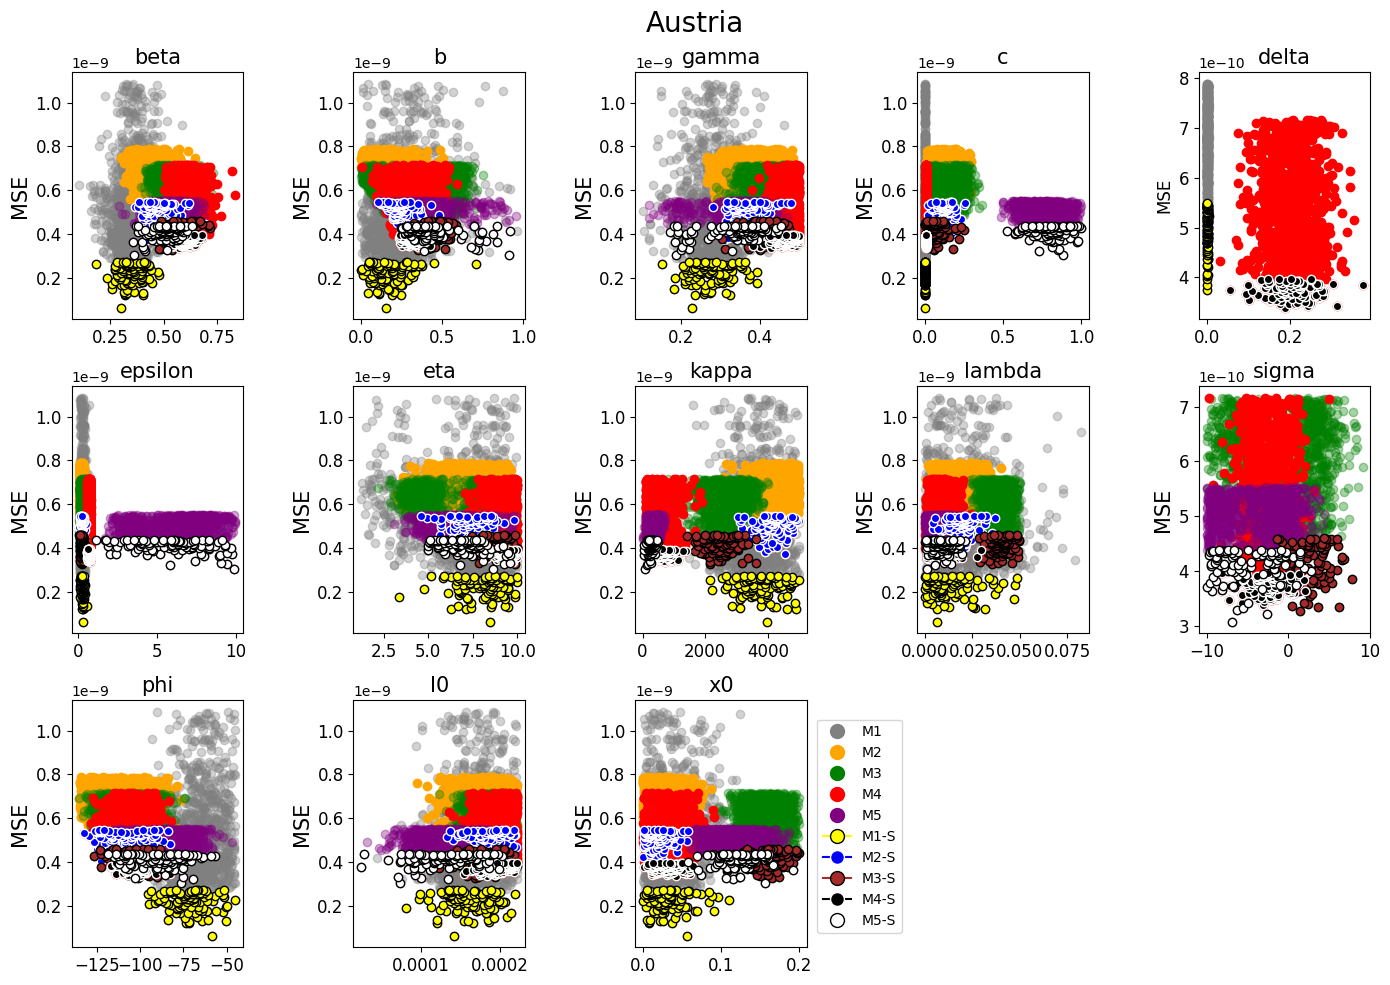

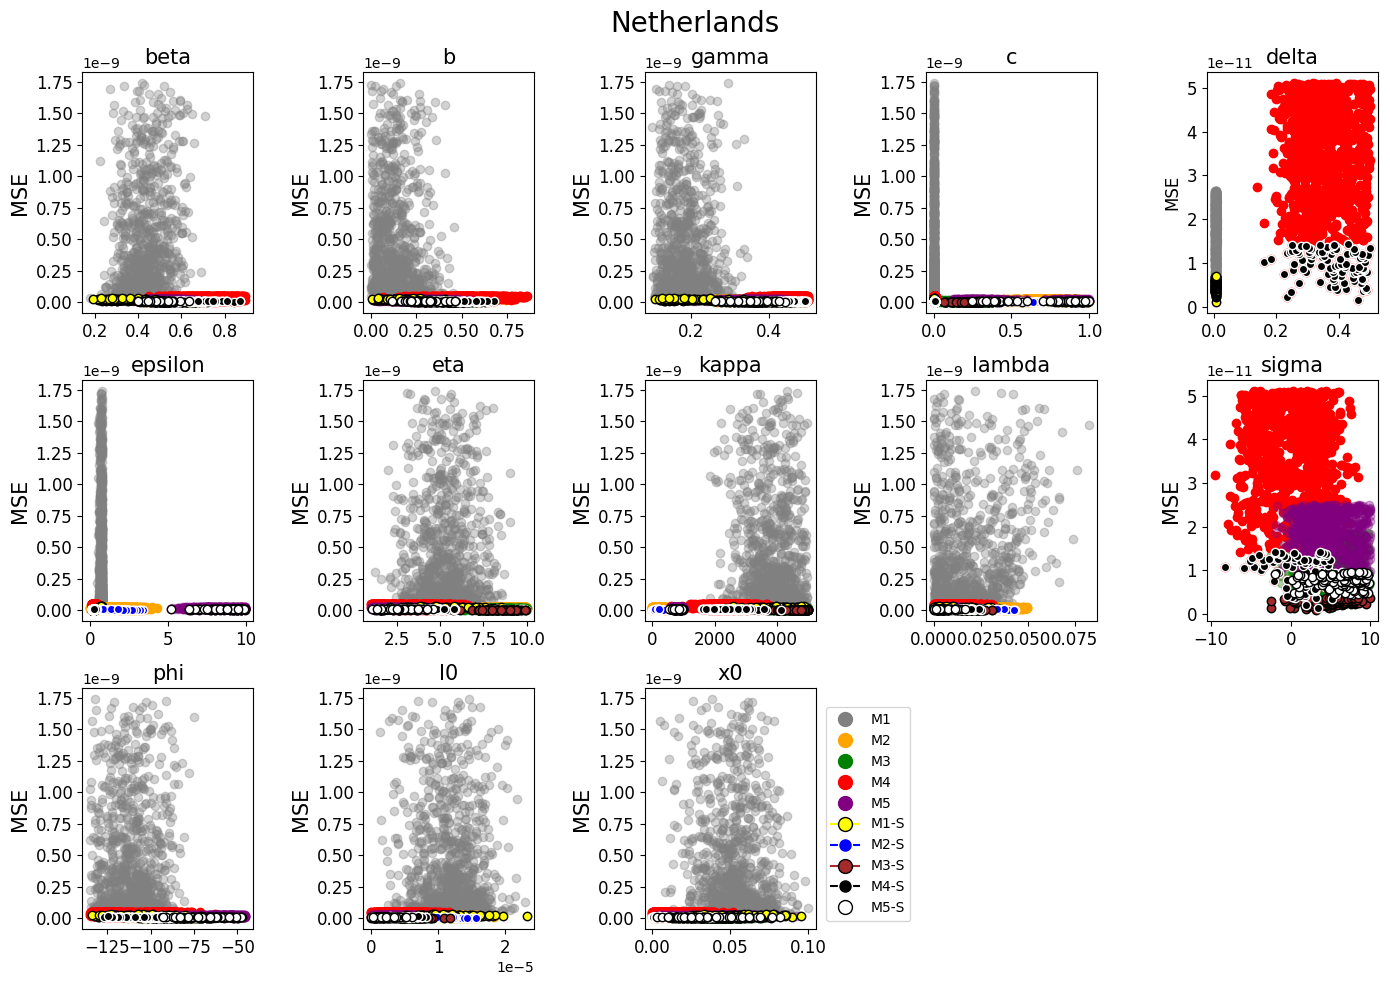

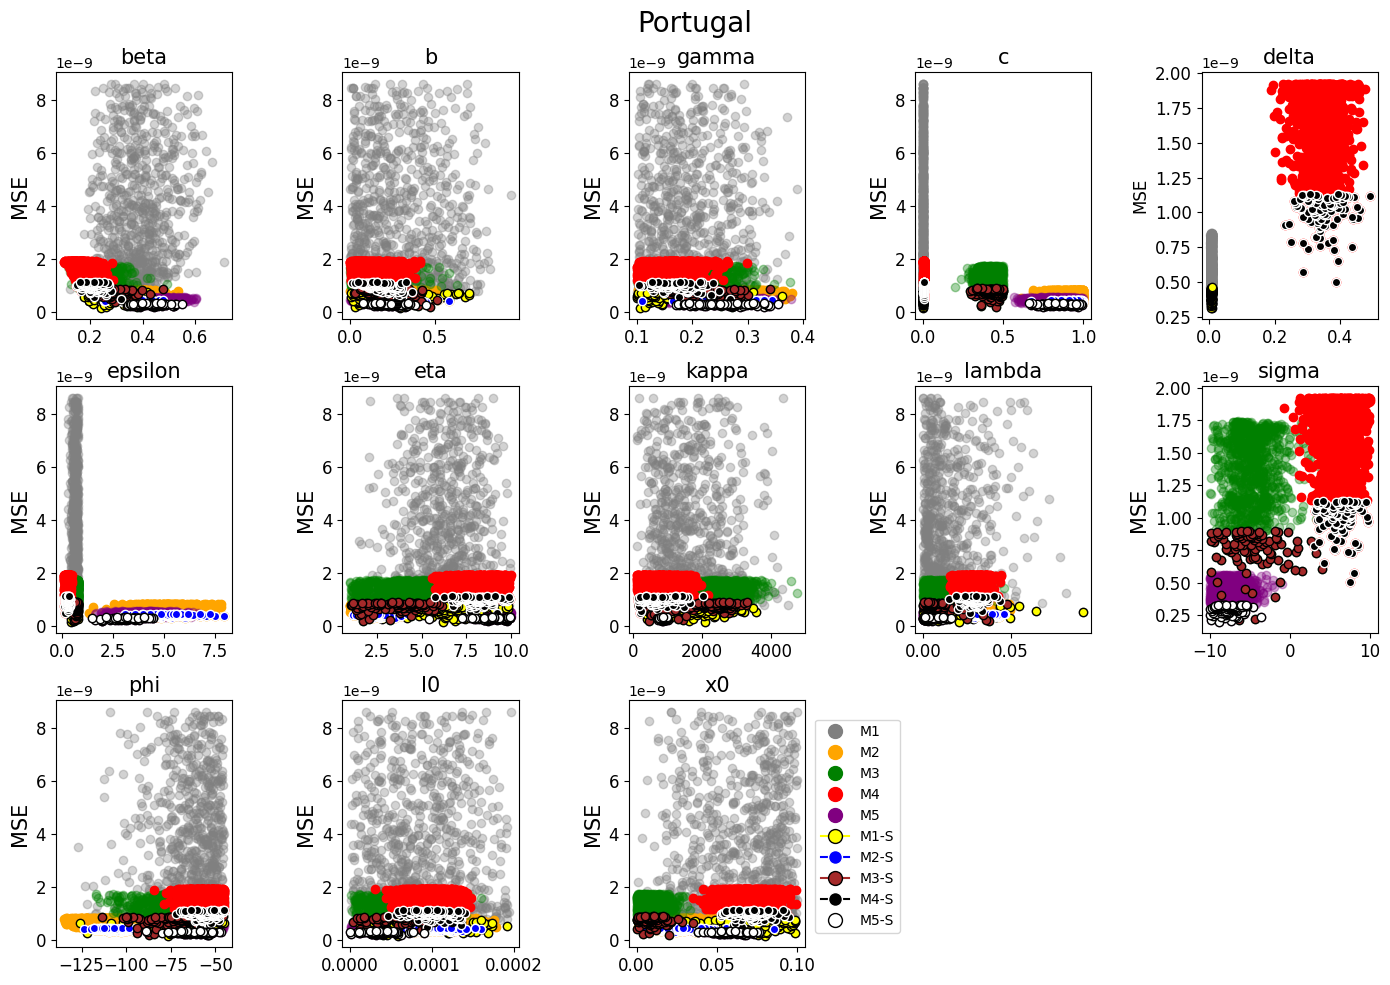

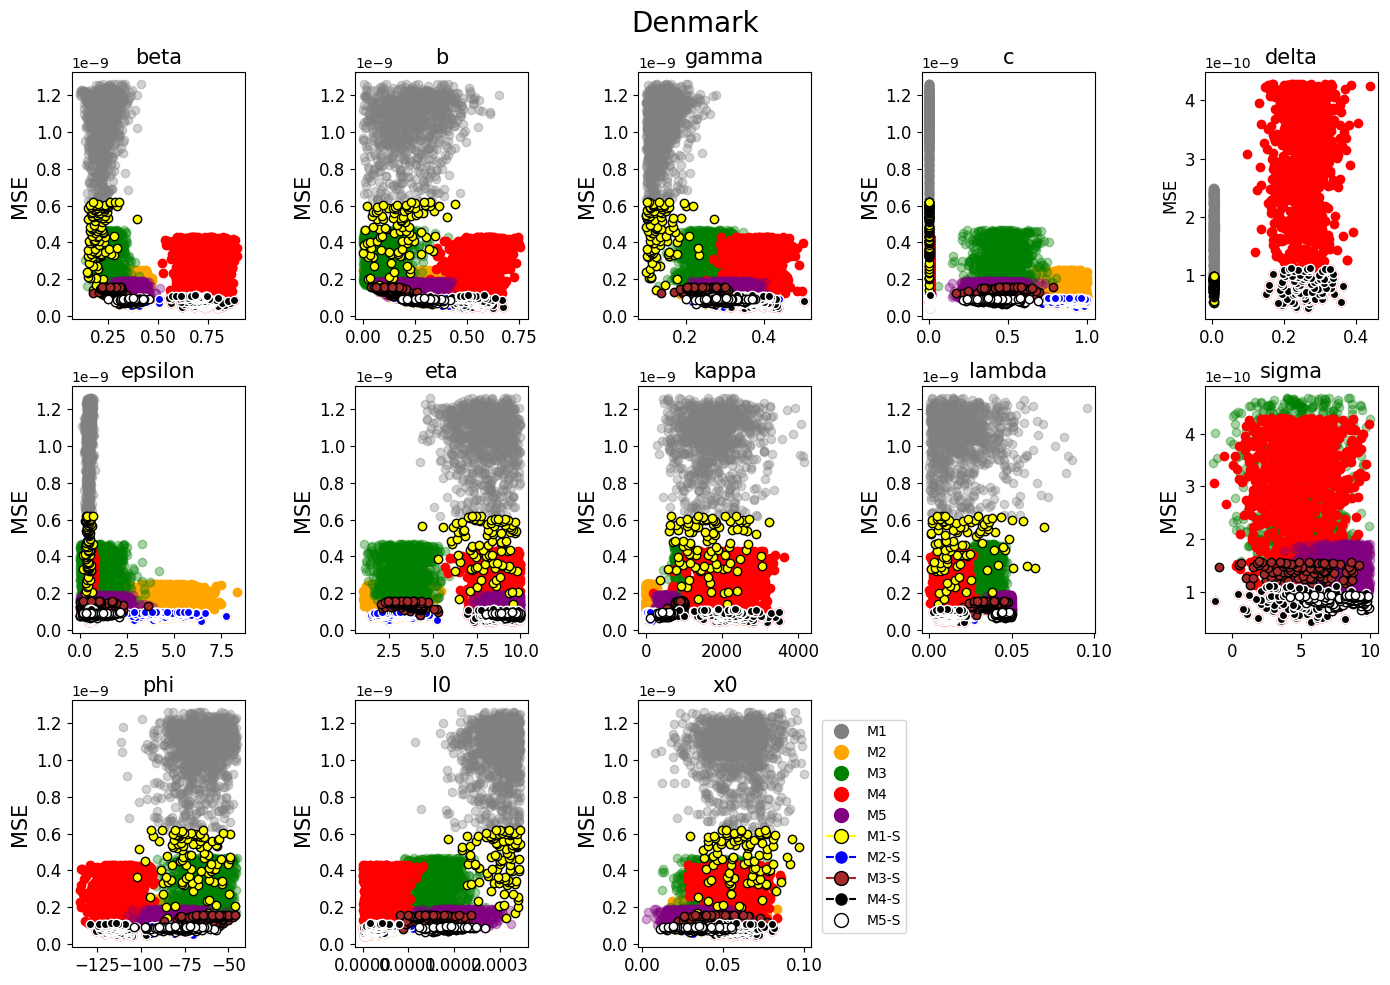

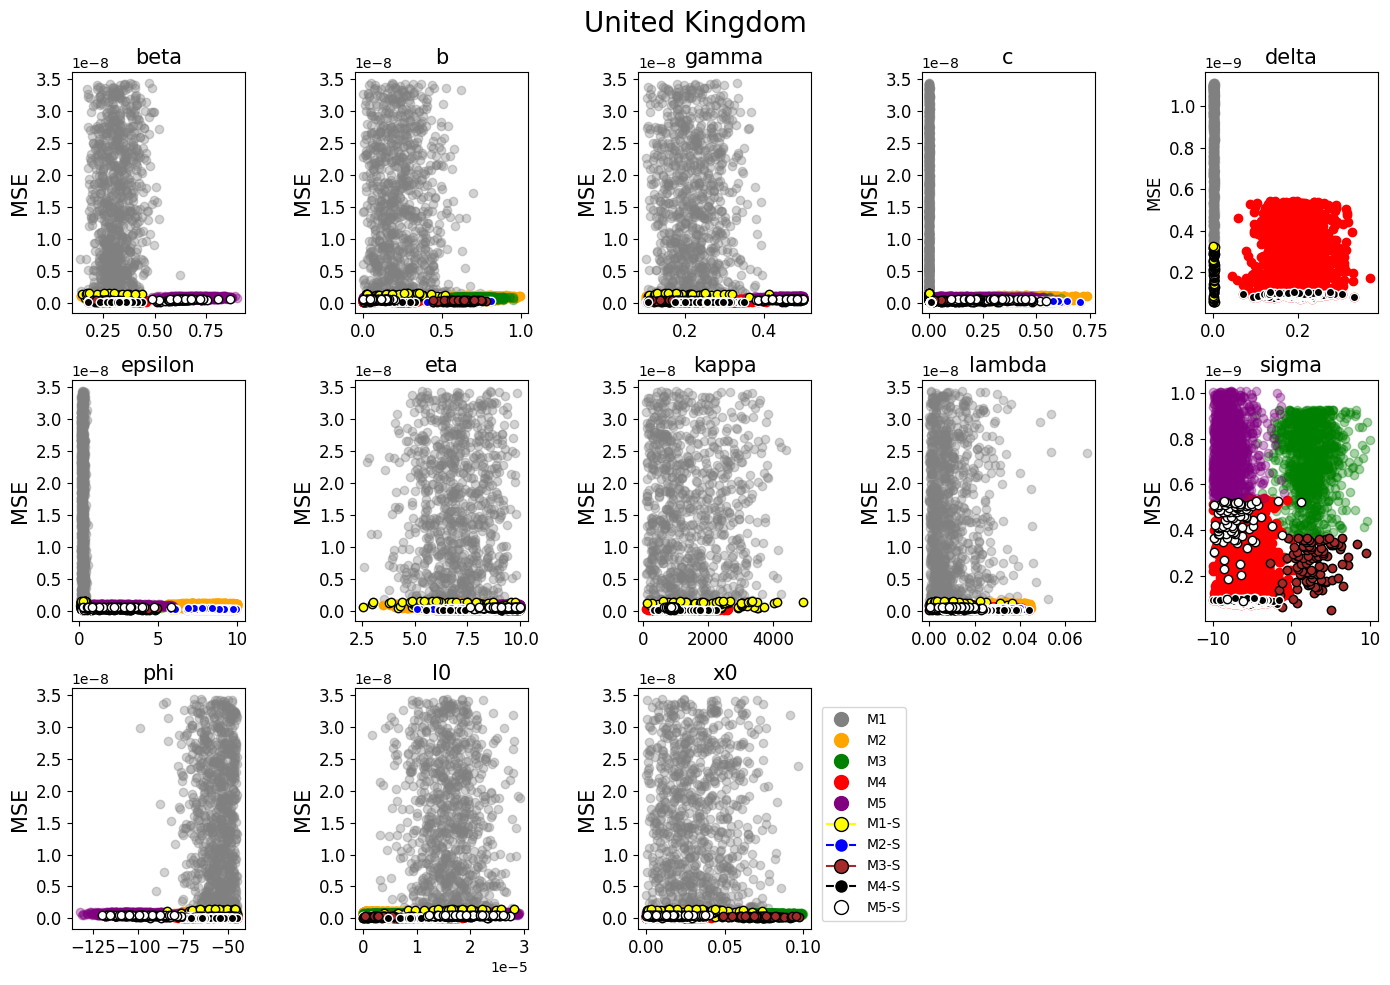

In [43]:
import seaborn as sns
Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'uk']
M1 = np.random.choice(['M1'], size=1000)
M2 = np.random.choice(['M2'], size=1000)
M3 = np.random.choice(['M3'], size=1000)
M4 = np.random.choice(['M4'], size=1000)
M5 = np.random.choice(['M5'], size=1000)

category = np.concatenate([M1, M2, M3, M4, M5])

column_names = ['b', 'gamma', 'c', 'eta_0', 'epsilon', 'eta_1', 'kappa', 'lambda',
       'phi', 'I0', 'x0', 'C0']
column_unit = {"beta":" ", 'b': " (/mm)",'phi':" (/degrees)", "gamma":" (/days)", "kappa":" (/days)",
                'c':" ", 'eta_0': " ", 'epsilon': " ", 'eta_1': " ", 'I0':" ", 'lambda':" ",
         'x0':" ", 'C0': " "}

Variant = [1, 0, 2, 3, 4]

austria_Vn = [0, 2, 2, 21, 7]
denmark_Vn = [0, 4, 3, 21, 4]
netherlands_Vn = [0, 6, 2, 21, 7]
portugal_Vn = [0, 4, 5, 26, 7]
uk_Vn = [0, 4, 4, 26, 3]

N = [austria_Vn, netherlands_Vn, portugal_Vn, denmark_Vn, uk_Vn]
Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
T = 100
# K = 12
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
ModelName = ["Model1", "Model2", "Model3", "Model4", "Model5", "SIR"]
AA = [[], [], [], [], []]
k = 1
plt.figure(figsize=(25,13))
for filename in Filenames[:]:

    NN = N[k-1]

    data_base1 = particle_extraction(filename, NN[0], 1)
    data_base0 = particle_extraction(filename, NN[1], 0)
    data_base2 = particle_extraction(filename, NN[2], 2)
    data_base3 = particle_extraction(filename, NN[3], 3)
    data_base4 = particle_extraction(filename, NN[4], 4)

    i = 0
    plt.figure(figsize=(14, 10))
    if filename[:] == "uk":
        header = "United Kingdom"
    else:
        header = filename[:].capitalize()
    plt.suptitle(header, fontsize = 20)
    for par in data_base0.columns[2:-2]:
        plt.subplot(3,5,i+1)
        if par in data_base0.columns[:] and par in data_base1.columns[:] and par in data_base2.columns[:] and par in data_base3.columns[:] and par in data_base4.columns[:]:
            plt.scatter(data_base1[par][:1000], data_base1['Error_I'][:1000], color = 'grey', alpha = 0.35)
            plt.scatter(data_base0[par][:1000], data_base0['Error_I'][:1000], color = 'orange')
            plt.scatter(data_base2[par][:1000], data_base2['Error_I'][:1000], color = 'green', alpha = 0.35)
            plt.scatter(data_base3[par][:1000], data_base3['Error_I'][:1000], color = 'red')
            # if par == "epsilon":
            #     plt.scatter(data_base4[par][:1000]/1000, data_base4['Error_I'][:1000], color = 'purple', alpha = 0.35, label = "SIRX")
            plt.scatter(data_base4[par][:1000], data_base4['Error_I'][:1000], color = 'purple', alpha = 0.35)

            plt.scatter(data_base1[par][:100], data_base1['Error_I'][:100], color = 'yellow', edgecolors='black')
            plt.scatter(data_base0[par][:100], data_base0['Error_I'][:100], color = 'blue',  edgecolors='white')
            plt.scatter(data_base2[par][:100], data_base2['Error_I'][:100], color = 'brown', edgecolors='black')
            plt.scatter(data_base3[par][:100], data_base3['Error_I'][:100], color = 'black',  edgecolors='white')
            plt.scatter(data_base4[par][:100], data_base4['Error_I'][:100], color = 'white', edgecolors='black')

            plt.ylabel('MSE', fontsize = 15)
            plt.xticks(fontsize = 12)
            plt.yticks(fontsize = 12)
            plt.title(par,  fontsize = 15)
            
        elif par == "sigma":
            plt.scatter(data_base2[par][:1000], data_base2['Error_I'][:1000], color = 'green', alpha = 0.35)
            plt.scatter(data_base3[par][:1000], data_base3['Error_I'][:1000], color = 'red')
            plt.scatter(data_base4[par][:1000], data_base4['Error_I'][:1000], color = 'purple', alpha = 0.35)

            plt.scatter(data_base2[par][:100], data_base2['Error_I'][:100], color = 'brown', edgecolors='black')
            plt.scatter(data_base3[par][:100], data_base3['Error_I'][:100], color = 'black',  edgecolors='white')
            plt.scatter(data_base4[par][:100], data_base4['Error_I'][:100], color = 'white', edgecolors='black')

            plt.ylabel('MSE', fontsize = 15)
            plt.xticks(fontsize = 12)
            plt.yticks(fontsize = 12)
            plt.title(par,  fontsize = 15)

        elif par == "delta":
            plt.scatter(data_base0[par][:1000], data_base0['Error_I'][:1000], color = 'grey', alpha = 0.35)
            # plt.scatter(data_base2[par][:1000], data_base2['Error_I'][:1000], color = 'green', alpha = 0.35)
            plt.scatter(data_base3[par][:1000], data_base3['Error_I'][:1000], color = 'red')

            plt.scatter(data_base0[par][:100], data_base0['Error_I'][:100], color = 'yellow', edgecolors='black')
            # plt.scatter(data_base2[par][:100], data_base2['Error_I'][:100], color = 'brown', edgecolors='black')
            plt.scatter(data_base3[par][:100], data_base3['Error_I'][:100], color = 'black',  edgecolors='white')

            plt.ylabel('MSE', fontsize = 12)
            plt.xticks(fontsize = 12)
            plt.yticks(fontsize = 12)
            plt.title(par,  fontsize = 15)

        i +=1
    delta_handles = [
        plt.Line2D([0], [0], color='grey', marker='o', linestyle='None', markersize=10),  
        plt.Line2D([0], [0], color='orange', marker='o', linestyle='None', markersize=10),  # Observation
        plt.Line2D([0], [0], color='green', marker='o', linestyle='None', markersize=10),  # Observation
        plt.Line2D([0], [0], color='red', marker='o', linestyle='None', markersize=10),  # Observation
        plt.Line2D([0], [0], color='purple', marker='o', linestyle='None', markersize=10),  # Observation

        plt.Line2D([0], [0], color='yellow', marker='o', markeredgecolor='black', markersize=10),              
        plt.Line2D([0], [0], color='blue', marker='o', markeredgecolor='white', markersize=10),                
        plt.Line2D([0], [0], color='brown', marker='o', markeredgecolor='black', markersize=10),              
        plt.Line2D([0], [0], color='black', marker='o', markeredgecolor='white', markersize=10),
        plt.Line2D([0], [0], color='white', marker='o', markeredgecolor='black', markersize=10) 
                ]

    Da = ["M1", "M2","M3", "M4" , "M5",  "M1-S",  "M2-S",  "M3-S",  "M4-S",  "M5-S"]
    plt.legend(delta_handles, Da , loc='best', bbox_to_anchor=(1.02, 0.95), fontsize=10, title_fontsize='x-large')
    plt.tight_layout()
    k += 1
    # plt.savefig(filename + "scatter_revised.jpeg", dpi = 300)
plt.show()


    # plt.tight_layout()


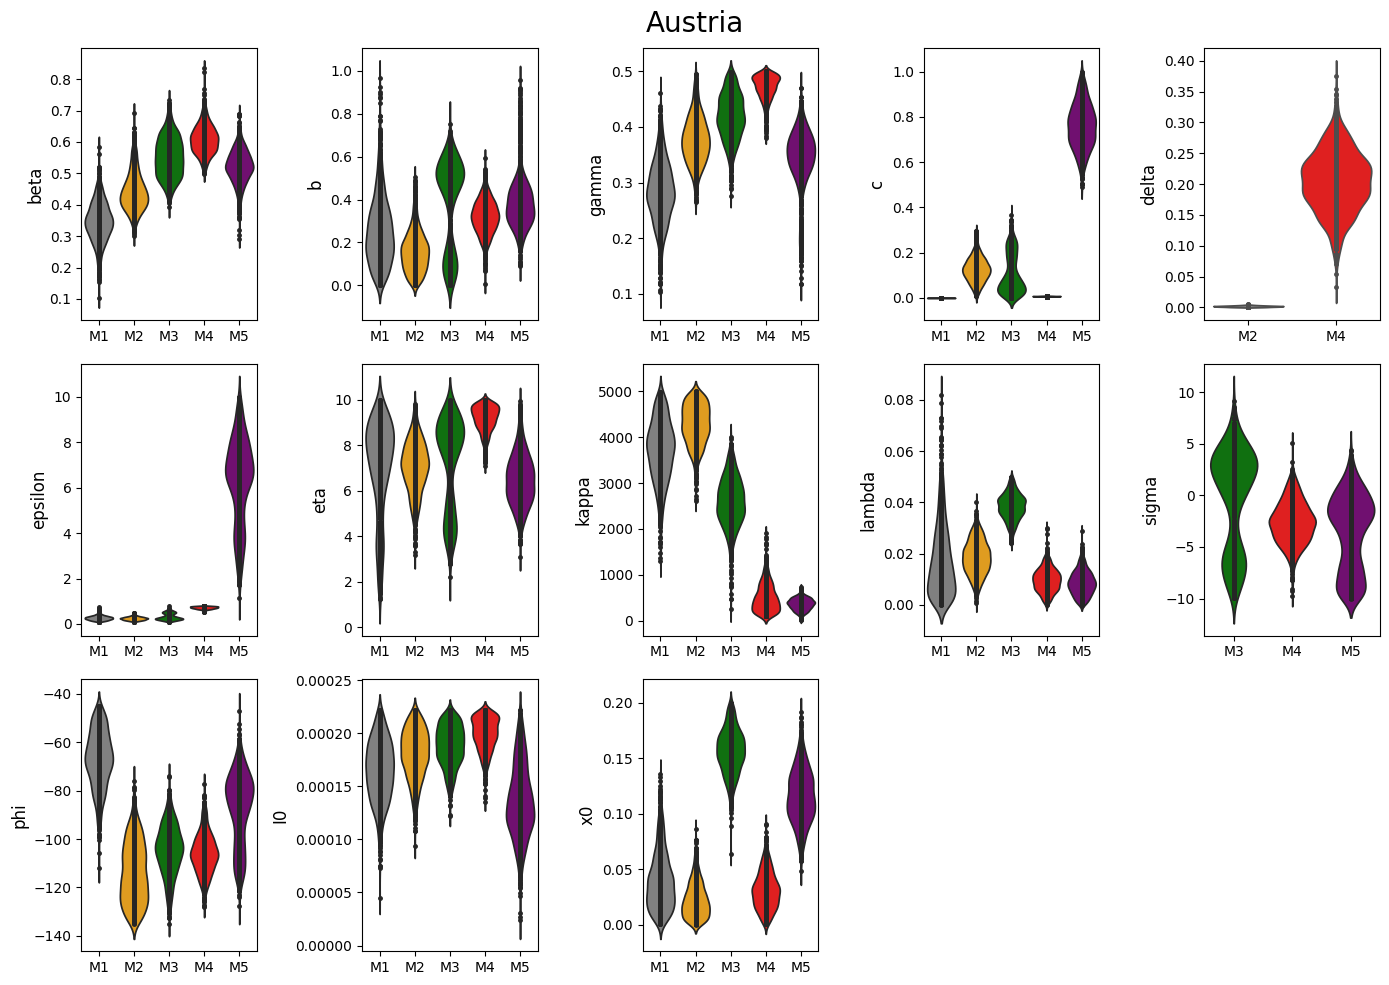

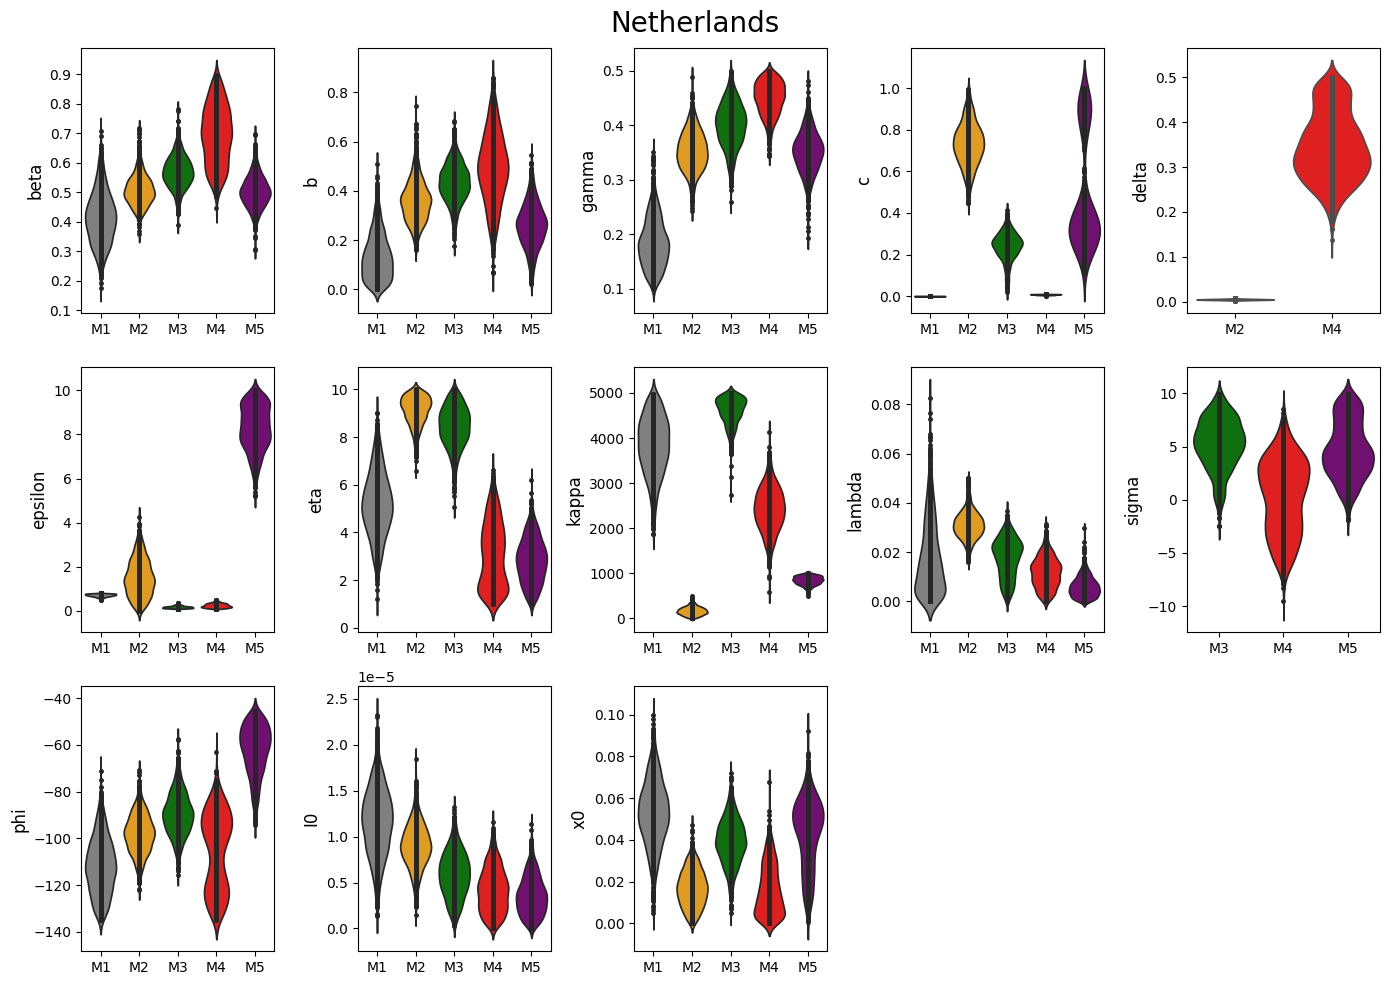

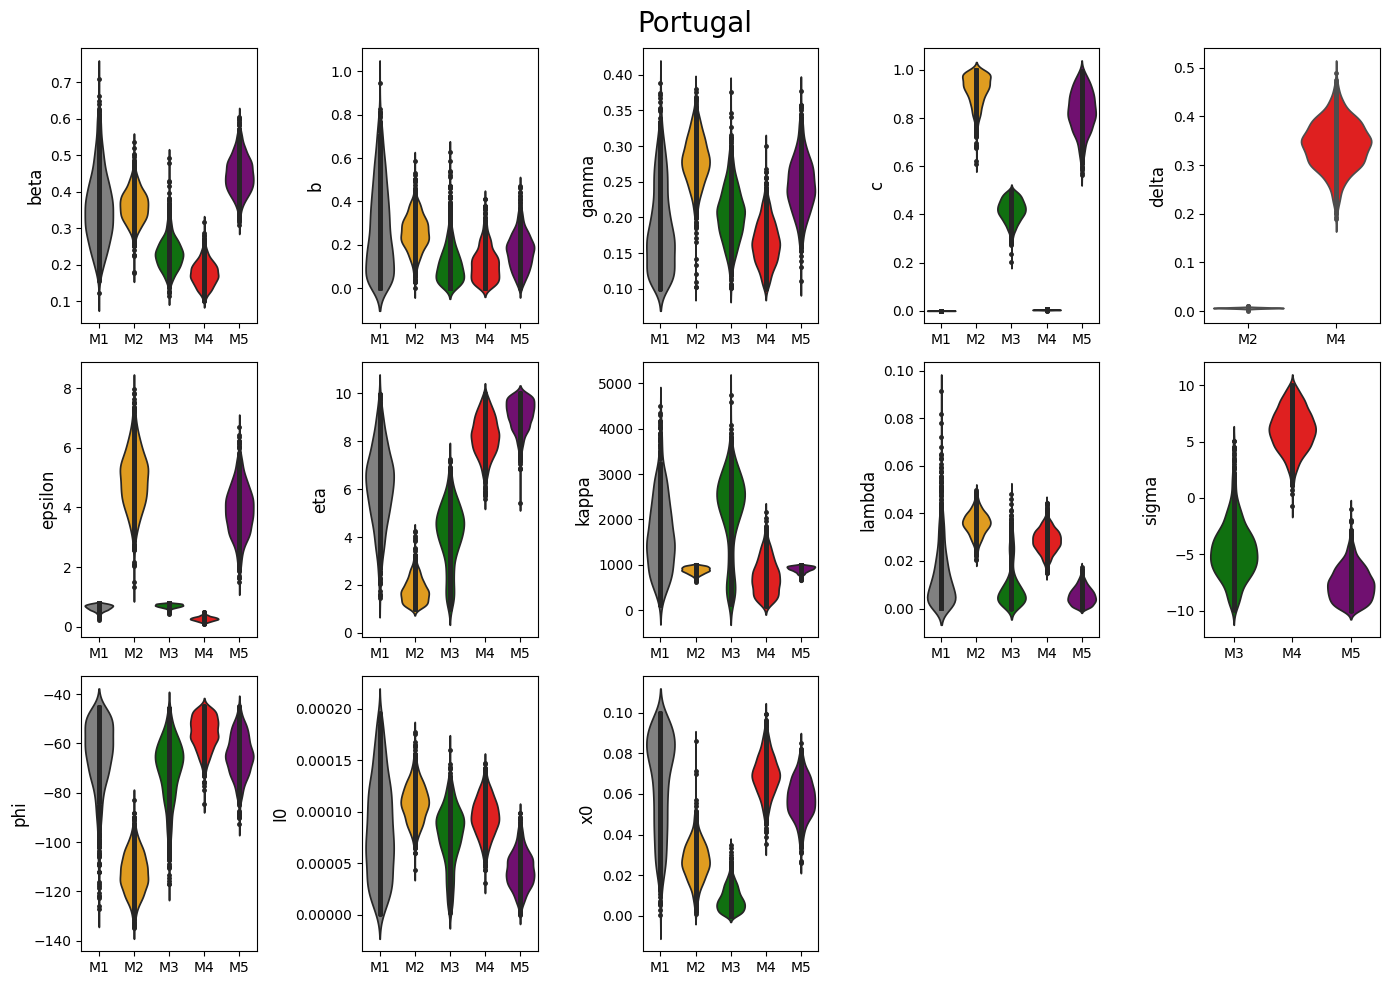

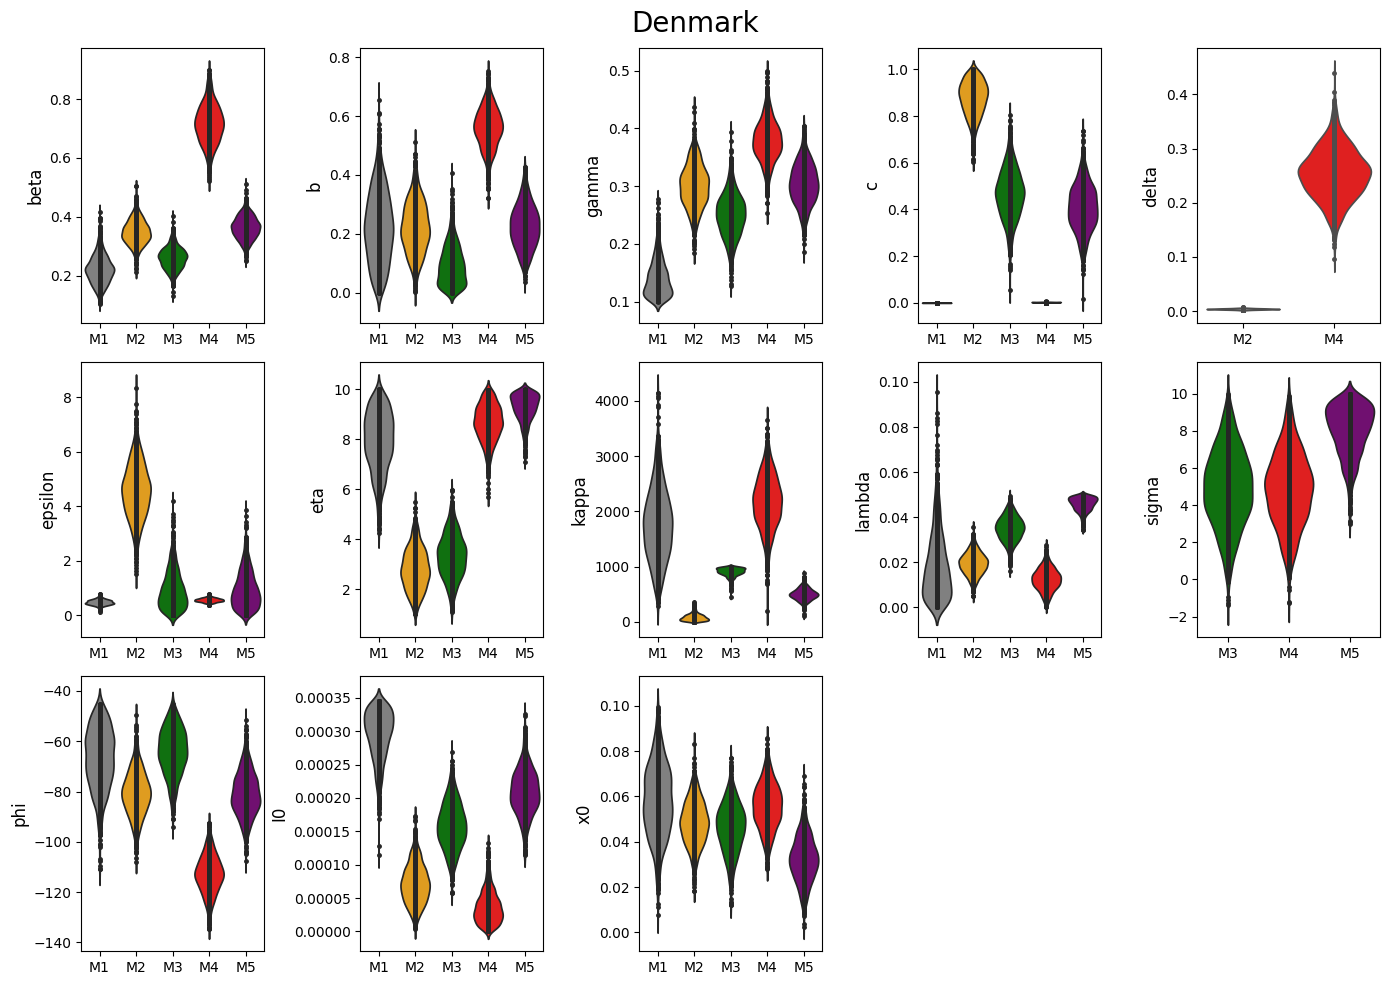

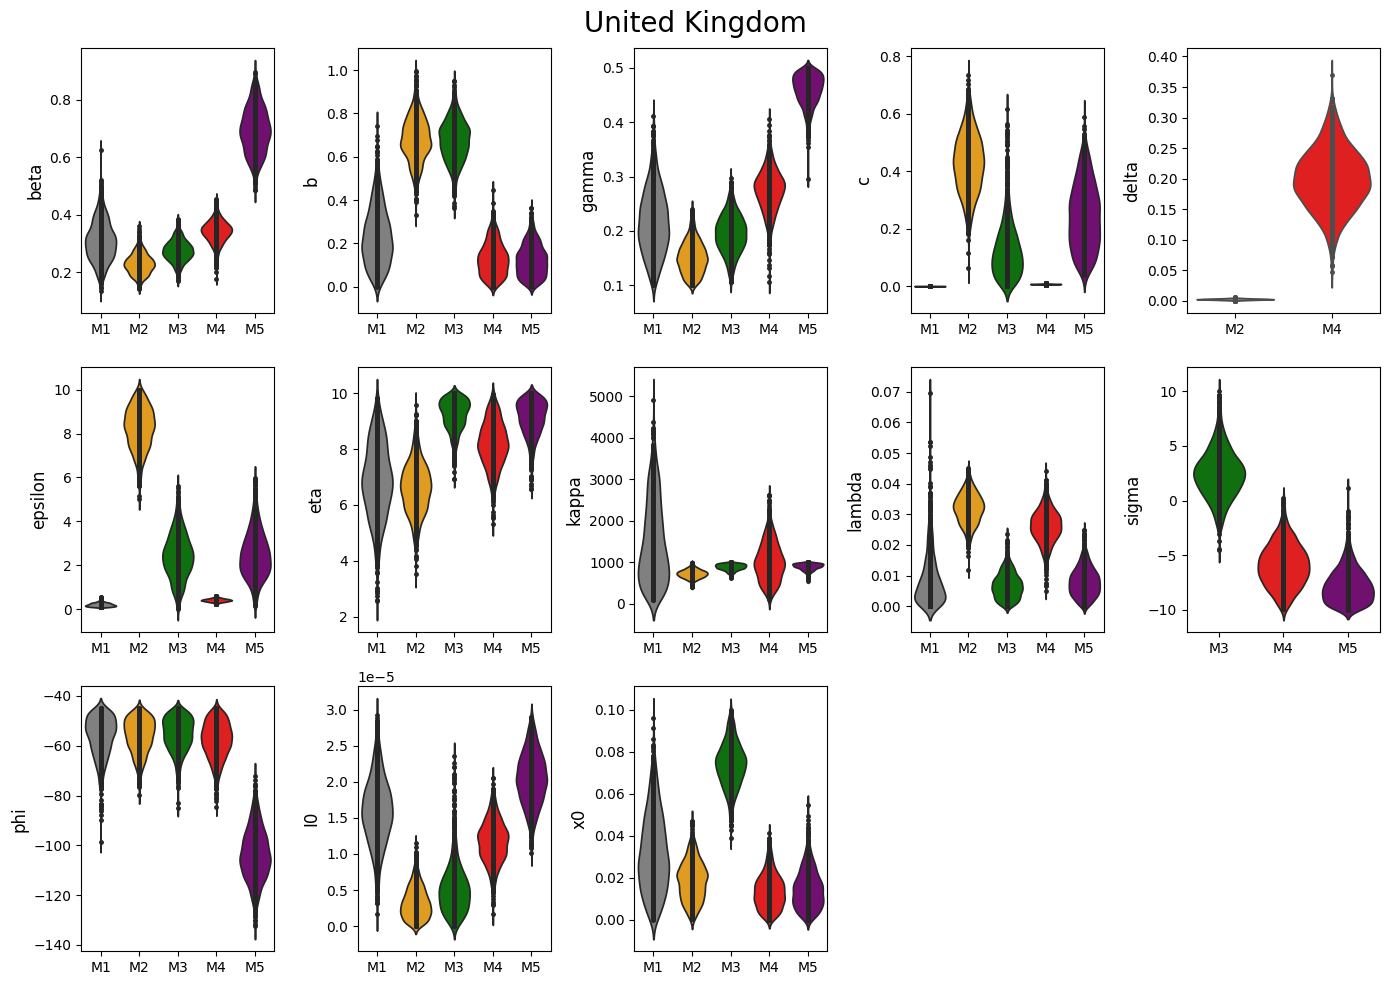

In [44]:
import seaborn as sns
Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'uk']
M1 = np.random.choice(['M1'], size=1000)
M2 = np.random.choice(['M2'], size=1000)
M3 = np.random.choice(['M3'], size=1000)
M4 = np.random.choice(['M4'], size=1000)
M5 = np.random.choice(['M5'], size=1000)

category = np.concatenate([M1, M2, M3, M4, M5])

column_names = ['b', 'gamma', 'c', 'eta_0', 'epsilon', 'eta_1', 'kappa', 'lambda',
       'phi', 'I0', 'x0', 'C0']
column_unit = {"beta":" ", 'b': " (/mm)",'phi':" (/degrees)", "gamma":" (/days)", "kappa":" (/days)",
                'c':" ", 'eta_0': " ", 'epsilon': " ", 'eta_1': " ", 'I0':" ", 'lambda':" ",
         'x0':" ", 'C0': " "}

Variant = [1, 0, 2, 3, 4]

austria_Vn = [0, 2, 2, 21, 7]
denmark_Vn = [0, 4, 3, 21, 4]
netherlands_Vn = [0, 6, 2, 21, 7]
portugal_Vn = [0, 4, 5, 26, 7]
uk_Vn = [0, 4, 4, 26, 3]

N = [austria_Vn, netherlands_Vn, portugal_Vn, denmark_Vn, uk_Vn]
Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
T = 100
# K = 12
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
ModelName = ["Model1", "Model2", "Model3", "Model4", "Model5", "SIR"]
AA = [[], [], [], [], []]
k = 1
# plt.figure(figsize=(25,13))
for filename in Filenames[:]:

    NN = N[k-1]

    data_base1 = particle_extraction(filename, NN[0], 1)
    data_base0 = particle_extraction(filename, NN[1], 0)
    data_base2 = particle_extraction(filename, NN[2], 2)
    data_base3 = particle_extraction(filename, NN[3], 3)
    data_base4 = particle_extraction(filename, NN[4], 4)

    i = 0
    plt.figure(figsize=(14, 10))
    if filename[:] == "uk":
        header = "United Kingdom"
    else:
        header = filename[:].capitalize()
    plt.suptitle(header, fontsize = 20)
    for par in data_base0.columns[2:-2]:
        plt.subplot(3,5,i+1)
        if par in data_base0.columns[:] and par in data_base1.columns[:] and par in data_base2.columns[:] and par in data_base3.columns[:] and par in data_base4.columns[:]:
            parameter = np.concatenate([ data_base1[par][:1000], data_base0[par][:1000] , data_base2[par][:1000], data_base3[par][:1000], data_base4[par][:1000]])
            data = pd.DataFrame({'category': category,'value': parameter})
            sns.violinplot(x='category', y='value', data=data, palette=['grey','orange','green','red','purple'], inner = 'points', hue = "category", legend = False)
            plt.ylabel(par , fontsize = 12) #+ column_unit[par]
            plt.xlabel('')
            
        elif par == "sigma":
            # print(data_base4[par].head())
            parameter = np.concatenate([data_base2[par][:1000], data_base3[par][:1000], data_base4[par][:1000]])
            # parameter = data_base0[par][:1000]
            data1 = pd.DataFrame({'category': category[2000:],'value': parameter})
            sns.violinplot(x='category', y='value', data=data1, palette=['green','red','purple'], inner = 'points', hue = "category", legend = False)
            # sns.violinplot(x='category', y='value', data=data1 , hue = "category", palette=['orange'])
            plt.ylabel(par, fontsize = 12)
            # plt.yscale("log")
            plt.xlabel('')
        elif par == "delta":
            # print(data_base1[par].head())
            parameter = np.concatenate([data_base0[par][:1000], data_base3[par][:1000]])
            # parameter = data_base0[par][:1000]
            category1 = np.concatenate([ M2, M4])
            data1 = pd.DataFrame({'category': category1[:],'value': parameter})
            sns.violinplot(x='category', y='value', data=data1, palette=['grey','red'], inner = 'points', hue = "category", legend = False)
            # sns.violinplot(x='category', y='value', data=data1 , hue = "category", palette=['orange'])
            plt.ylabel(par, fontsize = 12)
            plt.xlabel('')
        i +=1
    plt.tight_layout()
    # plt.legend(["Model1", "Model2", "Model3", "Model4", "Model5"], bbox_to_anchor=(1.05, 1.0), loc='upper left', title="$\\mathbf{Models}$", fontsize=12, title_fontsize='large')
    k += 1
    # plt.savefig(filename[:] + "_violin_revised.jpeg", dpi = 300)

plt.show()

In [ ]:
#One At A Time Sensitivity
def oat_sensitivity(filename, n, variant, t_end, Cutoff, variation, color, modelname, T):

    country = filename + "Avg7ma.csv"
    data = pd.read_csv(Country_path_old + country)
    dataosi = pd.read_csv(Country_path_old + filename + "Avgosi7ma.csv") 
    data = data[data.columns[1]]
    dataosi = dataosi[dataosi.columns[-1]][:t_end+1]

    data_avg = np.mean(data)*(np.ones(len(data)))
    data_avgosi = np.mean(dataosi)*(np.ones(len(data)))

    path_oat = country_particle_path

    N = len(data) + 1
    data = data[:t_end+1]

    results = {}

    results_peak = {}

    if variant == 0:
        # print(n)
        data_0 = pd.read_csv(path_oat +f"{filename}_{n}_v2_final_revised.csv")
        Particle_Sirx_variant2 = Pop_negative_variants(f"{filename}_{n}_v2_final_revised.csv", 0, 100, Cutoff, "sirx_variant2")
        data_0.rename(columns={'Ii0': 'C0'}, inplace=True)
        K = 12
        particle = Particle_Sirx_variant2[T][1].copy()
        x0,I = sirx_variant2(particle, t_end = t_end)
        I_peak = I[Cutoff:].max() #maximum value for prediction 
        I_time = [i for i in arange(Cutoff, t_end+1) if I[i] == I_peak][0] #time of prediction peak
        Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
        for i in range(len(Particle_Sirx_variant2[0][1])-1):
            key = data_0.columns[i+1]
            # print(len(particle0))

            p_low = Particle_Sirx_variant2[0][1].copy()
            p_high = Particle_Sirx_variant2[0][1].copy()

            p_low[i] *= (1 - variation)
            p_high[i] *= (1 + variation) 

            x0_low,I_low = sirx_variant2(p_low, t_end = t_end)
            x0_high,I_high = sirx_variant2(p_high, t_end = t_end)

            area_low = area_between_curves(data[Cutoff:], I_low[Cutoff:-1])
            area_high = area_between_curves(data[Cutoff:], I_high[Cutoff:-1])

            I_low_peak = I_low[Cutoff:].max() #maximum value for prediction 
            I_low_time = [i for i in arange(Cutoff, t_end+1) if I_low[i] == I_low_peak][0] #time of prediction peak

            I_high_peak = I_high[Cutoff:].max() #maximum value for prediction 
            I_high_time = [i for i in arange(Cutoff, t_end+1) if I_high[i] == I_high_peak][0] #time of prediction peak

            results_peak[key] = { "I_low": 100*abs(I_low_peak - I_peak)/I_peak ,
                            "I_low_time": 100*abs(I_low_time - I_time)/I_time, 
                            "I_high_peak" : 100*abs(I_high_peak-I_peak)/I_peak,  
                            "I_high_time": 100*abs(I_high_time - I_time)/I_time
                            }
            
            results[key] = { "base_area" : Area_SIRX,
                            "area_low": 100*abs(area_low- Area_SIRX)/Area_SIRX,
                            "area_high": 100*abs(area_high - Area_SIRX)/Area_SIRX  }

    if variant == 1:
        Particle_Sirx_eta = Pop_negative_variant1(filename + "_final_par.csv", 0, 200, t_end)
        data_1 = pd.read_csv(path_oat + filename + "_final_par.csv")
        data_1.rename(columns={'eta_0': 'eta'}, inplace=True)
        K = 11
        particle = Particle_Sirx_eta[T][1].copy()
        x1,I = odex(Particle_Sirx_eta[T][1], t_end)
        I_peak = I[Cutoff:].max() #maximum value for prediction 
        I_time = [i for i in arange(Cutoff, t_end+1) if I[i] == I_peak][0] #time of prediction peak
        Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
        for i in range(len(Particle_Sirx_eta[0][1])-1):
            key = data_1.columns[i+1]

            p_low = Particle_Sirx_eta[0][1].copy()
            p_high = Particle_Sirx_eta[0][1].copy()

            # print(key, p_low[i])

            p_low[i] *= (1 - variation)
            p_high[i] *= (1 + variation) 

            x0_low,I_low = odex(p_low, t_end)
            x0_high,I_high = odex(p_high, t_end)

            area_low = area_between_curves(data[Cutoff:], I_low[Cutoff:-1])
            area_high = area_between_curves(data[Cutoff:], I_high[Cutoff:-1])

            I_low_peak = I_low[Cutoff:].max() #maximum value for prediction 
            I_low_time = [i for i in arange(Cutoff, t_end+1) if I_low[i] == I_low_peak][0] #time of prediction peak

            I_high_peak = I_high[Cutoff:].max() #maximum value for prediction 
            I_high_time = [i for i in arange(Cutoff, t_end+1) if I_high[i] == I_high_peak][0] #time of prediction peak

            results_peak[key] = { "I_low": 100*abs(I_low_peak - I_peak)/I_peak ,
                            "I_low_time": 100*abs(I_low_time - I_time)/I_time, 
                            "I_high_peak" : 100*abs(I_high_peak-I_peak)/I_peak,  
                            "I_high_time": 100*abs(I_high_time - I_time)/I_time
                            }
            
            results[key] = { "base_area" : Area_SIRX,
                            "area_low": 100*abs(area_low- Area_SIRX)/Area_SIRX,
                            "area_high": 100*abs(area_high - Area_SIRX)/Area_SIRX  }

    if variant == 2:
        Particle_Sirx_variant3 = Pop_negative_variants(f"{filename}_{n}_v3_final_revised.csv", 0, 1000, Cutoff, "sirx_variant3")
        data_2 = pd.read_csv(path_oat + f"{filename}_{n}_v3_final_revised.csv")
        data_2.rename(columns={'Ii0': 'C0'}, inplace=True)
        K = 11
        particle = Particle_Sirx_variant3[T][1].copy()
        x2,I = sirx_variant3(particle, t_end = t_end)
        I_peak = I[Cutoff:].max() #maximum value for prediction 
        I_time = [i for i in arange(Cutoff, t_end+1) if I[i] == I_peak][0] #time of prediction peak
        Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
        for i in range(len(Particle_Sirx_variant3[0][1])-1):
            key = data_2.columns[i+1]

            p_low = Particle_Sirx_variant3[0][1].copy()
            p_high = Particle_Sirx_variant3[0][1].copy()

            p_low[i] *= (1 - variation)
            p_high[i] *= (1 + variation) 

            x0_low,I_low = sirx_variant3(p_low, t_end = t_end)
            x0_high,I_high = sirx_variant3(p_high, t_end = t_end)

            area_low = area_between_curves(data[Cutoff:], I_low[Cutoff:-1])
            area_high = area_between_curves(data[Cutoff:], I_high[Cutoff:-1])

            I_low_peak = I_low[Cutoff:].max() #maximum value for prediction 
            I_low_time = [i for i in arange(Cutoff, t_end+1) if I_low[i] == I_low_peak][0] #time of prediction peak

            I_high_peak = I_high[Cutoff:].max() #maximum value for prediction 
            I_high_time = [i for i in arange(Cutoff, t_end+1) if I_high[i] == I_high_peak][0] #time of prediction peak
            
            results_peak[key] = { "I_low": 100*abs(I_low_peak - I_peak)/I_peak ,
                            "I_low_time": 100*abs(I_low_time - I_time)/I_time, 
                            "I_high_peak" : 100*abs(I_high_peak-I_peak)/I_peak,  
                            "I_high_time": 100*abs(I_high_time - I_time)/I_time
                            }
            
            results[key] = { "base_area" : Area_SIRX,
                            "area_low": 100*abs(area_low- Area_SIRX)/Area_SIRX,
                            "area_high": 100*abs(area_high - Area_SIRX)/Area_SIRX  }

    if variant == 3:
        data_3 = pd.read_csv(path_oat + f"{filename}_{n}_v3_final.csv")
        data_3.rename(columns={'Ii0': 'C0'}, inplace=True)
        K = 12
        data3 = data_3.iloc[:, :-1].values
        particle3 = data3[T]
        particle3 = np.insert(particle3, 0,  0)
        particle = particle3.copy()
        x3,I = ode(particle3, variant = 3, t_end = t_end)
        I_peak = I[Cutoff:].max() #maximum value for prediction 
        I_time = [i for i in arange(Cutoff, t_end+1) if I[i] == I_peak][0] #time of prediction peak
        Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
        for i in range(len(particle3)-3):
            key = data_3.columns[i+1]

            p_low = particle3.copy()
            p_high = particle3.copy()

            p_low[i] *= (1 - variation)
            p_high[i] *= (1 + variation) 

            x0_low,I_low = ode(p_low, variant = 3, t_end = t_end)
            x0_high,I_high = ode(p_high, variant = 3, t_end = t_end)

            area_low = area_between_curves(data[Cutoff:], I_low[Cutoff:-1])
            area_high = area_between_curves(data[Cutoff:], I_high[Cutoff:-1])

            I_low_peak = I_low[Cutoff:].max() #maximum value for prediction 
            I_low_time = [i for i in arange(Cutoff, t_end+1) if I_low[i] == I_low_peak][0] #time of prediction peak

            I_high_peak = I_high[Cutoff:].max() #maximum value for prediction 
            I_high_time = [i for i in arange(Cutoff, t_end+1) if I_high[i] == I_high_peak][0] #time of prediction peak

            results_peak[key] = { "I_low": 100*abs(I_low_peak - I_peak)/I_peak ,
                            "I_low_time": 100*abs(I_low_time - I_time)/I_time, 
                            "I_high_peak" : 100*abs(I_high_peak-I_peak)/I_peak,  
                            "I_high_time": 100*abs(I_high_time - I_time)/I_time
                            }
            
            results[key] = { "base_area" : Area_SIRX,
                            "area_low": 100*abs(area_low- Area_SIRX)/Area_SIRX,
                            "area_high": 100*abs(area_high - Area_SIRX)/Area_SIRX  }

    if variant == 4:
        Particle_Sirx_variant5 = Pop_negative_variants(f"{filename}_{n}_v5_final_revised.csv", 0, 1000, Cutoff, "sirx_variant5")
        data_4 = pd.read_csv(path_oat + f"{filename}_{n}_v5_final_revised.csv")
        data_4.rename(columns={'Ii0': 'C0'}, inplace=True)
        K = 11
        particle = Particle_Sirx_variant5[T][1].copy()
        x4,I = sirx_variant5(particle, t_end = t_end)
        I_peak = I[Cutoff:].max() #maximum value for prediction 
        I_time = [i for i in arange(Cutoff, t_end+1) if I[i] == I_peak][0] #time of prediction peak
        Area_SIRX = area_between_curves(data[Cutoff:], I[Cutoff:-1])
        for i in range(len(Particle_Sirx_variant5[0][1])-1):
            key = data_4.columns[i+1]
            # print(key,len(particle4)-2)

            p_low = Particle_Sirx_variant5[0][1].copy()
            p_high = Particle_Sirx_variant5[0][1].copy()

            p_low[i] *= (1 - variation)
            p_high[i] *= (1 + variation) 

            x0_low,I_low = sirx_variant5(p_low, t_end = t_end)
            x0_high,I_high = sirx_variant5(p_high, t_end = t_end)

            area_low = area_between_curves(data[Cutoff:], I_low[Cutoff:-1])
            area_high = area_between_curves(data[Cutoff:], I_high[Cutoff:-1])

            I_low_peak = I_low[Cutoff:].max() #maximum value for prediction 
            I_low_time = [i for i in arange(Cutoff, t_end+1) if I_low[i] == I_low_peak][0] #time of prediction peak

            I_high_peak = I_high[Cutoff:].max() #maximum value for prediction 
            I_high_time = [i for i in arange(Cutoff, t_end+1) if I_high[i] == I_high_peak][0] #time of prediction peak

            # results_peak[key] = { "I_peak" : I_peak, "I_time": I_time, "I_low_peak": I_low_peak ,
            #                 "I_low_time": I_low_time, "I_high_peak" : I_high_peak,  "I_high_time": I_high_time}
            results_peak[key] = { "I_low": 100*abs(I_low_peak - I_peak)/I_peak ,
                            "I_low_time": 100*abs(I_low_time - I_time)/I_time, 
                            "I_high_peak" : 100*abs(I_high_peak-I_peak)/I_peak,  
                            "I_high_time": 100*abs(I_high_time - I_time)/I_time
                            }

            results[key] = { "base_area" : Area_SIRX,
                            "area_low": 100*abs(area_low- Area_SIRX)/Area_SIRX,
                            "area_high": 100*abs(area_high - Area_SIRX)/Area_SIRX  }

    plt.plot(np.cbrt(I[1:]), color = color, linewidth = 3.5, label = modelname) # label =   't =  ' + str(t) + ', ' + str(error(data, I))

    
    return results, results_peak
    # plt.show()

Model 1 Index(['Unnamed: 0', 'beta', 'b', 'gamma', 'c', 'eta', 'epsilon', 'kappa',
       'lambda', 'phi', 'I0', 'x0', 'C0', 'Error_I', 'Error_X'],
      dtype='object')
Model 2 Index(['alpha', 'beta', 'b', 'gamma', 'c', 'delta', 'epsilon', 'eta', 'kappa',
       'lambda', 'sigma', 'phi', 'I0', 'x0'],
      dtype='object')
Model 3 Index(['Unnamed: 0', 'beta', 'b', 'gamma', 'c', 'delta', 'epsilon', 'eta',
       'kappa', 'lambda', 'sigma', 'phi', 'I0', 'x0', 'C0', 'Error_I'],
      dtype='object')
Model 4 Index(['beta', 'b', 'gamma', 'c', 'delta', 'epsilon', 'eta', 'kappa', 'lambda',
       'sigma', 'phi', 'I0', 'x0', 'C0', 'Error_I'],
      dtype='object')
Model 5 Index(['Unnamed: 0', 'beta', 'b', 'gamma', 'c', 'epsilon', 'eta', 'kappa',
       'lambda', 'sigma', 'phi', 'I0', 'x0', 'C0', 'Error_I'],
      dtype='object')
Model 1 Index(['Unnamed: 0', 'beta', 'b', 'gamma', 'c', 'eta', 'epsilon', 'kappa',
       'lambda', 'phi', 'I0', 'x0', 'C0', 'Error_I', 'Error_X'],
      dtype='object

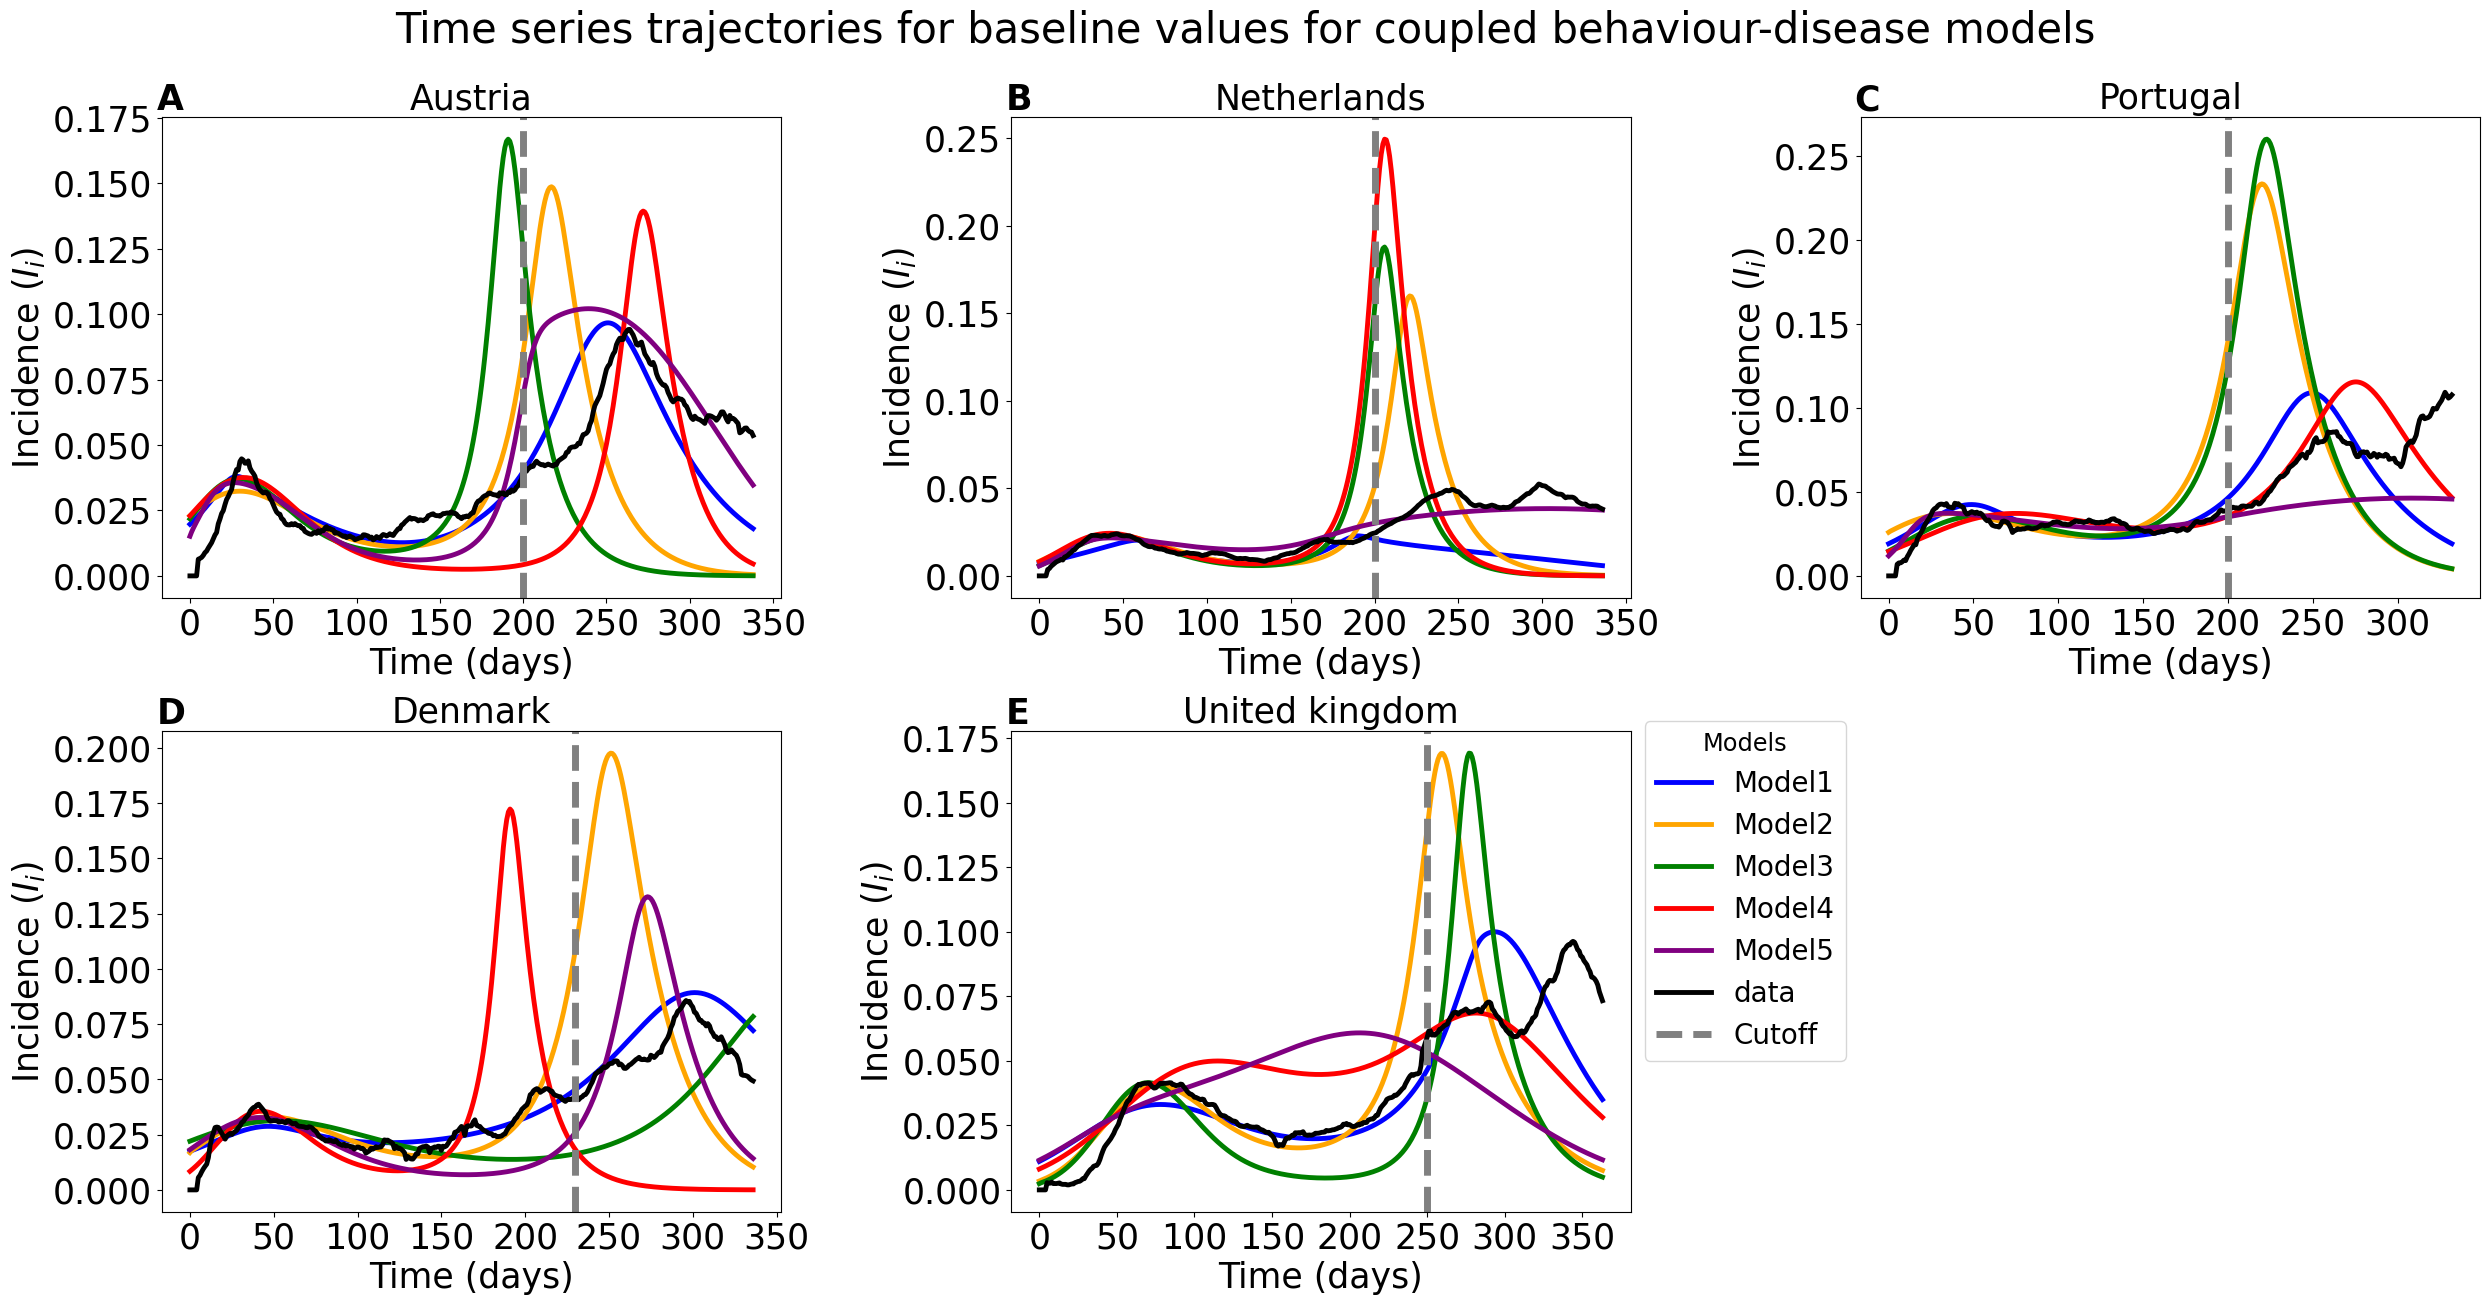

In [48]:
Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'uk']
import statistics
Variant = [1, 0, 2, 3, 4]


N = [austria_Vn, netherlands_Vn, portugal_Vn, denmark_Vn, uk_Vn]
T = 4
variation = 0.2
colors = ['blue', 'orange', 'green', 'red', 'purple', 'brown']
ModelName = ["Model1", "Model2", "Model3", "Model4", "Model5", "SIR"]
Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
# names = [names_austria, names_netherlands, names_portugal, names_denmark]
AA = [[], [], [], [], []]
PP = [[], [], [], [], []]

# for T in range(5):
k = 1
plt.figure(figsize=(25,13))
for filename in Filenames[:]:

    country = filename + "Avg7ma.csv"
    name = filename + "Avg.csv"
    data = pd.read_csv(Country_path_old + country)
    data = data[data.columns[1]]
    t_end = len(data)
    dataosi = pd.read_csv(Country_path_old + filename + "Avgosi7ma.csv")
    dataosi = dataosi[dataosi.columns[-1]][:t_end+1] 
    # names_country = names[k-1]
    Cutoff = cutoff[name]
    NN = N[k-1]
    t = np.arange(0, t_end+1)
    plt.subplot(2,3,k)
    for i in range(len(Variant)):
        variant = Variant[i]
        n = NN[i]
        # print(i, n)
        c = colors[i]
        nn = ModelName[i]

        # print(variant)

        H, M = oat_sensitivity(filename, n, variant, t_end, Cutoff, variation, c, nn, T)
        sigma = statistics.stdev(data)
        # params = P
        # S = compute_sensitivities_fd(params, variant, Cutoff, eps=1e-5)
        # F = compute_fim(S, sigma)

        # # print("FIM:\n", F)

        # f_rank = np.linalg.matrix_rank(F)
        # print(variant, filename, f_rank, len(P))
        # # print(f_rank,len(P))

        # f_cond = np.linalg.cond(F)

        # Cov = np.linalg.inv(F)
        # std_errors = np.sqrt(np.diag(Cov))

        # print("Covariance:", Cov)

        # print("Std errors:", std_errors)

        # D = np.sqrt(np.diag(Cov))
        # Corr = Cov / np.outer(D, D)

        # print("Correlation matrix:\n", Corr)

        AA[k-1].append(H), PP[k-1].append(M)

    plt.plot(np.arange(len(data[:])), np.cbrt(data[:]), label = 'data', color = 'black', linewidth = 3.5)
    # plt.plot(np.arange(len(dataosi[:])), np.cbrt(dataosi[:]), label = 'data', color = 'black', linewidth = 3.5)

    plt.axvline(x = Cutoff, color = 'grey', linestyle="--", linewidth = 5, label = 'Cutoff')
    # plt.plot(data[4:201+4], label = 'data', color = 'black', marker = "o",  linewidth = 2)
    # plt.yscale('log')
    plt.xlabel("Time (days)", fontsize = 25)
    plt.xticks(fontsize = 25)
    plt.yticks(fontsize = 25)
    plt.ylabel("Incidence $(I_i)$", fontsize = 25)
    plt.text(-0.01, 1.0, Labels[k-1], transform=plt.gca().transAxes, fontsize=25, va='bottom', ha='left',  color ="black")
    if filename == "uk":
        filename = "United Kingdom"
    plt.title(f"{filename.capitalize()}", fontsize = 25)
    # plt.title(f"{filename.capitalize()}", fontsize = 25)
    k += 1
plt.legend(bbox_to_anchor=(1.0, 1.05), loc='upper left', fontsize = 20, title="Models", title_fontsize='xx-large', ncols = 1)
plt.suptitle("Time series trajectories for baseline values for coupled behaviour-disease models", fontsize = 30, y = 1.0)
plt.tight_layout()
# plt.savefig("baseline.png", dpi = 300)
plt.show()

In [49]:
import numpy as np

def compute_sensitivities_fd(params, variant, t_end, eps=1e-5):
    """
    model_func: function(params) -> y(t) vector
    params: array of parameters
    """
    # print(params, variant)
    if variant == 1:
        x1,base = odex(params, t_end)
    elif variant == 0:
        x1,base = sirx_variant2(params, t_end)
    elif variant == 2:
        x1,base = sirx_variant3(params, t_end)
    elif variant == 4:
        x1,base = sirx_variant5(params, t_end)
    else:
        x, base = ode(params, variant, t_end)
    n_params = len(params)
    n_time = len(base)

    S = np.zeros((n_time, n_params))

    for j in range(n_params):
        params_eps = params.copy()
        params_eps[j] += eps
        if variant == 1:
            x1, y1 = odex(params_eps, t_end)
            y_eps = y1
        elif variant == 0:
            x1, y1 = sirx_variant2(params_eps, t_end)
            y_eps = y1
        elif variant == 2:
            x1, y1 = sirx_variant3(params_eps, t_end)
            y_eps = y1
        elif variant == 4:
            x1, y1 = sirx_variant5(params_eps, t_end)
            y_eps = y1
        else:
            x, y_eps = ode(params, variant, t_end)

        S[:, j] = (y_eps - base) / eps

    return S

def compute_fim(S, sigma):
    """
    S: sensitivity matrix (time x parameters)
    sigma: observation noise std
    """
    return (S.T @ S) / (sigma**2)

In [50]:
import matplotlib.pyplot as plt

def tornado_plot1(results, filename):
    params = list(results.keys())
    base = np.array([results[p]["base_area"] for p in params])
    low = np.array([results[p]["area_low"] for p in params])
    high = np.array([results[p]["area_high"] for p in params])


    impact = np.maximum(abs(low), abs(high))
    order = np.argsort(impact)

    low= low[order]
    high= high[order]
    params = np.array(params)[order]

    y_pos = np.arange(len(params))

    # plt.figure(figsize=(6,6))
    # plt.barh(y_pos, base, 0.3, color = "black", label = "Baseline ")
    plt.barh(y_pos , low, 0.5,  color = "blue", label = "Low variation")
    plt.barh(y_pos+0.3, high, 0.5, color = "orange", label = "High variation")

    plt.xticks(fontsize = 20)
    plt.yticks(y_pos, [latex_labels[k] for k in params], fontsize = 18)
    plt.axvline(0, color='black')
    plt.xlim(0, 100)
    plt.xlabel(" % $\\triangle $ in Area ", fontsize = 20)
    plt.title(f" {filename}", fontsize = 20)

    # plt.show()

In [52]:
latex_labels = {
    "beta":  r"$\beta$",
    "gamma": r"$\gamma$",
    "phi":    r"$\phi$",
    "kappa": r"$\kappa$",
    "lambda":   r"$\lambda$",
    "b":    r"$b$",
    "C0":   r"$C_0$",
    "x0":  r"$x_0$",
    "I0": r"$I_0$",
    "epsilon": r"$\epsilon$",
    "eta": r"$\eta$",
    "eta_0": r"$\eta_0$",
    "c" : r"$c$",
    "alpha": r"$\alpha$",
    "delta": r"$\delta$",
    "sigma": r"$\sigma$"
}

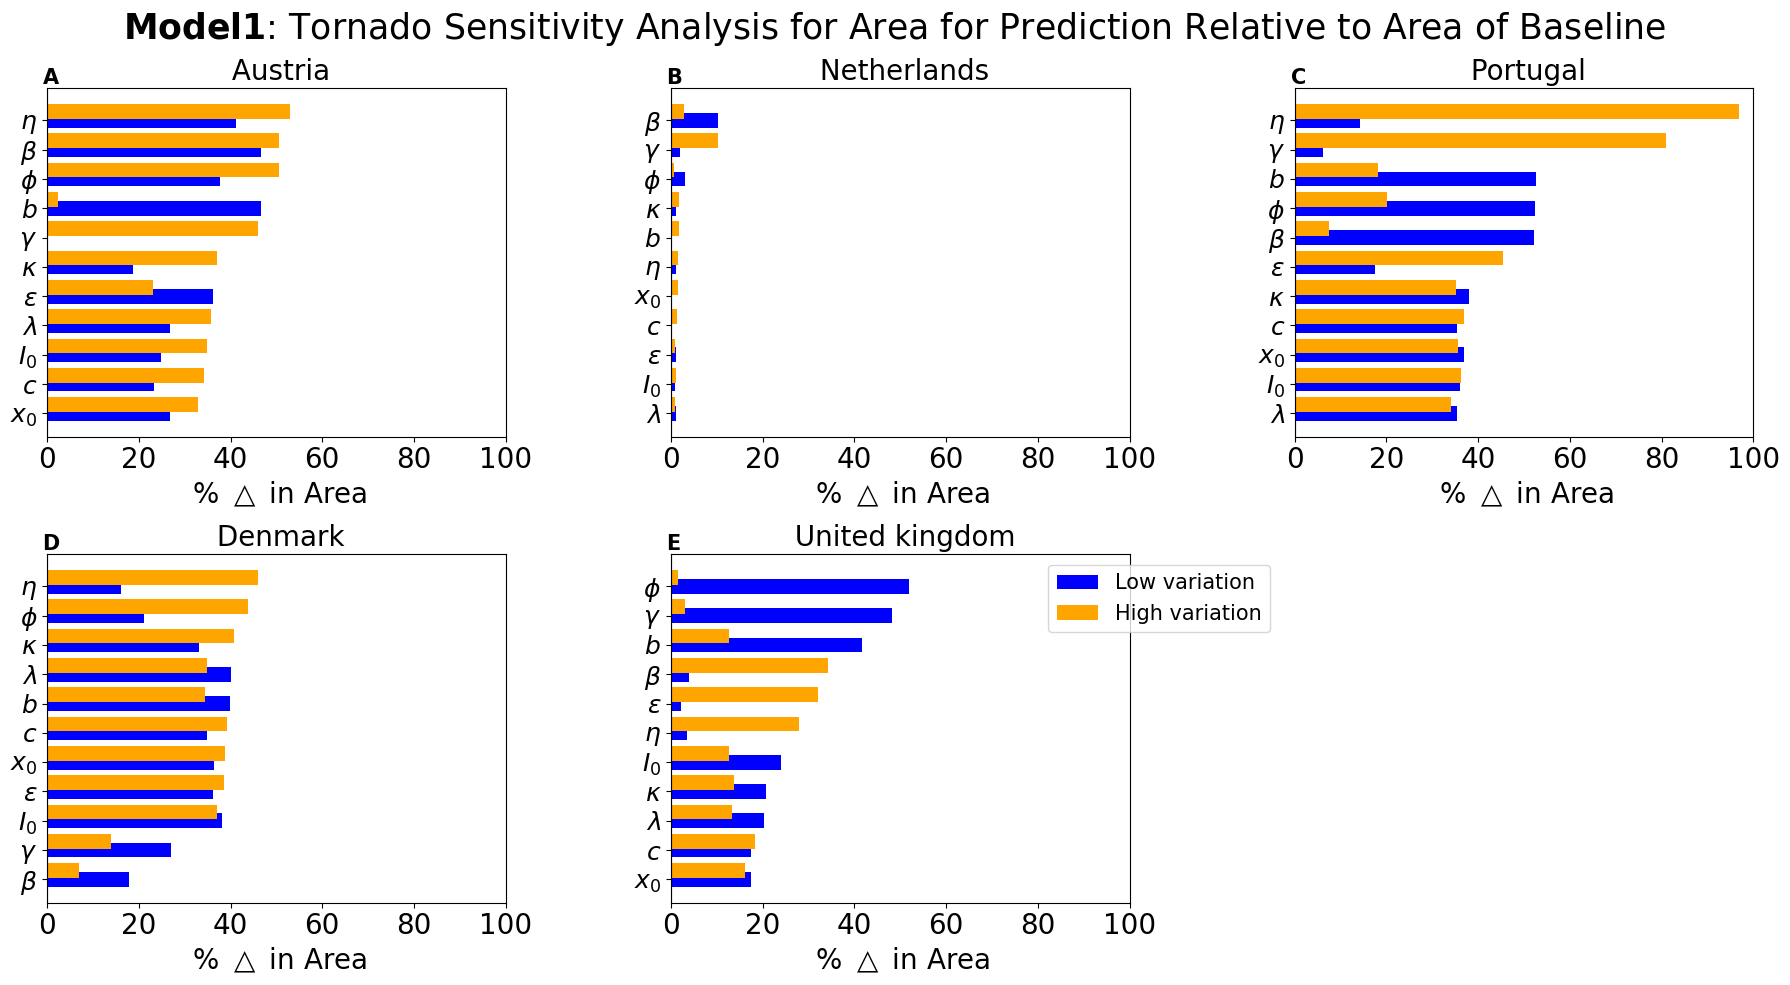

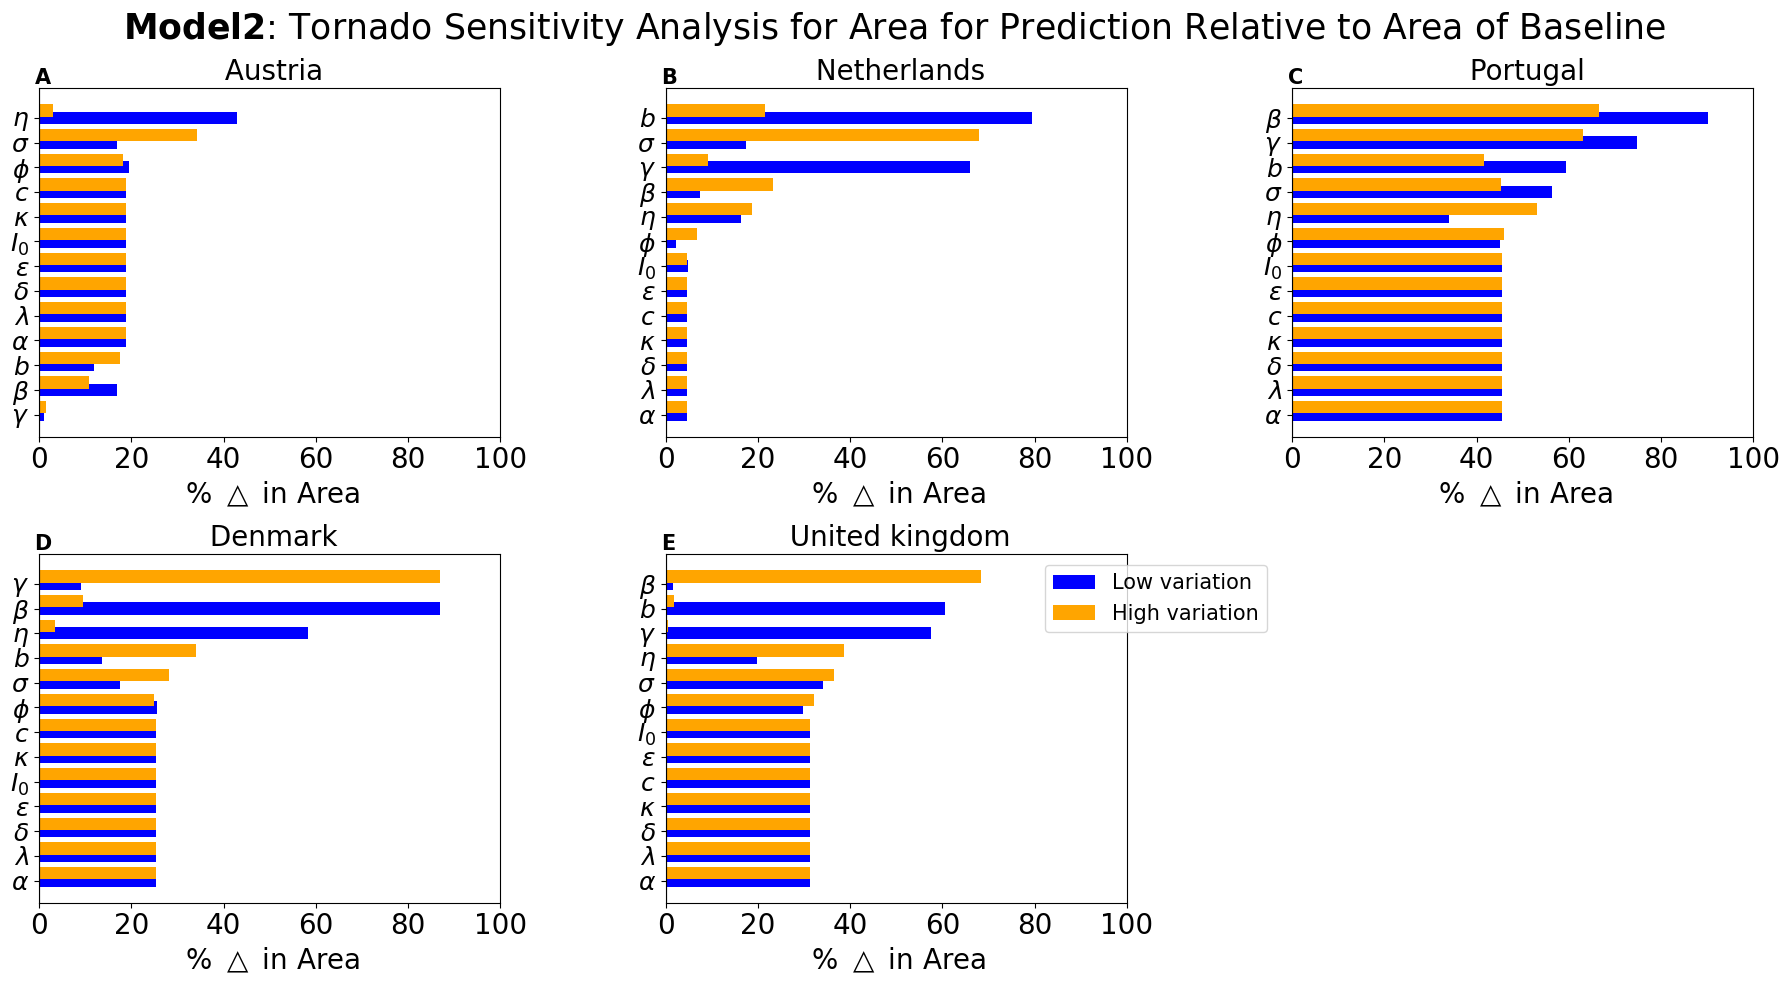

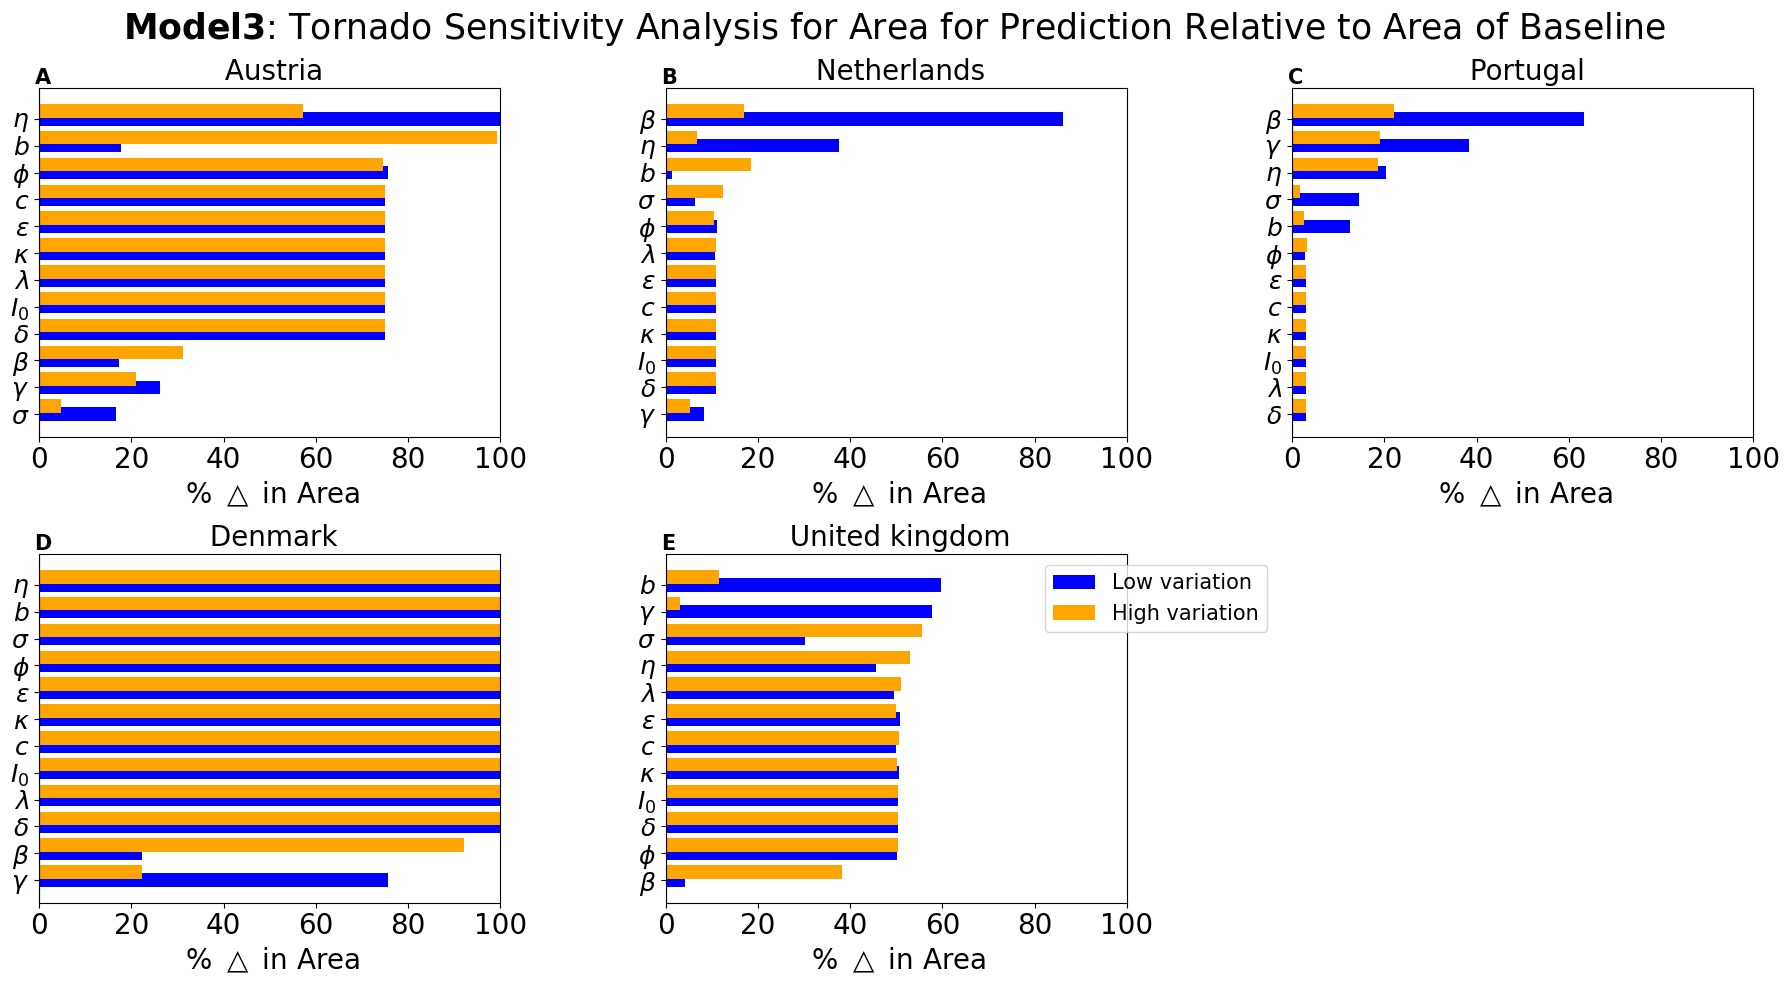

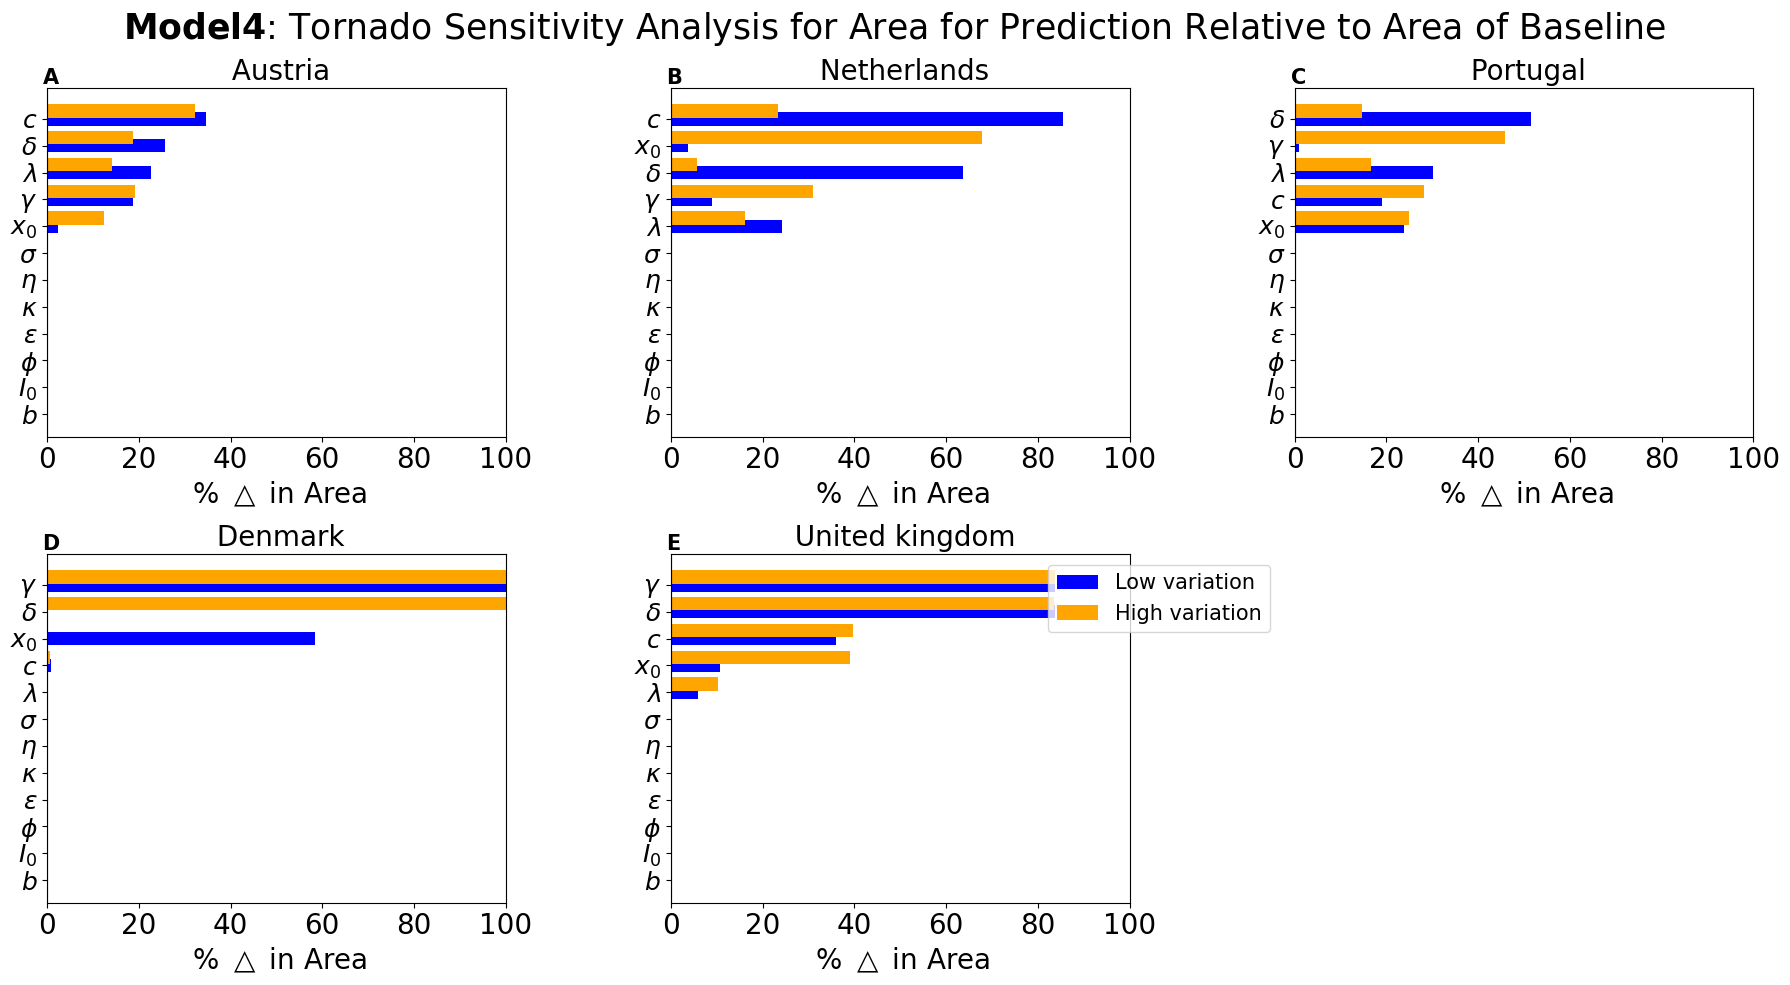

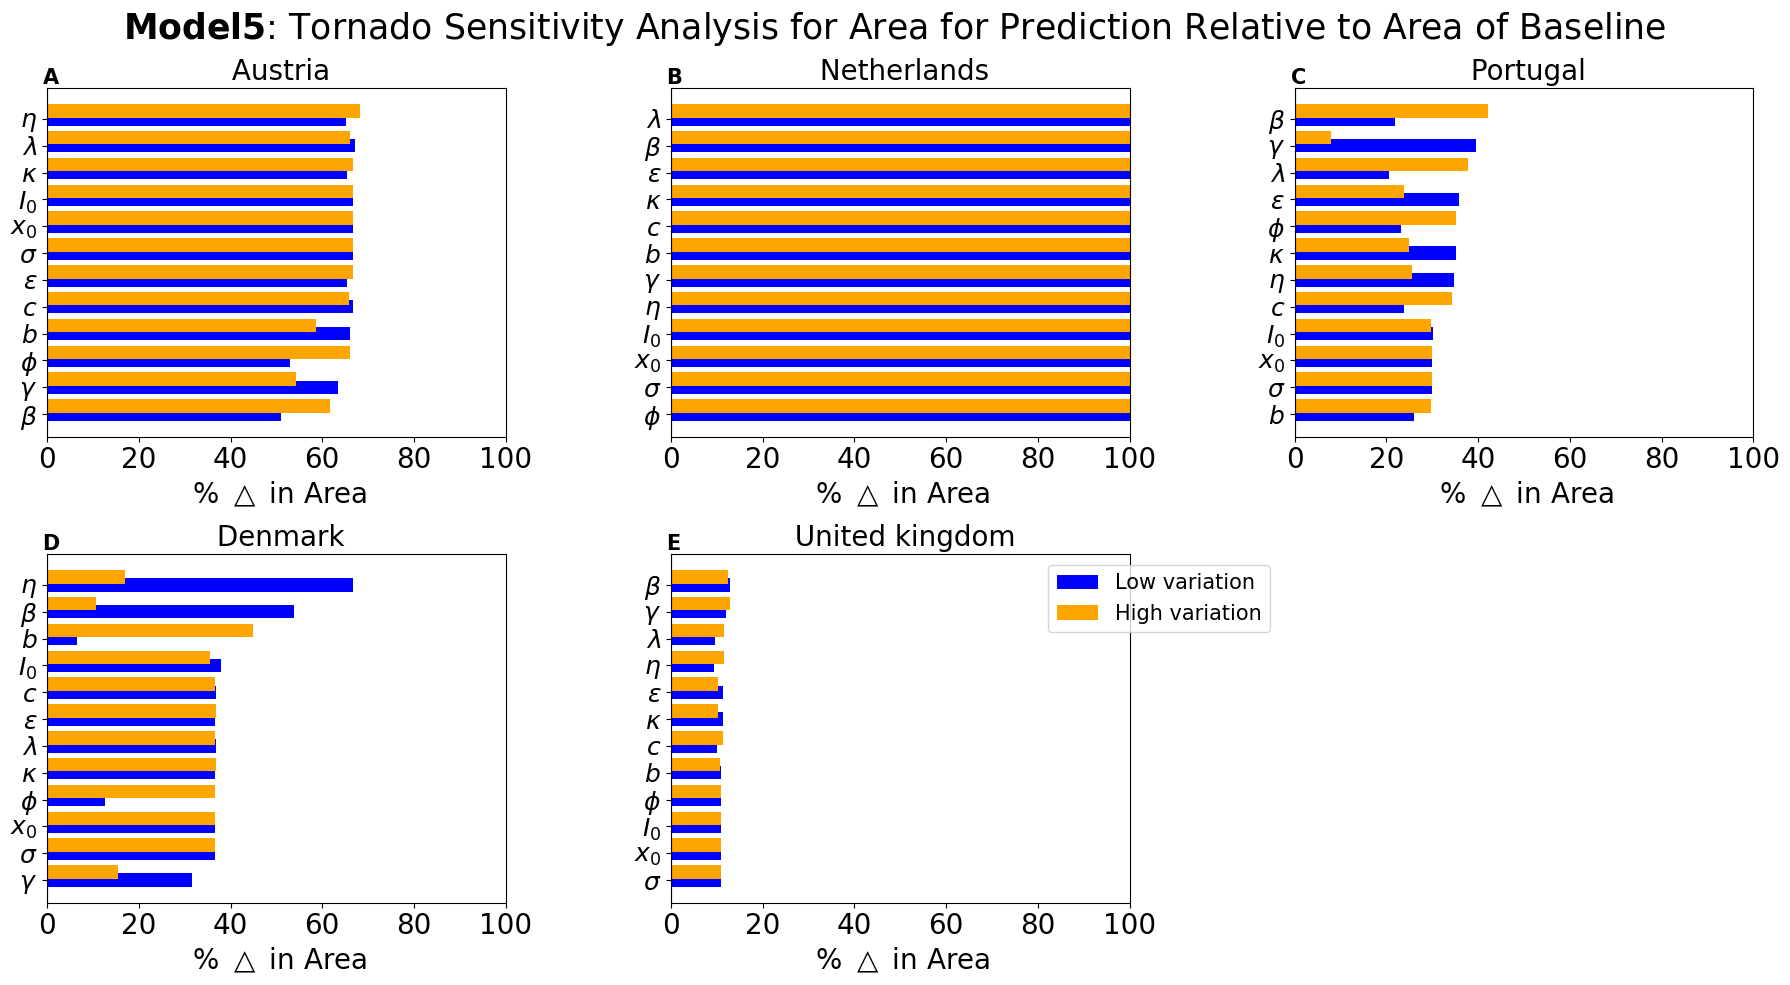

In [ ]:
# tornado_plot(AA[4][0])
for mod in range(5):
    plt.figure(figsize=(18,10))
    Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'United Kingdom']
    Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
    for i in range(5):
        plt.subplot(2,3, i +1)
        tornado_plot1(AA[i][mod], Filenames[i].capitalize())
        plt.text(-0.01, 1.0, Labels[i], transform=plt.gca().transAxes, fontsize=15, va='bottom', ha='left',  color ="black")
    plt.legend(bbox_to_anchor=(0.80, 1.0), loc='upper left', fontsize = 15, ncols = 1)
    plt.suptitle("$\\mathbf{{{model}}} $: Tornado Sensitivity Analysis for Area for Prediction Relative to Area of Baseline".format(model = ModelName[mod]), fontsize = 25)
    plt.tight_layout()
    # plt.savefig(f"A{mod+1}_revised.png", dpi = 300)


In [54]:
def tornado_plot_peak(results, filename):
    params = list(results.keys())
    # base = [results[p]["I_peak"] for p in params]
    low = np.array([results[p]["I_low"] for p in params])
    high = np.array([results[p]["I_high_peak"] for p in params])

    impact = np.maximum(abs(low), abs(high))
    order = np.argsort(impact)

    low= low[order]
    high= high[order]
    params = np.array(params)[order]

    y_pos = np.arange(len(params))

    # plt.figure(figsize=(6,6))
    # plt.barh(y_pos, base, 0.3, color = "black", label = "Data")
    plt.barh(y_pos , low, 0.5,  color = "blue", label = "Low variation")
    plt.barh(y_pos+0.3, high, 0.5, color = "orange", label = "High variation")

    plt.xticks( fontsize = 20)
    plt.yticks(y_pos, [latex_labels[k] for k in params], fontsize = 18)
    plt.axvline(0, color='black')
    plt.xlim(0, 100)
    plt.xlabel("% $\\triangle $ for Peak Magnitude", fontsize = 20)
    plt.title(f" {filename}", fontsize = 20)


def tornado_plot_peak_time(results, filename):
    params = list(results.keys())
    # base = [results[p]["I_time"] for p in params]
    low = np.array([results[p]["I_low_time"] for p in params])
    high = np.array([results[p]["I_high_time"] for p in params])

    impact = np.maximum(abs(low), abs(high))
    order = np.argsort(impact)

    low= low[order]
    high= high[order]
    params = np.array(params)[order]

    y_pos = np.arange(len(params))

    # plt.figure(figsize=(6,6))
    # plt.barh(y_pos, base, 0.3, color = "black", label = "Data")
    plt.barh(y_pos , low, 0.5,  color = "blue", label = "Low variation")
    plt.barh(y_pos+0.3, high, 0.5, color = "orange", label = "High variation")

    plt.xticks( fontsize = 20)
    plt.yticks(y_pos, [latex_labels[k] for k in params], fontsize = 18)
    plt.axvline(0, color='black')
    plt.xlim(0, 50)
    plt.xlabel("% $\\triangle $ for Peak Day", fontsize = 20)
    plt.title(f" {filename}", fontsize = 20)

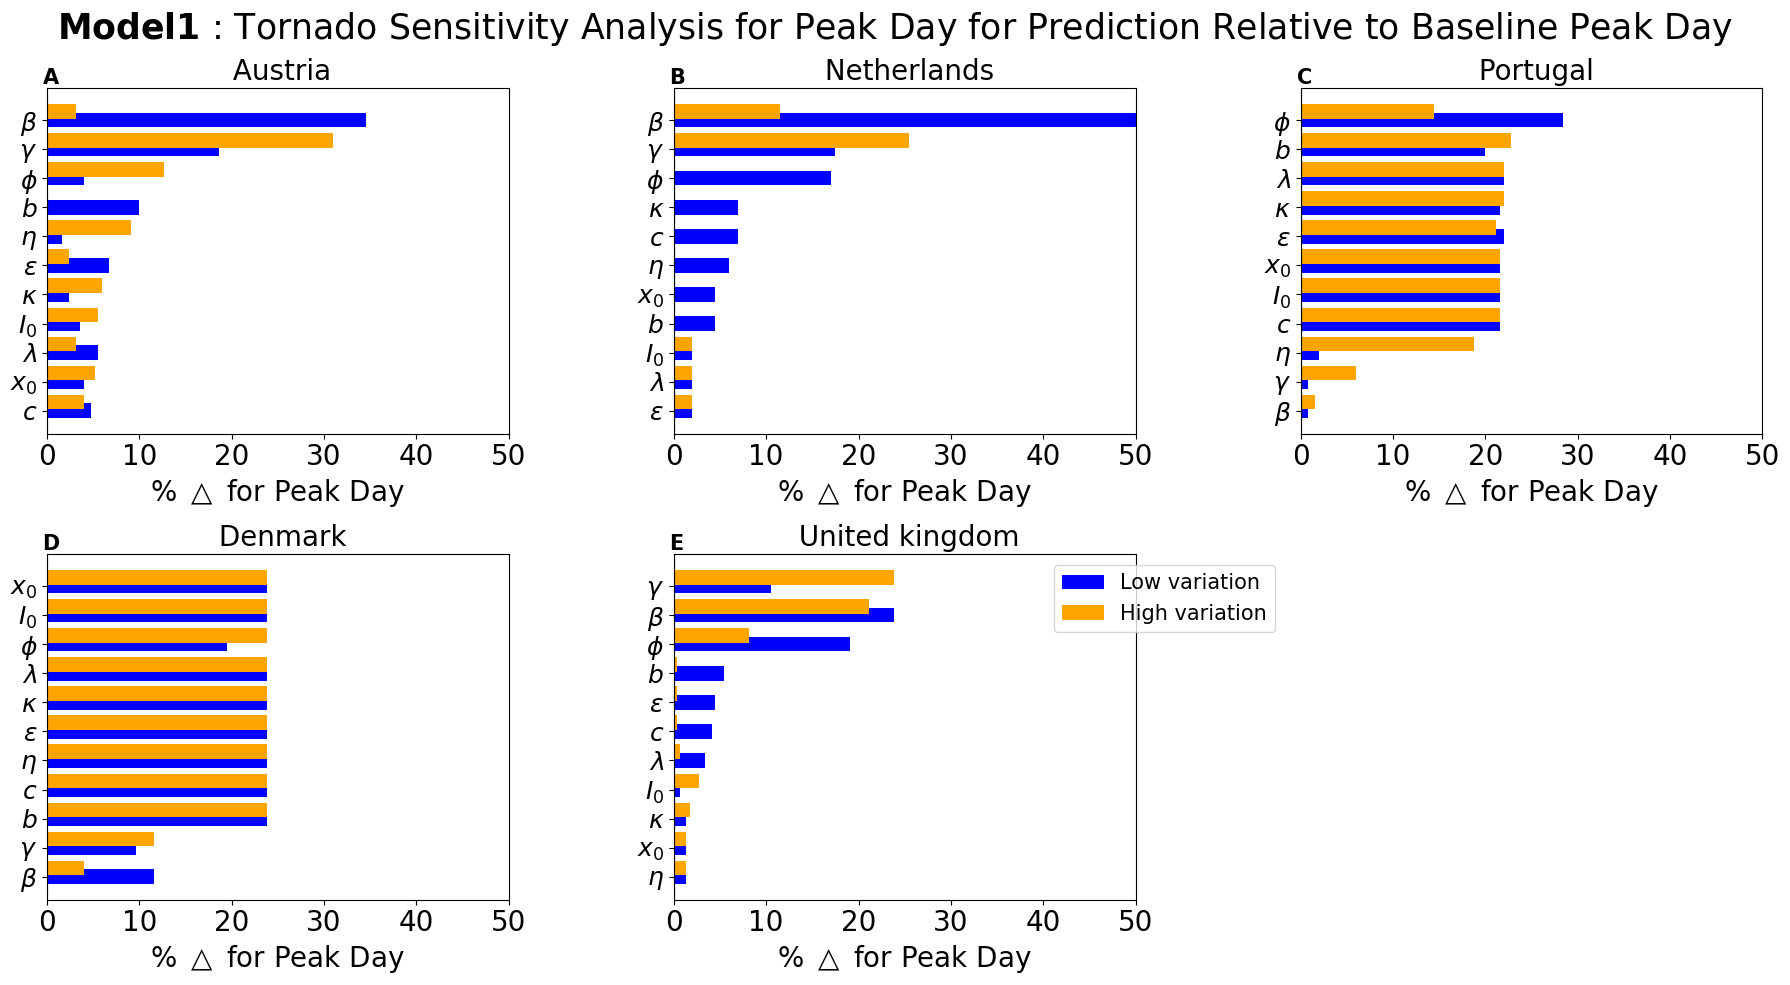

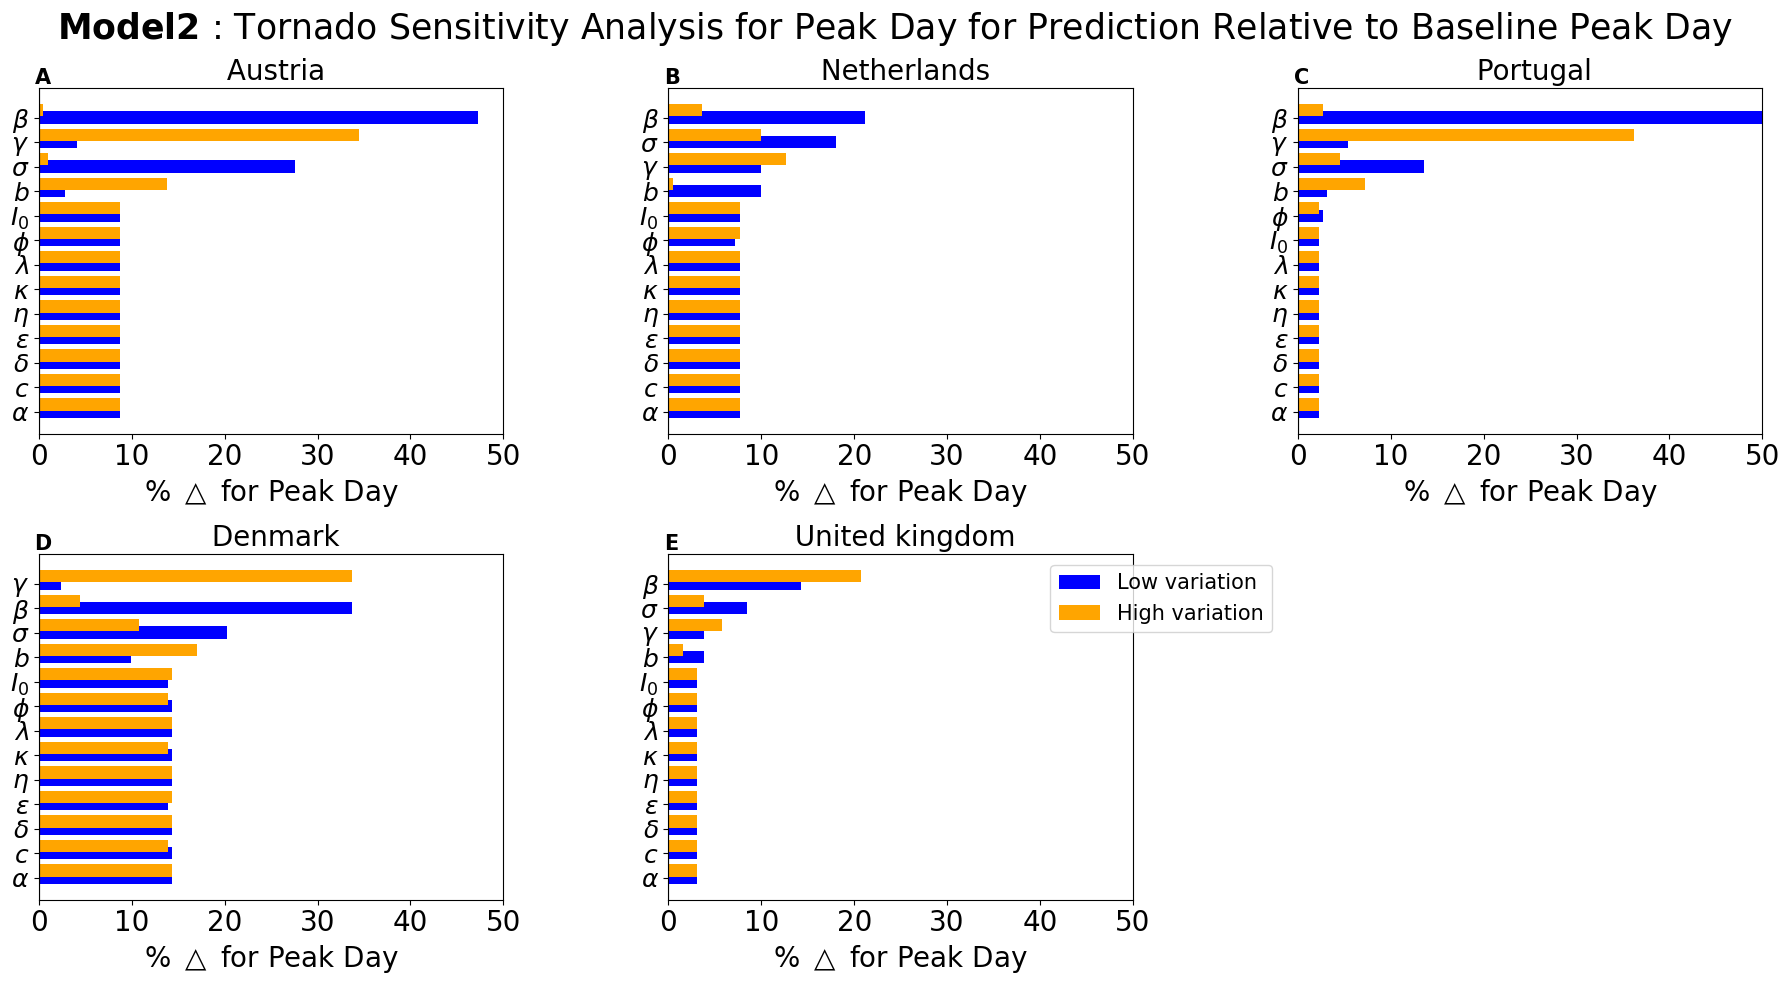

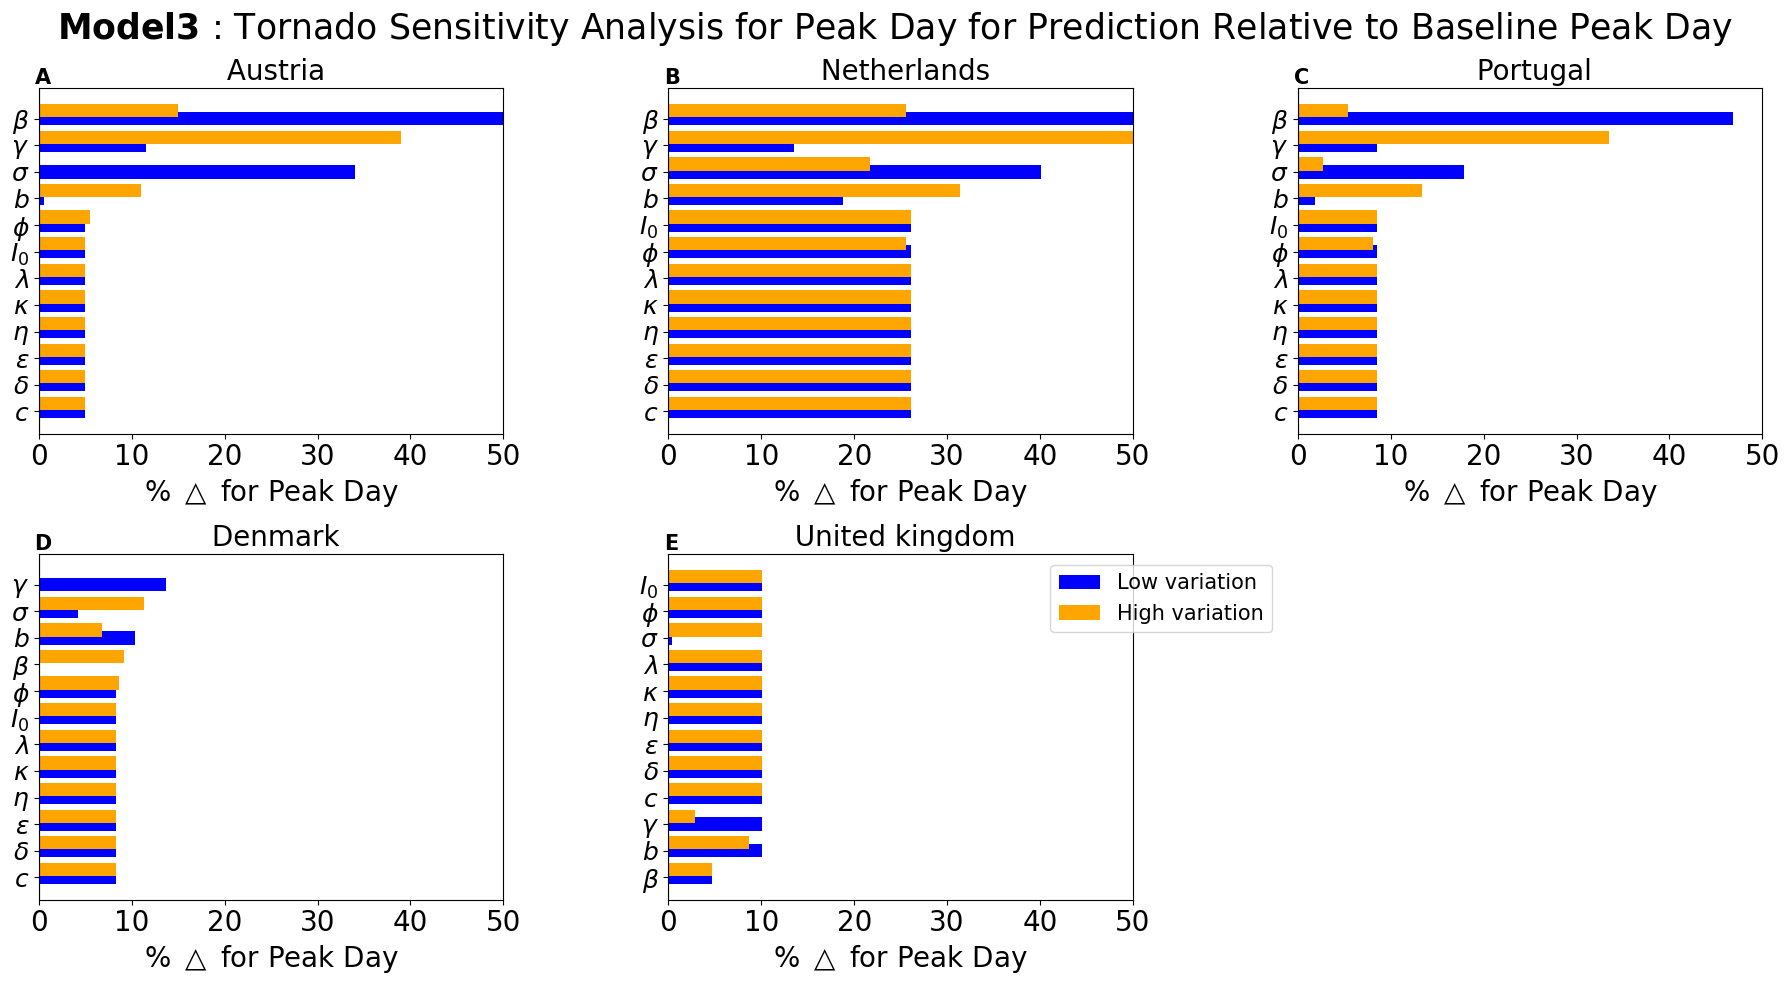

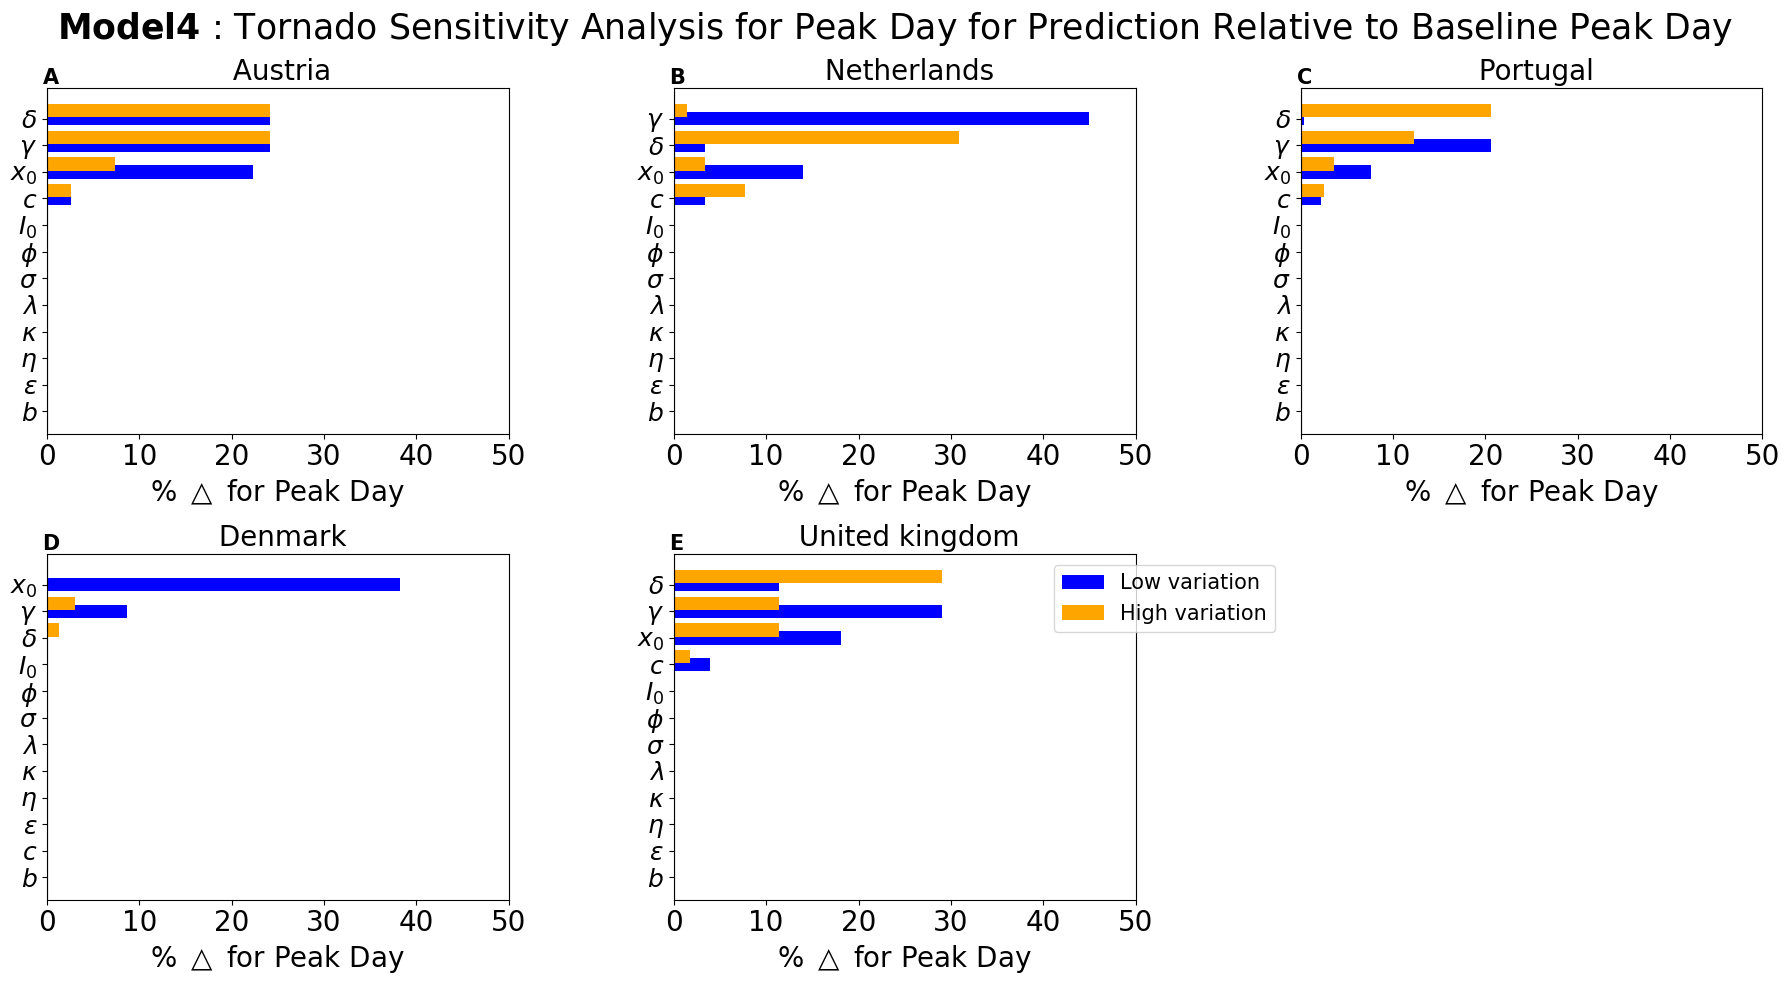

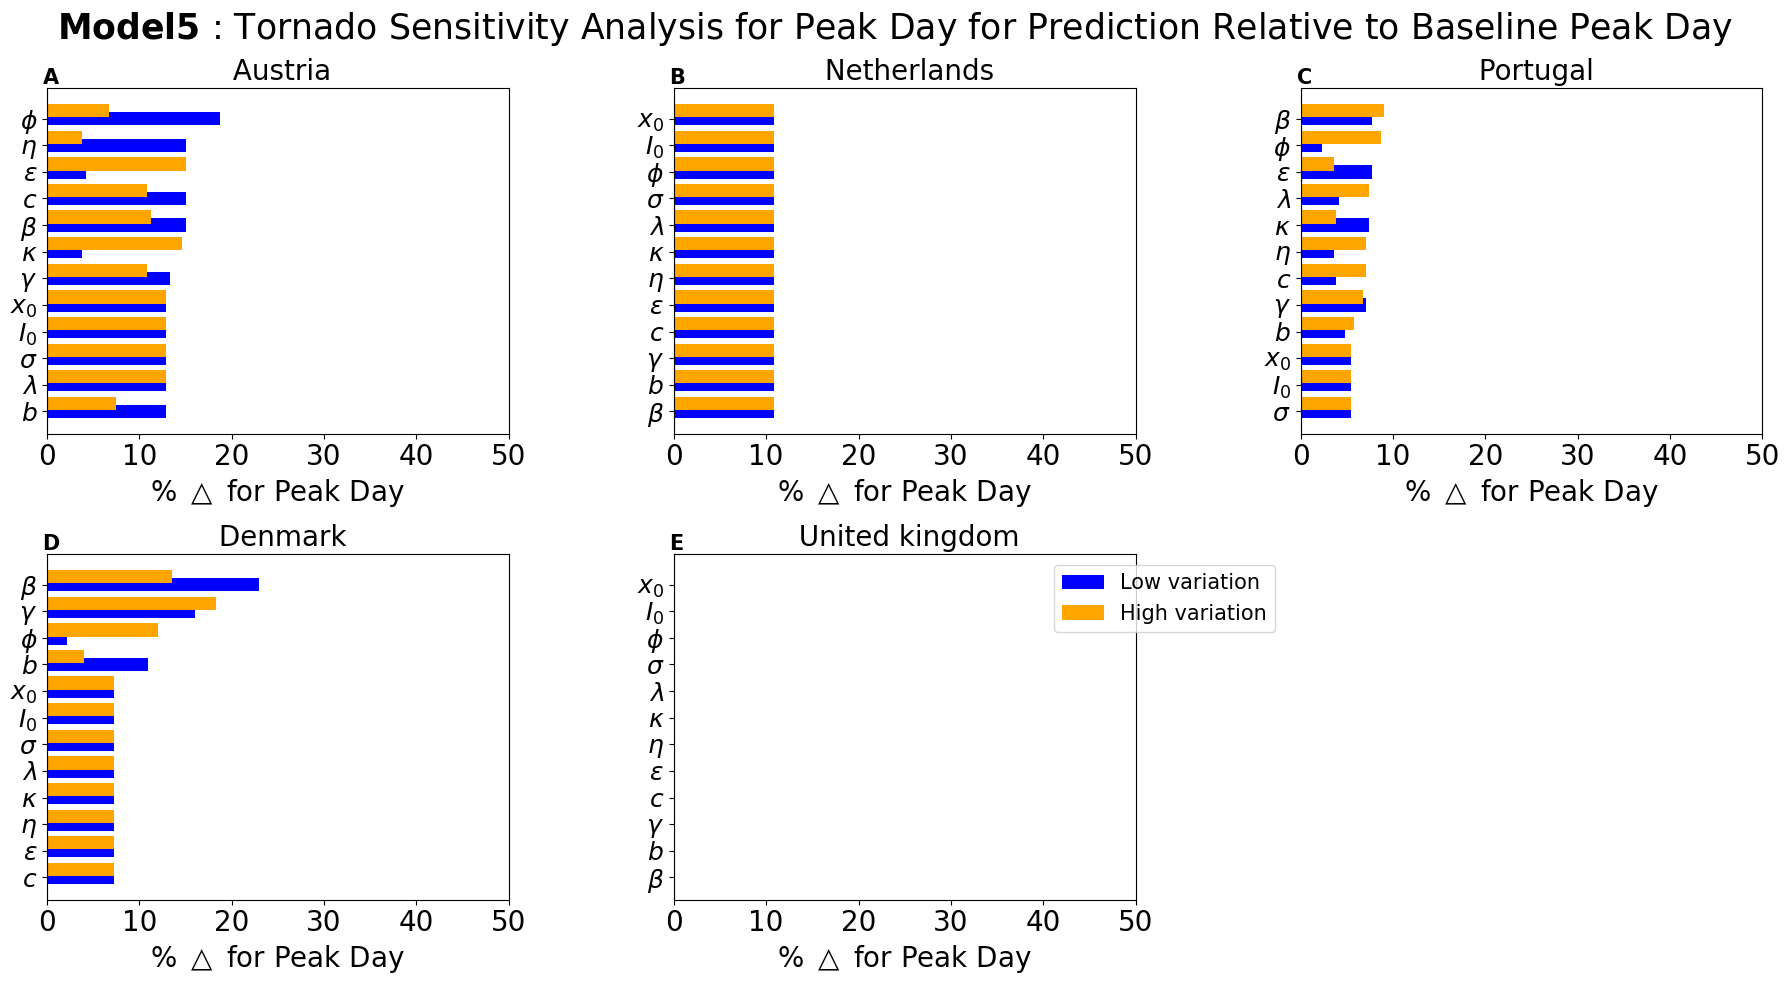

In [55]:
for mod in range(5):
    plt.figure(figsize=(18,10))
    Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'United Kingdom']
    Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
    for i in range(5):
        plt.subplot(2,3, i +1)
        tornado_plot_peak_time(PP[i][mod], Filenames[i].capitalize())
        plt.text(-0.01, 1.0, Labels[i], transform=plt.gca().transAxes, fontsize=15, va='bottom', ha='left',  color ="black")
    plt.legend(bbox_to_anchor=(0.80, 1.0), loc='upper left', fontsize = 15, ncols = 1)
    plt.suptitle(f"$\\mathbf{{{ModelName[mod]}}}$ : Tornado Sensitivity Analysis for Peak Day for Prediction Relative to Baseline Peak Day", fontsize = 25)
    plt.tight_layout()
    # plt.savefig(f"D{mod+1}_revised.png", dpi = 300)

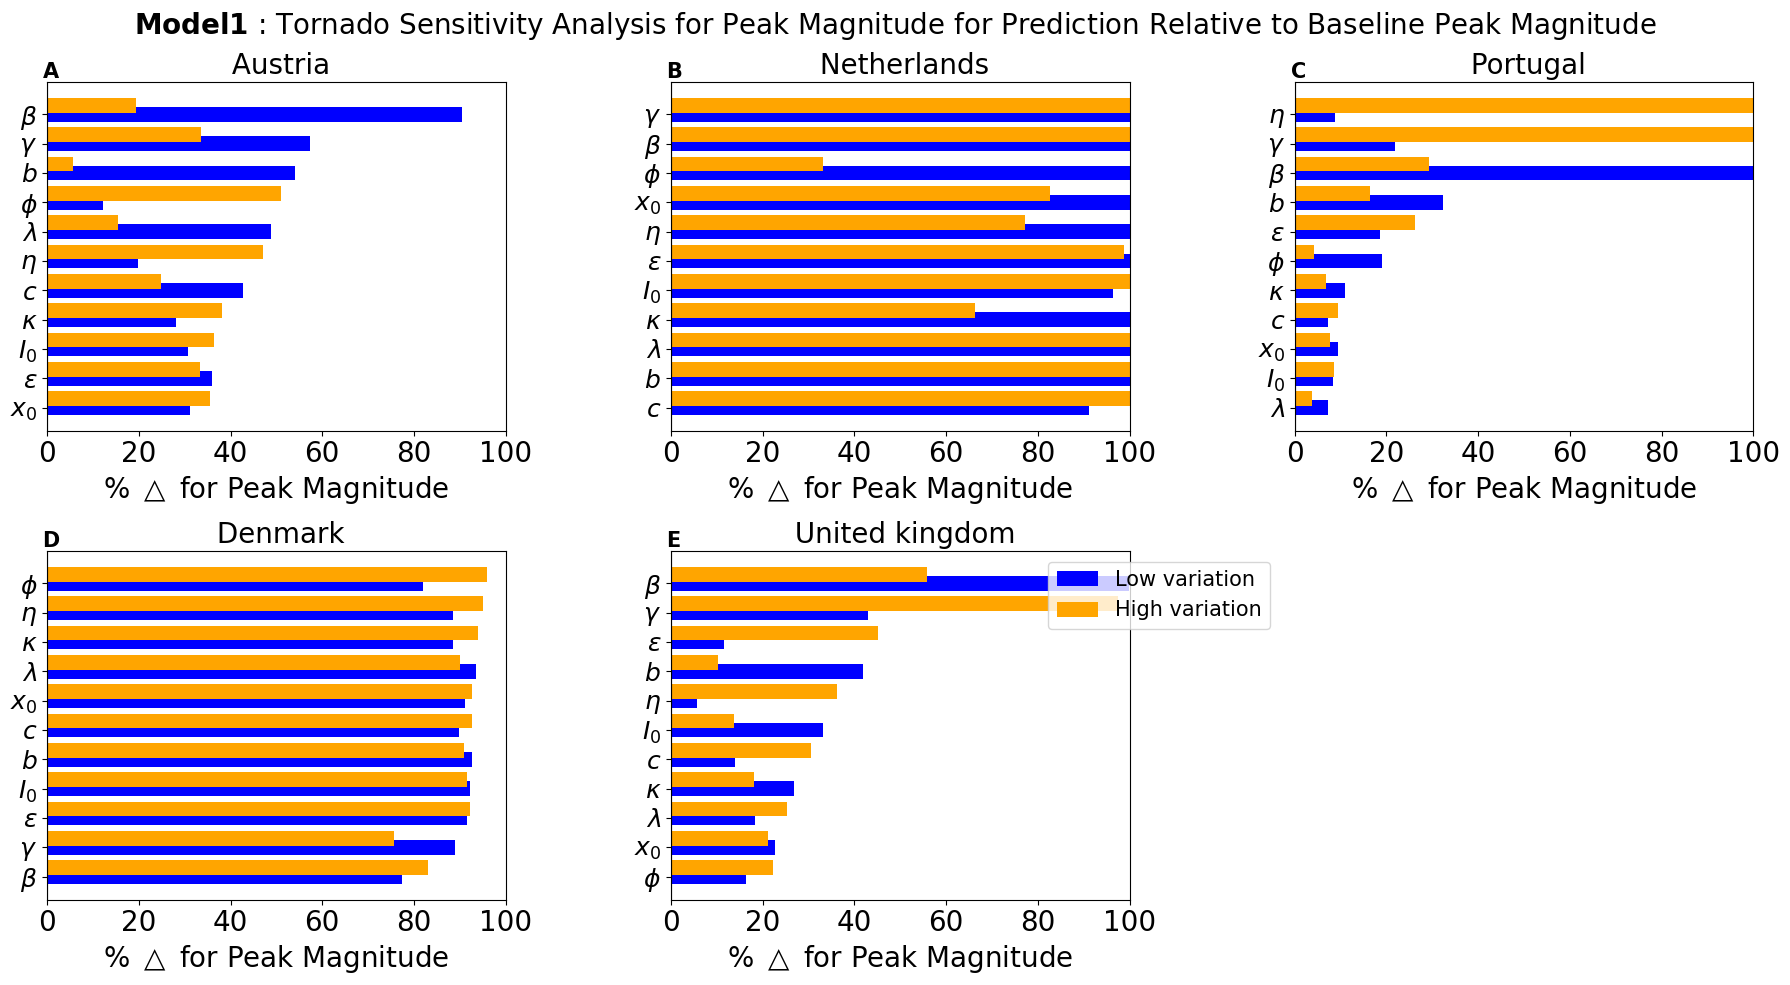

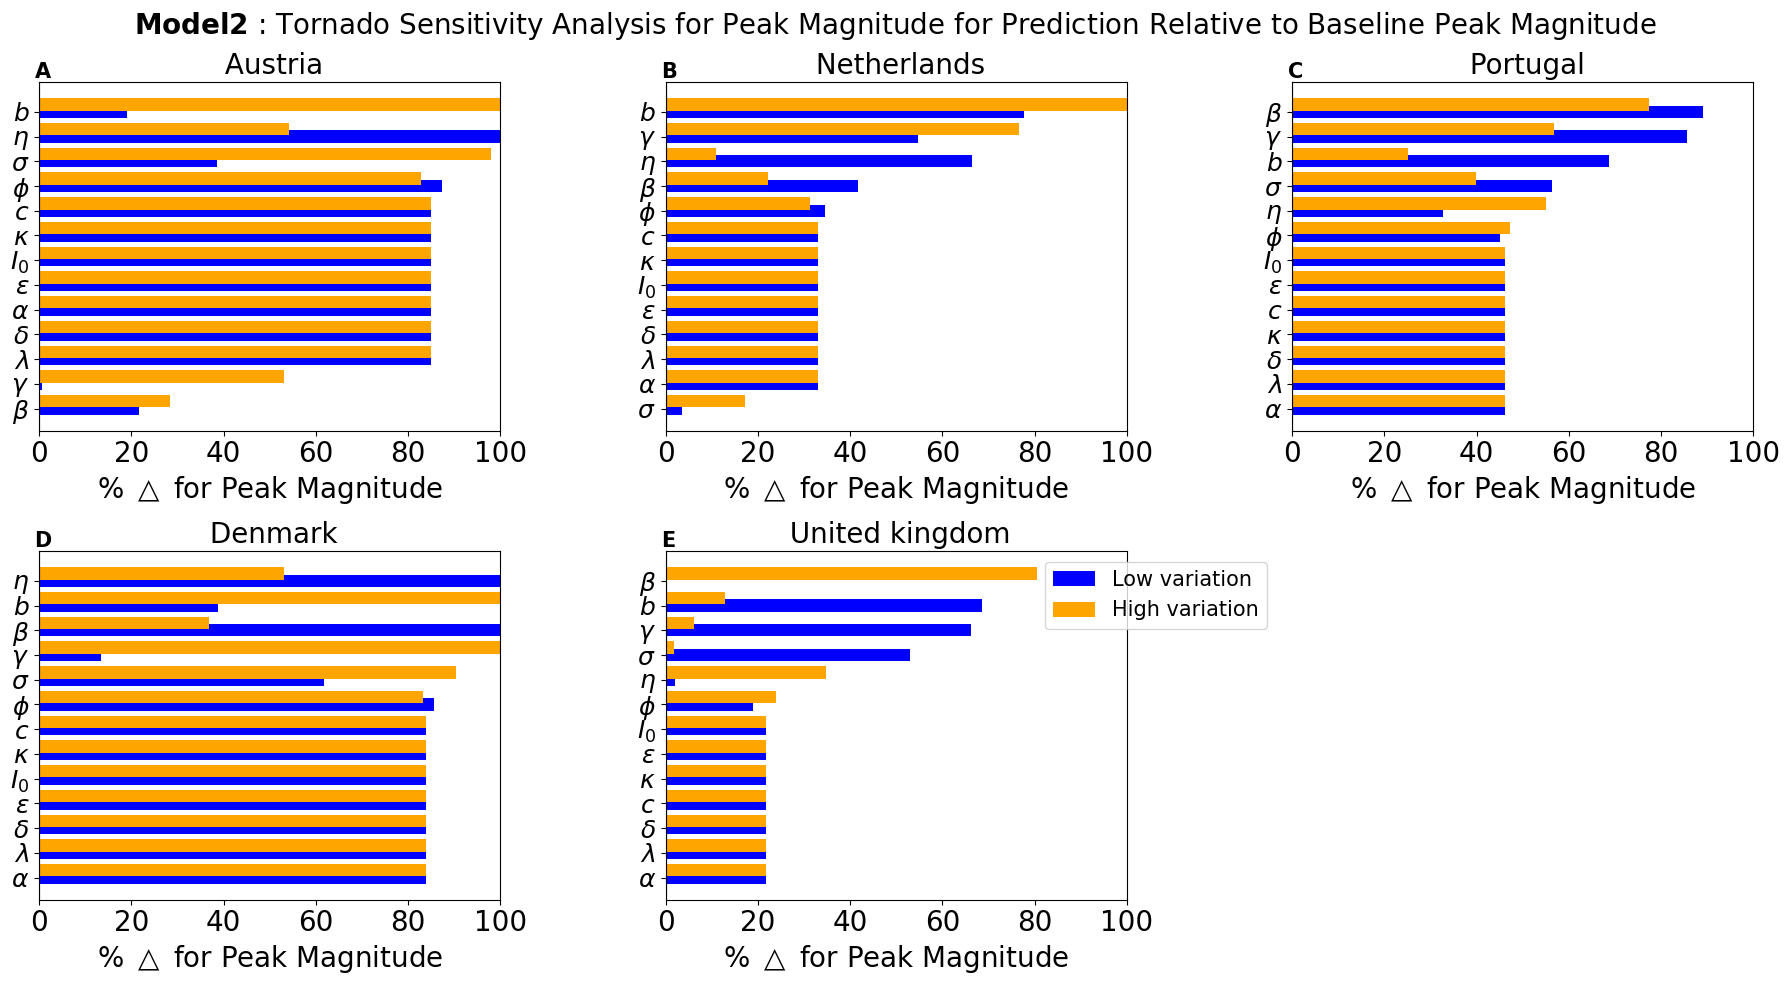

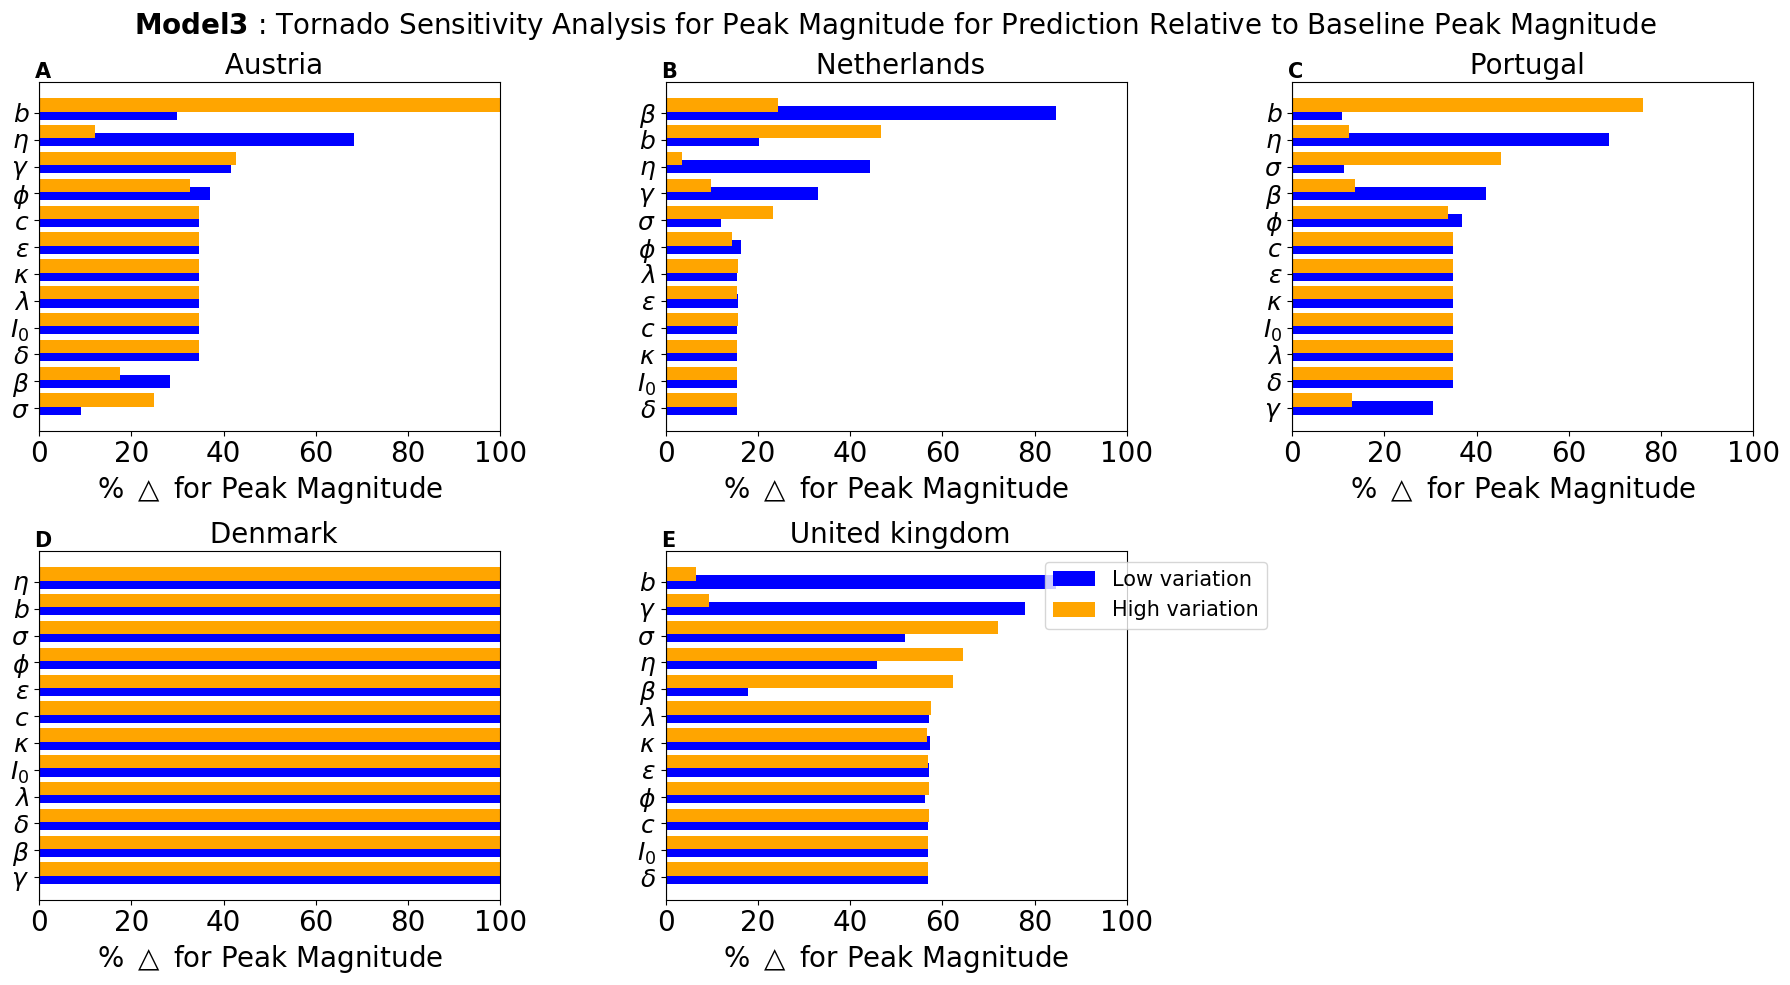

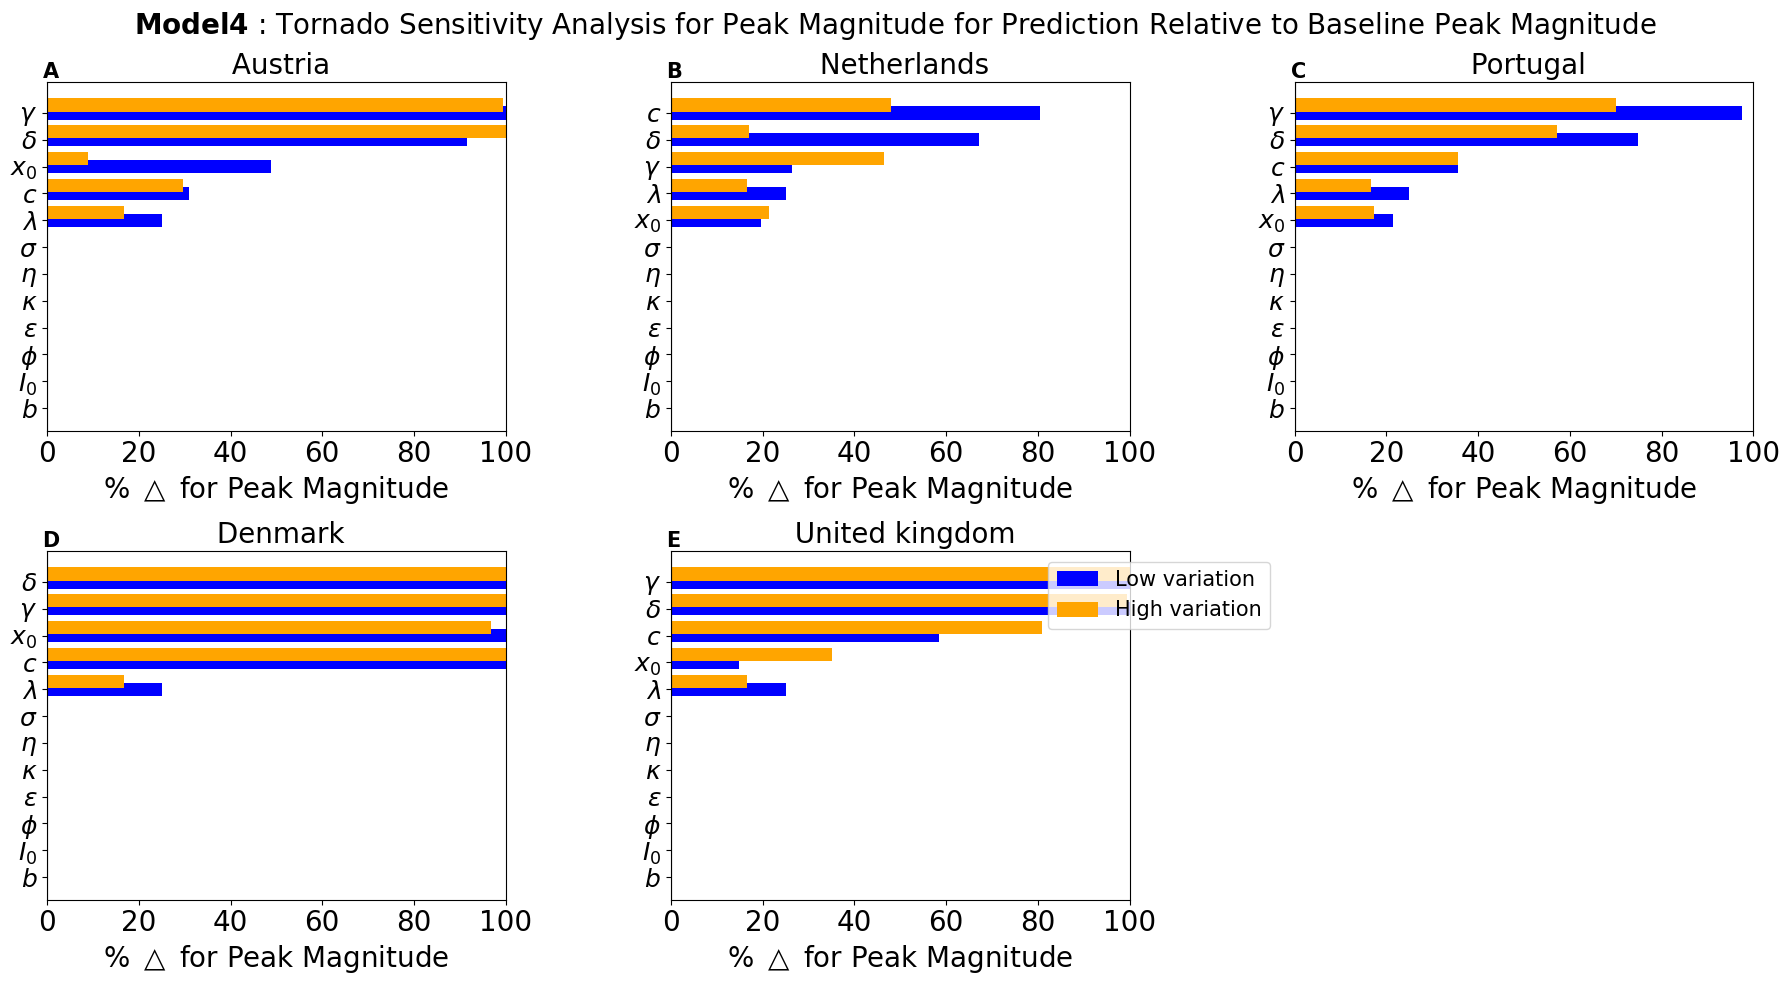

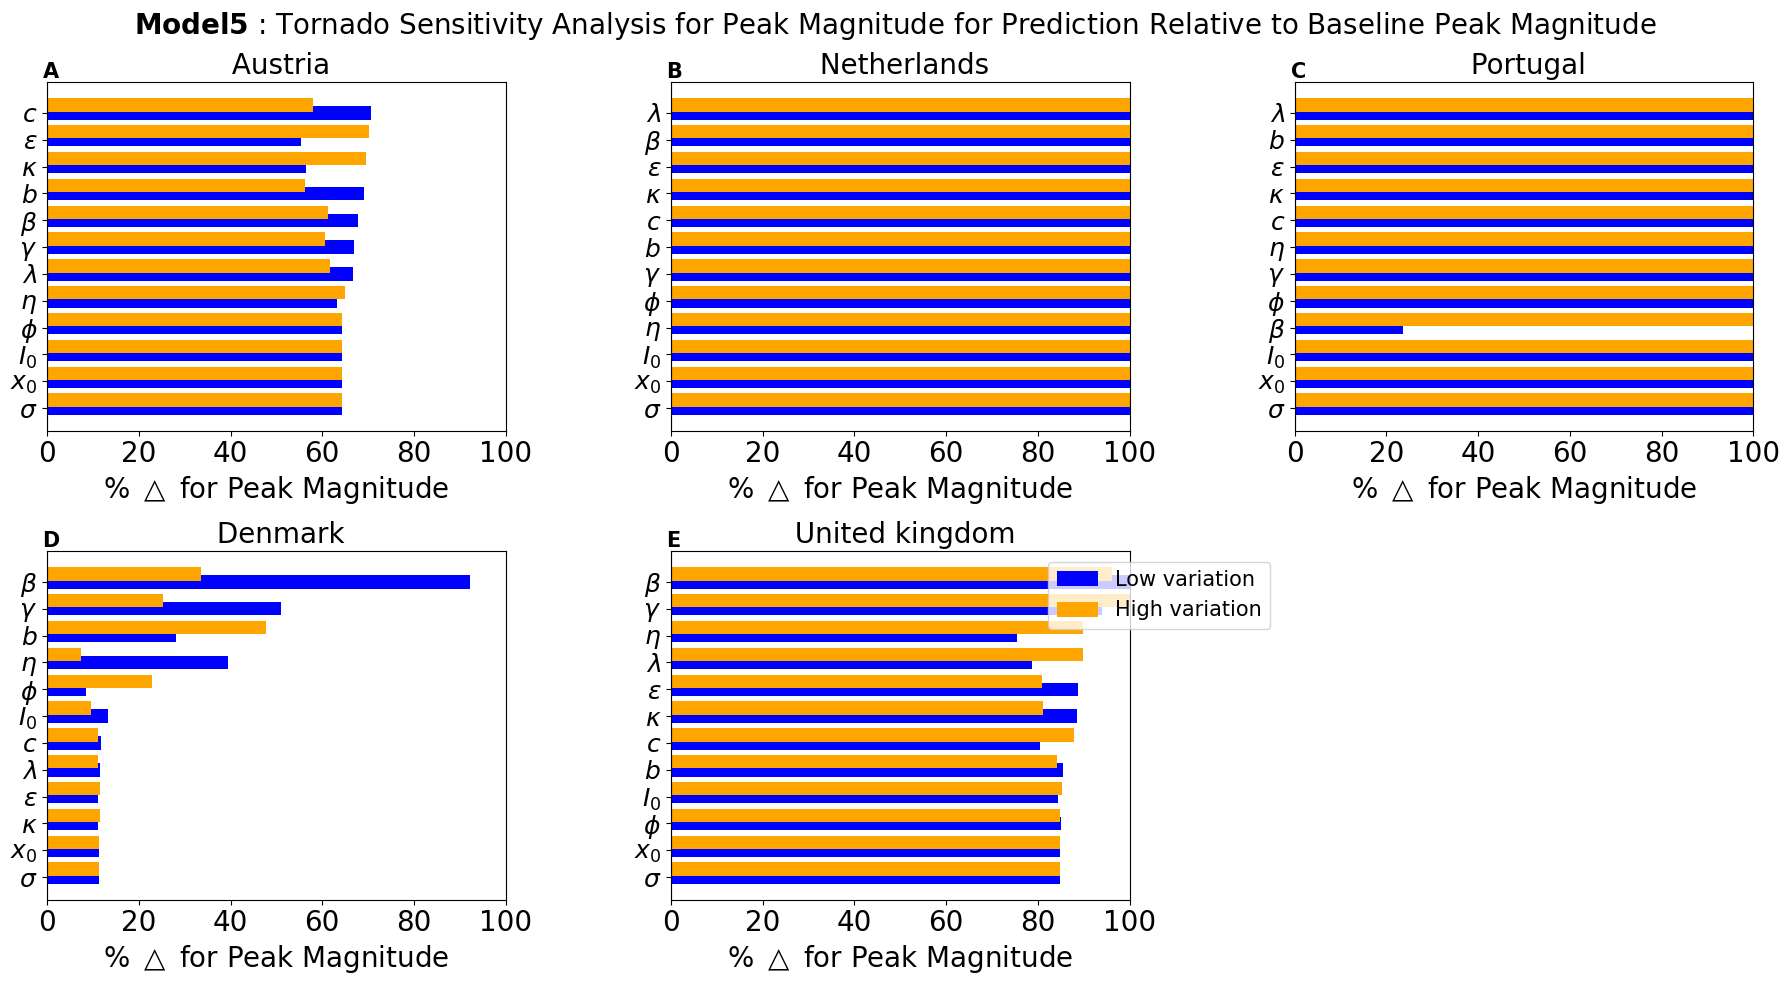

In [56]:
# tornado_plot(AA[4][0])
for mod in range(5):
    plt.figure(figsize=(18,10))
    Filenames = ['austria',  'netherlands' , 'portugal', 'denmark', 'United Kingdom']
    Labels = ["$\\mathbf{A}$", "$\\mathbf{B}$", "$\\mathbf{C}$", "$\\mathbf{D}$", "$\\mathbf{E}$", "$\\mathbf{F}$"]
    for i in range(5):
        plt.subplot(2,3, i +1)
        tornado_plot_peak(PP[i][mod], Filenames[i].capitalize())
        plt.text(-0.01, 1.0, Labels[i], transform=plt.gca().transAxes, fontsize=15, va='bottom', ha='left',  color ="black")
    plt.legend(bbox_to_anchor=(0.80, 1.0), loc='upper left', fontsize = 15, ncols = 1)
    plt.suptitle(f"$\\mathbf{{{ModelName[mod]}}}$ : Tornado Sensitivity Analysis for Peak Magnitude for Prediction Relative to Baseline Peak Magnitude", fontsize = 20)
    plt.tight_layout()
    # plt.savefig(f"M{mod+1}_revised.png", dpi = 300)